# 📚 Итоговый проект: гибридная система рекомендаций книг с нейросетевой моделью

**Датасет:** Goodbooks-10k (10 000 книг, 53 424 пользователя, ≈ 980 тыс. оценок). **Основа:** модели и протокол оценки из домашнего задания №1
(Popularity, контентная TF-IDF, Item-based CF, SVD) — они перенесены в пакет `recsys` (код записывается самим ноутбуком, раздел 0) без изменения логики, на том же сплите воспроизводят цифры ДЗ.

## Что построено
```
 данные ──► очистка, сплит ──► РАСШИРЕННЫЕ ПРИЗНАКИ ──► модели-источники кандидатов ─────────────┐
 (CSV)      train/test 80/20     пользователи, книги,       Popularity · Genre-Popularity         │
                                 жанры, взаимодействия      Content-based (TF-IDF)                ▼
                                                            Item-based CF · SVD · PureSVD     ОБЩИЙ ПУЛ КАНДИДАТОВ
                                                            Two-Tower (нейросеть)  ◄── НОВОЕ   (объединение top-40 каждой модели,
                                                                                              фильтрация прочитанного)
                                                                                                     │
        типы пользователей (новые / обычные / активные) ──► веса смеси ──► взвешенное усреднение ────┤
        обучаемый ранжировщик LightGBM на признаках ───────────────────────────────────────────────►─┤
                                                                                                     ▼
                                            баланс «релевантность ↔ разнообразие» (MMR) + слоты для новых книг ──► Top-N
```

## Содержание
| № | Раздел | Критерии задания |
|---|---|---|
| 0 | Код проекта, окружение и конфигурация | самодостаточность |
| 1 | Загрузка, очистка, сплит, типы пользователей | подготовка |
| 2 | **Этап 1.** Расширенные признаки пользователей, книг, взаимодействий | «Созданы расширенные признаки» |
| 3 | Модели из ДЗ №1 и **нейросеть Two-Tower**: обучение | «гибрид на основе моделей из ДЗ», продвинутая часть |
| 4 | **Этап 2.** Гибрид: пул кандидатов, веса по типам пользователей, баланс (MMR), ранжировщик | «стратегия объединения / балансировки» |
| 5 | **Этап 3.** Оценка: метрики, сегменты, вклад компонентов, анализ | «Анализ эффективности», «Метрики» |
| 6 | Нейросеть: эффективность против классики, холодный старт книг | «Интеграция в гибрид, анализ» |
| 7 | Сквозной пайплайн и повторный запуск на новых данных | «Сквозной пайплайн» |
| 8 | Выводы, сильные и слабые стороны, рекомендации по выбору модели | «Содержательные выводы» |

> ⏱ Полный прогон ноутбука ≈ 40–50 минут на CPU (22 ядра). Все случайные процессы зафиксированы (`seed = 42`). Те же этапы запускаются одной командой `python run_pipeline.py` (файл создаётся ноутбуком, см. раздел 7).

## 0. Код проекта и окружение

**Ноутбук самодостаточен:** единственное, что нужно кроме него, — датасет Goodbooks-10k в папке `data/` (см. README). Ячейки ниже (свёрнуты, исходный код раскрывается по клику)
записывают модули пакета `recsys` в `src/recsys/` — это и есть «хорошо структурированный код»: данные и признаки (`data.py`, `features.py`), метрики (`metrics.py`), модели из ДЗ №1 (`models/classic.py`),
нейросеть (`models/two_tower.py`), гибрид (`hybrid.py`, `ranker.py`), сквозной пайплайн (`pipeline.py`), графики (`plots.py`) и CLI `run_pipeline.py`.
Дальше ноутбук только вызывает этот код этап за этапом и комментирует результаты.

In [1]:
from pathlib import Path
for d in ("src/recsys/models", "data"):
    Path(d).mkdir(parents=True, exist_ok=True)
missing = [f for f in ("books.csv", "ratings.csv", "tags.csv", "book_tags.csv") if not Path("data", f).exists()]
assert not missing, f"Положите файлы датасета Goodbooks-10k в папку data/: не найдены {missing}"
print("датасет найден: data/ ✓")

датасет найден: data/ ✓


In [2]:
%%writefile src/recsys/__init__.py
"""Гибридная система рекомендаций книг (Goodbooks-10k): классические модели + нейросеть Two-Tower."""
__version__ = "1.0.0"

Writing src/recsys/__init__.py


In [3]:
%%writefile src/recsys/config.py
"""Единая конфигурация проекта.

Все «ручки» пайплайна собраны в одном датаклассе, чтобы запуск на новых данных сводился к
`Config(data_dir="новые_данные")` (или флагу `--data-dir` в `run_pipeline.py`).
"""
from __future__ import annotations

import json
from dataclasses import asdict, dataclass, field
from pathlib import Path


@dataclass
class Config:
    # ---------- данные и протокол оценки (совпадают с ДЗ №1, чтобы результаты были сопоставимы) ----------
    data_dir: str = "data"
    out_dir: str = "outputs"
    seed: int = 42
    relevance_threshold: int = 4          # оценка >= 4  =>  книга «понравилась» / релевантна
    test_frac: float = 0.2                # доля оценок каждого пользователя в hold-out
    ks: tuple = (5, 10, 20)               # K для Precision/Recall/nDCG
    main_k: int = 10
    sample_users: int | None = None       # None = все пользователи; число = случайная подвыборка (быстрый режим)

    # ---------- сегменты пользователей по длине истории в train ----------
    # новые: < 5 оценок, обычные: 5–19, активные: >= 20
    segment_bounds: tuple = (5, 20)
    segment_names: tuple = ("новые (<5)", "обычные (5–19)", "активные (≥20)")

    # ---------- модели из ДЗ №1 ----------
    min_ratings_pop: int = 50             # порог числа оценок для Popularity
    knn_grid_k: tuple = (10, 20, 50)
    knn_feedback: tuple = ("like", "seen")
    svd_params: dict = field(default_factory=lambda: dict(n_factors=100, n_epochs=30, lr_all=0.01, reg_all=0.1))
    svd_grid: dict = field(default_factory=lambda: dict(n_factors=(50, 100), lr_all=(0.01,), reg_all=(0.05, 0.1, 0.15)))
    psvd_grid: tuple = (200, 400, 600, 800)
    cold_item_min: int = 5                # книги с < N оценок в train считаются «новыми» (для них CF бессилен)

    # ---------- нейросеть Two-Tower ----------
    tt_dim: int = 96                      # размерность общего пространства эмбеддингов
    tt_hidden: int = 256
    tt_id_dim: int = 96                   # размер ID-эмбеддинга книги
    tt_hist_dim: int = 96                 # размер эмбеддинга книги во «входной» истории пользователя
    tt_epochs: int = 30                   # «эпоха» = один проход со случайным скрытием целей (см. two_tower.py)
    tt_target_frac: float = 0.35          # доля понравившихся книг, скрываемых как цели на каждой эпохе
    tt_batch: int = 1024
    tt_lr: float = 2e-3
    tt_temperature: float = 0.07
    tt_dropout: float = 0.05
    tt_hist_dropout: float = 0.05        # доля элементов истории, случайно скрываемых при обучении
    tt_id_dropout: float = 0.1            # вероятность «выключить» ID книги (учит башню опираться на признаки)
    tt_weight_decay: float = 1e-6
    tt_extra_neg: int = 1024              # равномерные негативы сверх внутрибатчевых

    # ---------- гибрид ----------
    pool_per_model: int = 40              # сколько кандидатов вносит в общий пул каждая модель
    pool_norm: str = "pool"               # нормировка оценок моделей: "pool" (z-score внутри пула кандидатов) | "catalog" (по всему каталогу)
    hybrid_components: tuple = ("knn", "content", "svd", "psvd", "tt", "pop", "gpop")
    weight_search_iters: int = 400        # итераций случайного поиска + координатного спуска
    mmr_pool: int = 40                    # из скольких лучших кандидатов выбираем итоговый список в MMR
    mmr_lambdas: tuple = (1.0, 0.95, 0.9, 0.85, 0.8, 0.7, 0.6, 0.5)
    mmr_max_rel_loss: float = 0.02        # допускаем потерю nDCG не более 2 % ради разнообразия
    cold_slots: int = 1                   # слоты в выдаче для «новых» книг без оценок (контентная модель)

    # ---------- обучаемый ранжировщик (LightGBM LambdaRank) ----------
    ltr_users: int = 20000                # сколько validation-пользователей идёт в обучение ранжировщика
    ltr_rounds: int = 300

    # ---------- размеры выборок для подбора гиперпараметров ----------
    n_val_users: int = 8000
    n_ltr_eval_users: int = 6000

    # ---------- служебное ----------
    fast: bool = False                    # быстрый режим: меньше эпох, меньше сеток, подвыборка
    tune: bool = True                     # False = использовать сохранённые параметры из out_dir/best_params.json
    verbose: bool = True

    def apply_fast(self) -> "Config":
        """Быстрый режим для проверки пайплайна на новых/маленьких данных (минуты вместо десятков минут)."""
        self.fast = True
        self.tt_epochs = min(self.tt_epochs, 8)
        self.knn_grid_k = (10, 20)
        self.svd_grid = dict(n_factors=(50,), lr_all=(0.01,), reg_all=(0.1,))
        self.psvd_grid = (100, 200)
        self.weight_search_iters = 120
        self.ltr_users = 6000
        self.ltr_rounds = 120
        self.n_val_users = 3000
        self.n_ltr_eval_users = 3000
        self.mmr_lambdas = (1.0, 0.9, 0.8, 0.7)
        return self

    def to_json(self, path: str | Path) -> None:
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        Path(path).write_text(json.dumps(asdict(self), ensure_ascii=False, indent=2), encoding="utf-8")

    @property
    def list_len(self) -> int:
        return max(self.ks)

Writing src/recsys/config.py


In [4]:
%%writefile src/recsys/data.py
"""Загрузка, очистка, индексация данных и разбиение train/test (этап «загрузка данных → предобработка»).

Протокол полностью повторяет ДЗ №1 (per-user hold-out 80/20, seed 42, релевантность = оценка >= 4),
поэтому цифры базовых моделей можно напрямую сравнивать с результатами домашнего задания.
"""
from __future__ import annotations

from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp

from .config import Config

REQUIRED_FILES = ("books.csv", "ratings.csv", "tags.csv", "book_tags.csv")


# ----------------------------------------------------------------------------------------------
# Загрузка
# ----------------------------------------------------------------------------------------------
@dataclass
class Data:
    """Очищенные и проиндексированные данные.

    * ``book_id``  — ключ из ``ratings.csv`` (1…10000);
    * ``goodreads_book_id`` — ключ из ``book_tags.csv``;
    * ``u`` / ``i`` — компактные индексы строк/столбцов матрицы «пользователь × книга».
    """
    books: pd.DataFrame
    ratings: pd.DataFrame
    tags: pd.DataFrame
    book_tags: pd.DataFrame
    user_ids: np.ndarray
    book_ids: np.ndarray
    to_read: pd.DataFrame | None = None
    info: dict = field(default_factory=dict)

    @property
    def n_users(self) -> int:
        return len(self.user_ids)

    @property
    def n_items(self) -> int:
        return len(self.book_ids)

    def book_index(self, book_id) -> int:
        return int(np.searchsorted(self.book_ids, book_id))

    def user_index(self, user_id) -> int | None:
        """Индекс пользователя по исходному user_id (None — пользователя нет в данных = холодный старт)."""
        u = int(np.searchsorted(self.user_ids, user_id))
        return u if u < self.n_users and self.user_ids[u] == user_id else None


def load_raw(data_dir: str | Path) -> dict[str, pd.DataFrame]:
    """Читает CSV датасета Goodbooks-10k. ``to_read.csv`` необязателен."""
    data_dir = Path(data_dir)
    missing = [f for f in REQUIRED_FILES if not (data_dir / f).exists()]
    if missing:
        raise FileNotFoundError(f"В {data_dir.resolve()} не найдены файлы: {missing}. "
                                f"Нужны: {REQUIRED_FILES} (формат Goodbooks-10k).")
    raw = {f[:-4]: pd.read_csv(data_dir / f) for f in REQUIRED_FILES}
    if (data_dir / "to_read.csv").exists():
        raw["to_read"] = pd.read_csv(data_dir / "to_read.csv")
    return raw


def _resolve_book_keys(books: pd.DataFrame, ratings: pd.DataFrame) -> pd.DataFrame:
    """Приводит ключи книг к схеме ``book_id`` (для ratings) / ``goodreads_book_id`` (для book_tags).

    В «каноничной» версии датасета (GitHub) эти колонки уже есть. В версии Kaggle колонки называются ``id`` и
    ``book_id`` и их смысл нужно определить: правильный ключ даёт высокую корреляцию средней оценки из
    ratings.csv со столбцом ``average_rating`` из books.csv.
    """
    if "goodreads_book_id" in books.columns:
        return books
    if "id" not in books.columns:
        raise ValueError("Не удалось определить ключи книг: нет ни goodreads_book_id, ни id.")
    mean_by_book = ratings.groupby("book_id")["rating"].mean().rename("m")
    corr = {}
    for key in ("id", "book_id"):
        j = books.set_index(key)["average_rating"].to_frame().join(mean_by_book, how="inner")
        corr[key] = j.corr().iloc[0, 1] if len(j) > 10 else -1
    if corr["id"] <= corr["book_id"]:
        raise ValueError(f"Ключ ratings.book_id не похож на books.id (корреляции: {corr}).")
    return books.rename(columns={"book_id": "goodreads_book_id", "id": "book_id"})


def prepare(raw: dict[str, pd.DataFrame], cfg: Config) -> Data:
    """Очистка (дубликаты, «осиротевшие» оценки), подвыборка пользователей (опц.) и индексация."""
    books = _resolve_book_keys(raw["books"].copy(), raw["ratings"])
    books = books.sort_values("book_id").reset_index(drop=True)

    ratings_raw = raw["ratings"][["user_id", "book_id", "rating"]].copy()
    n_raw = len(ratings_raw)
    if cfg.sample_users:                                              # быстрый режим / «новые данные»
        rng = np.random.default_rng(cfg.seed)
        users = np.sort(ratings_raw["user_id"].unique())
        keep = rng.choice(users, size=min(cfg.sample_users, len(users)), replace=False)
        ratings_raw = ratings_raw[ratings_raw["user_id"].isin(keep)]

    n_dups = int(ratings_raw.duplicated(["user_id", "book_id"]).sum())
    ratings = ratings_raw.drop_duplicates(["user_id", "book_id"], keep="last").reset_index(drop=True)   # как в ДЗ №1
    orphan = ~ratings["book_id"].isin(books["book_id"])
    n_orphan = int(orphan.sum())
    ratings = ratings[~orphan].reset_index(drop=True)
    ratings = ratings[ratings["rating"].between(1, 5)].reset_index(drop=True)

    user_ids = np.sort(ratings["user_id"].unique())
    book_ids = books["book_id"].to_numpy()
    assert (np.diff(book_ids) > 0).all(), "book_id должны быть уникальны"
    ratings["u"] = np.searchsorted(user_ids, ratings["user_id"])
    ratings["i"] = np.searchsorted(book_ids, ratings["book_id"])

    to_read = None
    if "to_read" in raw:
        tr = raw["to_read"]
        to_read = tr[tr["user_id"].isin(user_ids) & tr["book_id"].isin(book_ids)].copy()
        to_read["u"] = np.searchsorted(user_ids, to_read["user_id"])
        to_read["i"] = np.searchsorted(book_ids, to_read["book_id"])

    data = Data(books=books, ratings=ratings, tags=raw["tags"], book_tags=raw["book_tags"],
                user_ids=user_ids, book_ids=book_ids, to_read=to_read)
    data.info = dict(raw_rows=n_raw, duplicates_removed=n_dups, orphans_removed=n_orphan,
                     n_ratings=len(ratings), n_users=len(user_ids), n_items=len(book_ids),
                     density=len(ratings) / (len(user_ids) * len(book_ids)))
    return data


# ----------------------------------------------------------------------------------------------
# Разбиение и матрицы
# ----------------------------------------------------------------------------------------------
def per_user_split(df: pd.DataFrame, test_frac: float, seed: int):
    """Случайный hold-out внутри каждого пользователя: floor(test_frac · n_u), но не меньше 1 и не больше n_u − 1.

    Временной метки в данных нет, поэтому временной сплит невозможен. Реализация векторная (ранги внутри группы).
    """
    rnd = pd.Series(np.random.default_rng(seed).random(len(df)), index=df.index)
    rank_in_user = rnd.groupby(df["u"]).rank(method="first")
    n_u = df.groupby("u")["i"].transform("size")
    is_test = (rank_in_user <= np.maximum(1, np.floor(test_frac * n_u))) & (n_u >= 2)
    return df[~is_test].copy(), df[is_test].copy()


def build_matrix(df: pd.DataFrame, n_users: int, n_items: int, values: str | None = None) -> sp.csr_matrix:
    """CSR-матрица (n_users × n_items); values=None → бинарная."""
    data = np.ones(len(df), dtype=np.float32) if values is None else df[values].to_numpy(dtype=np.float32)
    return sp.csr_matrix((data, (df["u"].to_numpy(), df["i"].to_numpy())), shape=(n_users, n_items))


@dataclass
class Split:
    """Один сплит: обучающая часть + отложенная; все нужные матрицы строятся сразу.

    * ``R``       — явные оценки;               * ``R_seen``  — «пользователь взаимодействовал с книгой»;
    * ``R_like``  — оценка >= порога;            * ``R_other`` — оценка ниже порога (прочитал, но не понравилось);
    * ``rel``     — релевантные отложенные книги (то, что нужно угадать).
    """
    train_df: pd.DataFrame
    test_df: pd.DataFrame
    n_users: int
    n_items: int
    threshold: int = 4

    def __post_init__(self):
        liked = self.train_df[self.train_df.rating >= self.threshold]
        self.R = build_matrix(self.train_df, self.n_users, self.n_items, "rating")
        self.R_seen = build_matrix(self.train_df, self.n_users, self.n_items)
        self.R_like = build_matrix(liked, self.n_users, self.n_items)
        self.R_other = (self.R_seen - self.R_like).tocsr()
        self.rel = build_matrix(self.test_df[self.test_df.rating >= self.threshold], self.n_users, self.n_items)
        self.eval_users = np.flatnonzero(np.diff(self.rel.indptr) > 0)
        self.item_support = np.asarray(self.R_seen.sum(axis=0)).ravel()
        self.user_support = np.diff(self.R_seen.indptr)


def make_splits(data: Data, cfg: Config) -> tuple[Split, Split]:
    """outer = (train, test) — финальная оценка; inner = (train_inner, val) — подбор гиперпараметров и весов гибрида."""
    train, test = per_user_split(data.ratings, cfg.test_frac, cfg.seed)
    train_inner, val = per_user_split(train, cfg.test_frac, cfg.seed + 1)

    key = lambda d: d["u"].to_numpy().astype(np.int64) * data.n_items + d["i"].to_numpy()
    assert not np.intersect1d(key(train), key(test)).size, "утечка: пары (user, book) пересекаются"
    assert not np.intersect1d(key(train_inner), key(val)).size
    assert len(train) + len(test) == len(data.ratings)

    outer = Split(train, test, data.n_users, data.n_items, cfg.relevance_threshold)
    inner = Split(train_inner, val, data.n_users, data.n_items, cfg.relevance_threshold)
    return outer, inner


def user_segments(user_support: np.ndarray, bounds=(5, 20)) -> np.ndarray:
    """Тип пользователя по длине истории: 0 — новый (< b0), 1 — обычный, 2 — активный (>= b1)."""
    return np.digitize(user_support, bounds)

Writing src/recsys/data.py


In [5]:
%%writefile src/recsys/metrics.py
"""Метрики качества: Precision@K, Recall@K, nDCG@K (векторные) + метрики разнообразия/новизны.

Определения (для пользователя u, списка рекомендаций длины K, rel_k ∈ {0,1}, R_u — релевантные отложенные книги):

    Precision@K = Σ_{k≤K} rel_k / K                      Recall@K = Σ_{k≤K} rel_k / |R_u|
    DCG@K  = Σ_{k≤K} rel_k / log2(k+1)                   nDCG@K = DCG@K / IDCG@K,  IDCG@K = Σ_{k≤min(K,|R_u|)} 1/log2(k+1)

Метрики считаются по каждому пользователю и усредняются (macro-average).
"""
from __future__ import annotations

from dataclasses import dataclass

import numpy as np
import pandas as pd
import scipy.sparse as sp


# ----------------------------------------------------------------------------------------------
# Top-K и метрики точности
# ----------------------------------------------------------------------------------------------
def top_k(scores: np.ndarray, seen: sp.csr_matrix | None, k: int) -> np.ndarray:
    """Индексы k книг с наибольшим score для каждой строки; уже виденные книги (seen — CSR) исключаются (фильтрация прочитанного)."""
    scores = np.array(scores, dtype=np.float32)                   # копия: исходный массив (может быть read-only) не портим
    if seen is not None:
        rows = np.repeat(np.arange(seen.shape[0]), np.diff(seen.indptr))
        scores[rows, seen.indices] = -np.inf
    part = np.argpartition(-scores, k, axis=1)[:, :k]
    order = np.argsort(-np.take_along_axis(scores, part, 1), axis=1)
    return np.take_along_axis(part, order, 1)


def ranking_metrics(top: np.ndarray, rel: np.ndarray, ks=(5, 10, 20)) -> dict[str, np.ndarray]:
    """top: (n, Kmax) рекомендованные книги по убыванию; rel: (n, n_items) bool.
    Возвращает {'P@k', 'R@k', 'nDCG@k'} — массивы по пользователям. Пользователи без релевантных книг не допускаются (|R_u| >= 1)."""
    hits = np.take_along_axis(rel, top, axis=1)                                   # (n, Kmax) bool
    n_rel = rel.sum(axis=1)
    discount = 1.0 / np.log2(np.arange(2, top.shape[1] + 2))                      # 1 / log2(rank + 1)
    ideal_cum = np.cumsum(discount)
    out = {}
    for k in ks:
        n_hit = hits[:, :k].sum(axis=1)
        out[f"P@{k}"] = n_hit / k
        out[f"R@{k}"] = n_hit / n_rel
        dcg = (hits[:, :k] * discount[:k]).sum(axis=1)
        out[f"nDCG@{k}"] = dcg / ideal_cum[np.minimum(n_rel, k) - 1]
    return out


def metrics_from_recs(recs: np.ndarray, users: np.ndarray, rel: sp.csr_matrix, ks=(5, 10, 20), chunk: int = 4000):
    """Метрики по спискам рекомендаций (чанками, чтобы не разворачивать матрицу n_users × n_items целиком)."""
    parts = [ranking_metrics(recs[s:s + chunk], rel[users[s:s + chunk]].toarray().astype(bool), ks)
             for s in range(0, len(users), chunk)]
    return {name: np.concatenate([p[name] for p in parts]) for name in parts[0]}


def ci95(x: np.ndarray) -> float:
    """Полуширина 95 % доверительного интервала среднего."""
    return 1.96 * np.std(x, ddof=1) / np.sqrt(len(x))


# ----------------------------------------------------------------------------------------------
# Метрики за пределами точности: покрытие, разнообразие, новизна
# ----------------------------------------------------------------------------------------------
def catalog_coverage(recs: np.ndarray, n_items: int) -> float:
    """Доля каталога, попавшая хотя бы в один список."""
    return np.unique(recs).size / n_items


def intra_list_diversity(recs: np.ndarray, emb: np.ndarray, chunk: int = 5000) -> float:
    """Среднее попарное косинусное расстояние (1 − cos) между книгами одного списка (emb — L2-нормированные эмбеддинги)."""
    n, k = recs.shape
    total = 0.0
    for s in range(0, n, chunk):
        E = emb[recs[s:s + chunk]]                                                # (c, k, d)
        sims = np.einsum("ckd,cld->ckl", E, E)
        off = sims.sum(axis=(1, 2)) - np.einsum("ckk->c", sims)                   # сумма недиагональных сходств
        total += float((1.0 - off / (k * (k - 1))).sum())
    return total / n


def novelty(recs: np.ndarray, item_support: np.ndarray) -> float:
    """Средняя «неожиданность» -log2 p(book), p — доля оценок книги; выше = рекомендуются менее популярные книги."""
    p = (item_support + 1.0) / (item_support.sum() + len(item_support))
    return float((-np.log2(p))[recs].mean())


def genre_entropy(recs: np.ndarray, genre_matrix: np.ndarray) -> float:
    """Среднее по спискам энтропия жанрового распределения списка (в битах)."""
    G = genre_matrix[recs].sum(axis=1)                                            # (n, n_genres)
    P = G / np.maximum(G.sum(axis=1, keepdims=True), 1e-9)
    return float((-(P * np.log2(np.where(P > 0, P, 1))).sum(axis=1)).mean())


def popularity_percentile(recs: np.ndarray, pop_pct: np.ndarray) -> float:
    return float(pop_pct[recs].mean())


def beyond_accuracy(recs: np.ndarray, k: int, n_items: int, emb: np.ndarray, item_support: np.ndarray,
                    genre_matrix: np.ndarray, pop_pct: np.ndarray) -> dict:
    r = recs[:, :k]
    return {f"Coverage@{k}": catalog_coverage(r, n_items),
            f"ILD@{k}": intra_list_diversity(r, emb),
            f"Novelty@{k}": novelty(r, item_support),
            f"GenreEntropy@{k}": genre_entropy(r, genre_matrix),
            f"PopPercentile@{k}": popularity_percentile(r, pop_pct)}


# ----------------------------------------------------------------------------------------------
# Результат оценки и таблицы
# ----------------------------------------------------------------------------------------------
@dataclass
class EvalResult:
    users: np.ndarray
    recs: np.ndarray                    # (n, Kmax) индексы рекомендованных книг
    metrics: dict                       # {'P@10': array по пользователям, ...}

    def mean(self) -> dict:
        return {k: float(v.mean()) for k, v in self.metrics.items()}


def summary_table(results: dict[str, EvalResult], ks=(5, 10, 20)) -> pd.DataFrame:
    """Сводная таблица: строки — модели, столбцы — (метрика, K)."""
    names = {"P": "Precision", "R": "Recall", "nDCG": "nDCG"}
    cols = [(m, k) for m in ("P", "R", "nDCG") for k in ks]
    table = pd.DataFrame({name: {(names[m], f"@{k}"): r.metrics[f"{m}@{k}"].mean() for m, k in cols}
                          for name, r in results.items()}).T
    table.columns = pd.MultiIndex.from_tuples(table.columns)
    return table


def segment_table(results: dict[str, EvalResult], segment_of_user: np.ndarray, seg_names, metric="nDCG@10") -> pd.DataFrame:
    """Среднее значение метрики по сегментам пользователей (segment_of_user — массив кодов сегмента для всех пользователей)."""
    out = {}
    for name, r in results.items():
        seg = segment_of_user[r.users]
        out[name] = pd.Series(r.metrics[metric]).groupby(seg).mean().reindex(range(len(seg_names)))
    df = pd.DataFrame(out)
    df.index = list(seg_names)
    return df


def paired_diff(a: EvalResult, b: EvalResult, metric="nDCG@10") -> tuple[float, float]:
    """Парная разность a − b по пользователям: (среднее, полуширина 95 % ДИ). Модели оценены на одних и тех же пользователях."""
    d = a.metrics[metric] - b.metrics[metric]
    return float(d.mean()), float(ci95(d))

Writing src/recsys/metrics.py


In [6]:
%%writefile src/recsys/models/__init__.py
from .base import Recommender, StaticScoreRecommender, RandomRecommender, evaluate, get_recommendations_batch  # noqa: F401

Writing src/recsys/models/__init__.py


In [7]:
%%writefile src/recsys/models/base.py
"""Единый интерфейс моделей: ``score(users)`` → матрица оценок «пользователь × книга» для чанка пользователей."""
from __future__ import annotations

import numpy as np
import scipy.sparse as sp

from ..metrics import EvalResult, metrics_from_recs, top_k


class Recommender:
    """Базовый класс. Наследники реализуют ``score`` (плотная матрица len(users) × n_items)."""
    name = "base"

    def score(self, users: np.ndarray) -> np.ndarray:
        raise NotImplementedError

    def recommend(self, users: np.ndarray, k: int, seen: sp.csr_matrix) -> np.ndarray:
        """Top-k по score с фильтрацией уже прочитанного (seen)."""
        return top_k(self.score(users), seen, k)


class StaticScoreRecommender(Recommender):
    """Неперсонализированная модель: один и тот же вектор score для всех (прочитанное исключается при ранжировании)."""

    def __init__(self, item_scores, name="static"):
        self.s, self.name = np.asarray(item_scores, dtype=np.float32), name

    def score(self, users):
        return np.broadcast_to(self.s, (len(users), len(self.s)))


class RandomRecommender(Recommender):
    name = "Random"

    def __init__(self, n_items: int, seed: int = 42):
        self.n_items, self.rng = n_items, np.random.default_rng(seed)

    def score(self, users):
        return self.rng.random((len(users), self.n_items), dtype=np.float32)


def get_recommendations_batch(model: Recommender, seen_matrix: sp.csr_matrix, users: np.ndarray, k: int, chunk: int = 2000):
    return np.vstack([model.recommend(users[s:s + chunk], k, seen_matrix[users[s:s + chunk]]) for s in range(0, len(users), chunk)])


def evaluate(model: Recommender, split, users=None, ks=(5, 10, 20), rel=None, chunk: int = 2000) -> EvalResult:
    """Оценка модели на отложенной части сплита. Кандидаты — все книги, кроме прочитанных в train."""
    users = split.eval_users if users is None else users
    recs = get_recommendations_batch(model, split.R_seen, users, max(ks), chunk)
    return EvalResult(users, recs, metrics_from_recs(recs, users, split.rel if rel is None else rel, ks))

Writing src/recsys/models/base.py


In [8]:
%%writefile src/recsys/models/classic.py
"""Модели из домашнего задания №1: Popularity, контентная (TF-IDF), Item-based CF, SVD (surprise) и PureSVD.

Код перенесён из ДЗ №1 без изменения логики (только вместо глобальных переменных ноутбука модели получают
нужные массивы явно) — поэтому на том же сплите они воспроизводят цифры ДЗ.
"""
from __future__ import annotations

import re

import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.utils.extmath import randomized_svd

from .base import Recommender, StaticScoreRecommender

# Служебные «полки» (to-read, favorites, owned…) не описывают содержание книги — исключаем их из контентного профиля
SHELF_TAG_RE = (r"^(?:to-?read(?:-.*)?|currently-reading|favou?rites?|favou?rite-books?|all-time-favou?rites?|favs?|my-favou?rites?|"
                r"books-i-own|owned(?:-books?)?|own-it|i-own|own|have|my-books|my-library|library(?:-books?)?|default|kindle|"
                r"e-?books?|audio-?books?|audio|audible|to-buy|wish-?list|read-in-\d{4}|read-\d{4}|re-?read|to-reread|"
                r"dnf|did-not-finish|abandoned|\d-stars?|books|english|school|series|book-club|1001-books|read|reviewed|"
                r"borrowed|tbr|paperback|hardcover|finished|already-read|bookshelf)$")


# ==============================================================================================
# 1. Popularity
# ==============================================================================================
def popularity_scores(train_df: pd.DataFrame, n_items: int, strategy="mean", min_ratings=50, damping=50) -> np.ndarray:
    """mean — средний рейтинг (книги с < min_ratings оценок исключены); count — число оценок;
    bayes — рейтинг со сглаживанием к глобальному среднему (используется как «популярное» в гибриде)."""
    g = train_df.groupby("i")["rating"].agg(["mean", "size"]).reindex(range(n_items))
    n, mean = g["size"].fillna(0).to_numpy(), g["mean"].fillna(0).to_numpy()
    if strategy == "mean":
        return np.where(n >= min_ratings, mean, -np.inf)
    if strategy == "count":
        return n
    return (n * mean + damping * train_df.rating.mean()) / (n + damping)


def popular_books(train_df: pd.DataFrame, books: pd.DataFrame, n=10, min_ratings=50) -> pd.DataFrame:
    """Top-N книг по среднему рейтингу среди книг, у которых не менее min_ratings оценок (функция из ДЗ №1)."""
    stats = train_df.groupby("book_id")["rating"].agg(mean_rating="mean", n_ratings="size")
    stats = stats[stats.n_ratings >= min_ratings].sort_values(["mean_rating", "n_ratings"], ascending=False).head(n)
    return stats.join(books.set_index("book_id")[["title", "authors"]]).reset_index()


# ==============================================================================================
# 2. Контентная модель (TF-IDF по названию и тегам)
# ==============================================================================================
def build_profiles(books: pd.DataFrame, tags: pd.DataFrame, book_tags: pd.DataFrame, top_tags=20, max_repeat=5) -> pd.Series:
    """Текстовый профиль книги: название + топ-20 тегов (без служебных «полок»), частые теги повторяются до 5 раз."""
    bt = book_tags.merge(tags, on="tag_id")
    bt = bt[~bt.tag_name.str.match(SHELF_TAG_RE)]
    bt = bt.groupby(["goodreads_book_id", "tag_name"], as_index=False)["count"].sum()
    bt = bt.sort_values(["goodreads_book_id", "count"], ascending=[True, False])
    bt = bt[bt.groupby("goodreads_book_id").cumcount() < top_tags].copy()
    reps = np.ceil(max_repeat * bt["count"] / bt.groupby("goodreads_book_id")["count"].transform("max")).astype(int)
    bt["text"] = [" ".join([t.replace("-", "_")] * r) for t, r in zip(bt.tag_name, reps)]
    tag_text = bt.groupby("goodreads_book_id")["text"].apply(" ".join)
    title = books["original_title"].fillna(books["title"].str.replace(r"\s*\(.*\)\s*$", "", regex=True))
    return (title.str.lower() + " " + books["goodreads_book_id"].map(tag_text).fillna("")).str.strip()


def build_tfidf(profiles: pd.Series):
    """TF-IDF матрица книг (строки L2-нормированы → косинус = скалярное произведение)."""
    tfidf = TfidfVectorizer(stop_words="english", token_pattern=r"(?u)\b\w+\b", sublinear_tf=True,
                            min_df=2, max_df=0.5, dtype=np.float32)
    return tfidf.fit_transform(profiles).tocsr(), tfidf


def content_embeddings(X: sp.csr_matrix, dim: int = 64, seed: int = 42) -> np.ndarray:
    """Плотные L2-нормированные эмбеддинги книг: TruncatedSVD от TF-IDF (для башни книг и расчёта разнообразия)."""
    dim = max(2, min(dim, X.shape[1] - 1, X.shape[0] - 1))                  # устойчивость к очень маленьким словарям
    E = TruncatedSVD(n_components=dim, random_state=seed).fit_transform(X).astype(np.float32)
    return E / np.maximum(np.linalg.norm(E, axis=1, keepdims=True), 1e-9)


class GenrePopularityRecommender(Recommender):
    """«Популярное в любимых жанрах»: жанровое совпадение профиля пользователя с книгой × сглаженное качество книги.
    Персонализированная версия Popularity — работает уже по 1–2 оценкам (профиль вкуса грубый, но не пустой)."""
    name = "Genre-Popularity"

    def __init__(self, profile: np.ndarray, G: np.ndarray, quality: np.ndarray):
        self.profile, self.G = profile.astype(np.float32), G.astype(np.float32)
        q = (quality - quality.min()) / (quality.max() - quality.min() + 1e-9)
        self.q = (0.5 + q).astype(np.float32)

    def score(self, users):
        return (self.profile[users] @ self.G.T) * self.q[None, :]


class ContentBasedRecommender(Recommender):
    """Профиль пользователя = сумма TF-IDF-векторов понравившихся книг; ранжирование по косинусу с книгами."""
    name = "Content-based (TF-IDF)"

    def __init__(self, item_vectors: sp.csr_matrix, R_like: sp.csr_matrix):
        self.X, self.R = item_vectors, R_like

    def user_profiles(self, users):
        P = self.R[users] @ self.X
        norm = np.sqrt(np.asarray(P.multiply(P).sum(axis=1))).ravel()
        return sp.diags(1.0 / np.where(norm == 0, 1.0, norm)) @ P

    def score(self, users):
        return (self.user_profiles(users) @ self.X.T).toarray()


# ==============================================================================================
# 3. Item-based CF
# ==============================================================================================
def item_similarity_blocks(M, shrink=0.0, pattern=None, block=1000):
    """Косинус столбцов разреженной матрицы M блоками по `block` книг; shrinkage s·n/(n+λ) гасит случайные сходства."""
    M = sp.csr_matrix(M, dtype=np.float32)
    norms = np.sqrt(np.asarray(M.multiply(M).sum(axis=0)).ravel()); norms[norms == 0] = 1.0
    Mn = (M @ sp.diags(1.0 / norms)).tocsr()
    MnT = Mn.T.tocsr()
    if shrink:
        P = (sp.csr_matrix(M if pattern is None else pattern) != 0).astype(np.float32); PT = P.T.tocsr()
    for start in range(0, M.shape[1], block):
        S = (MnT[start:start + block] @ Mn).toarray()
        if shrink:
            C = (PT[start:start + block] @ P).toarray()
            S *= C / (C + shrink)
        S[np.arange(len(S)), np.arange(start, start + len(S))] = 0.0
        yield start, S


def item_neighbors(M, k_max=100, shrink=0.0, pattern=None):
    """Для каждой книги — индексы и сходства k_max ближайших соседей. Память O(n_items · k_max) вместо O(n_items²)."""
    n = M.shape[1]; k_max = min(k_max, n - 1)
    idx, sim = np.empty((n, k_max), np.int32), np.empty((n, k_max), np.float32)
    for start, S in item_similarity_blocks(M, shrink, pattern):
        part = np.argpartition(-S, k_max, axis=1)[:, :k_max]
        ps = np.take_along_axis(S, part, 1)
        order = np.argsort(-ps, axis=1)
        idx[start:start + len(S)], sim[start:start + len(S)] = np.take_along_axis(part, order, 1), np.take_along_axis(ps, order, 1)
    return idx, sim


class ItemKNNRecommender(Recommender):
    """Top-N Item-based CF: score(u, j) = Σ_{i ∈ N_K(j)} sim(j, i) · R[u, i]  (N_K(j) — K ближайших соседей книги j)."""
    name = "Item-based CF"

    def __init__(self, neighbors, R_user_items, k=20, prior=None):
        idx, sim = neighbors
        n = idx.shape[0]
        S = sp.csr_matrix((sim[:, :k].ravel(), (np.repeat(np.arange(n), k), idx[:, :k].ravel())), shape=(n, n))
        self.S, self.S_T, self.R, self.prior = S, S.T.tocsr(), R_user_items, prior

    def score(self, users):
        s = (self.R[users] @ self.S_T).toarray()
        return s + 1e-6 * self.prior if self.prior is not None else s      # prior лишь разрешает ничьи


# ==============================================================================================
# 4. SVD (surprise) и PureSVD
# ==============================================================================================
class SVDRecommender(Recommender):
    """``surprise.SVD`` (Funk SVD с биасами), обученный на явных оценках. Факторы выносятся в numpy → векторный скоринг."""
    name = "SVD (surprise)"

    def __init__(self, train_df, user_ids, book_ids, seed=42, **params):
        from surprise import SVD, Dataset, Reader                    # импорт здесь: модель опциональна
        dataset = Dataset.load_from_df(train_df[["user_id", "book_id", "rating"]], Reader(rating_scale=(1, 5)))
        self.trainset = dataset.build_full_trainset()
        self.algo = SVD(random_state=seed, **params)
        self.algo.fit(self.trainset)
        ts, a = self.trainset, self.algo
        self.mu = ts.global_mean
        n_users, n_items = len(user_ids), len(book_ids)
        u_in, i_in = np.array(list(ts.all_users())), np.array(list(ts.all_items()))
        u_pos = np.searchsorted(user_ids, [ts.to_raw_uid(x) for x in u_in])
        i_pos = np.searchsorted(book_ids, [ts.to_raw_iid(x) for x in i_in])
        k = a.pu.shape[1]
        self.bu, self.P = np.zeros(n_users, np.float32), np.zeros((n_users, k), np.float32)
        self.bi, self.Q = np.zeros(n_items, np.float32), np.zeros((n_items, k), np.float32)
        self.bu[u_pos], self.P[u_pos] = a.bu[u_in], a.pu[u_in]
        self.bi[i_pos], self.Q[i_pos] = a.bi[i_in], a.qi[i_in]

    def score(self, users):
        return self.mu + self.bu[users][:, None] + self.bi[None, :] + self.P[users] @ self.Q.T

    def predict_pairs(self, u, i):
        u, i = np.asarray(u), np.asarray(i)
        return np.clip(self.mu + self.bu[u] + self.bi[i] + (self.P[u] * self.Q[i]).sum(axis=1), 1, 5)


class PureSVDRecommender(Recommender):
    """Усечённое SVD бинарной матрицы взаимодействий: score = R_u V Vᵀ (неявная матричная факторизация)."""
    name = "PureSVD (implicit)"

    def __init__(self, R_seen, n_factors=400, seed=42):
        _, _, Vt = randomized_svd(R_seen, n_components=n_factors, n_iter=5, random_state=seed)
        self.R, self.V = R_seen, Vt.T.astype(np.float32)

    def score(self, users):
        return (self.R[users] @ self.V) @ self.V.T


def rmse_mae(pred, y):
    err = np.asarray(pred) - np.asarray(y)
    return float(np.sqrt(np.mean(err ** 2))), float(np.mean(np.abs(err)))

Writing src/recsys/models/classic.py


In [9]:
%%writefile src/recsys/models/two_tower.py
"""Нейросетевая модель Two-Tower (двухбашенная) для кандидатной генерации и ранжирования.

Архитектура
-----------
* **Башня пользователя** (user tower): вход — усреднённые эмбеддинги книг из истории пользователя
  (отдельно «понравилось» ≥ 4 и «не понравилось»), числовые признаки пользователя (средняя оценка, активность, «мейнстримность»…)
  и его жанровый профиль → MLP → L2-нормированный вектор. ID пользователя НЕ используется (модель индуктивная):
  вектор любого пользователя, в т.ч. нового, собирается из его истории — это и есть защита от холодного старта.
* **Башня книги** (item tower): вход — ID-эмбеддинг книги + признаки книги (популярность, качество, разнообразие оценок, жанры,
  год, язык, серия, TF-IDF→SVD эмбеддинг по названию и тегам) → MLP → L2-нормированный вектор. Благодаря признакам
  башня выдаёт осмысленный вектор даже для книги без единой оценки (ID-эмбеддинг «выключается»).
* Счёт пары = косинус векторов; рекомендация = ближайшие книги к вектору пользователя (быстро, подходит для ANN-индекса).

Обучение
--------
* Функция потерь — **sampled softmax с внутрибатчевыми негативами** (+ равномерные негативы) и поправкой logQ
  на частоту книги (чтобы популярные книги не штрафовались несправедливо).
* **Без утечки цели в признаки:** на каждой эпохе у каждого пользователя случайно скрывается доля понравившихся книг («цели»),
  а история и все признаки пользователя считаются только по оставшимся оценкам — ровно как при рекомендации
  (история → будущие книги). Поэтому модель не может «подсмотреть» ответ в агрегатах.
* Регуляризация: dropout, случайное скрытие части истории, ID-dropout книг, weight decay, косинусное затухание lr.
"""
from __future__ import annotations

import os
import time

import numpy as np
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F

from ..config import Config
from ..features import compute_user_features, user_feature_matrix
from ..metrics import ranking_metrics, top_k
from .base import Recommender


def _gather_bag(R: sp.csr_matrix, users: np.ndarray, drop: float = 0.0, rng: np.random.Generator | None = None):
    """Элементы строк R для батча пользователей в формате EmbeddingBag (индексы + смещения), опционально с dropout истории."""
    starts = R.indptr[users]
    lens = R.indptr[users + 1] - starts
    total = int(lens.sum())
    cum = np.cumsum(lens) - lens
    pos = np.arange(total) - np.repeat(cum, lens) + np.repeat(starts, lens)
    idx = R.indices[pos]
    row = np.repeat(np.arange(len(users)), lens)
    if drop > 0 and total:
        keep = rng.random(total) >= drop
        idx, row = idx[keep], row[keep]
    counts = np.bincount(row, minlength=len(users))
    offsets = np.cumsum(counts) - counts
    return torch.from_numpy(idx.astype(np.int64)), torch.from_numpy(offsets.astype(np.int64))


class _MLP(nn.Module):
    def __init__(self, d_in, d_hidden, d_out, dropout):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, d_hidden), nn.LayerNorm(d_hidden), nn.ReLU(), nn.Dropout(dropout),
                                 nn.Linear(d_hidden, d_hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(d_hidden, d_out))

    def forward(self, x):
        return self.net(x)


class TwoTowerNet(nn.Module):
    def __init__(self, n_items: int, d_user_feat: int, d_item_feat: int, cfg: Config):
        super().__init__()
        self.hist_like = nn.Embedding(n_items, cfg.tt_hist_dim)
        self.hist_other = nn.Embedding(n_items, cfg.tt_hist_dim)
        self.item_id = nn.Embedding(n_items, cfg.tt_id_dim)
        for emb in (self.hist_like, self.hist_other, self.item_id):
            nn.init.normal_(emb.weight, std=0.1)
        self.user_mlp = _MLP(2 * cfg.tt_hist_dim + d_user_feat, cfg.tt_hidden, cfg.tt_dim, cfg.tt_dropout)
        self.item_mlp = _MLP(cfg.tt_id_dim + d_item_feat, cfg.tt_hidden, cfg.tt_dim, cfg.tt_dropout)

    def user_vec(self, like_idx, like_off, other_idx, other_off, ufeat):
        a = F.embedding_bag(like_idx, self.hist_like.weight, like_off, mode="mean")
        b = F.embedding_bag(other_idx, self.hist_other.weight, other_off, mode="mean")
        return F.normalize(self.user_mlp(torch.cat([a, b, ufeat], dim=1)), dim=1)

    def item_vec(self, items, ifeat, id_keep):
        e = self.item_id(items) * id_keep.unsqueeze(1)
        return F.normalize(self.item_mlp(torch.cat([e, ifeat], dim=1)), dim=1)


class TwoTowerRecommender(Recommender):
    name = "Two-Tower (нейросеть)"

    def __init__(self, cfg: Config, item_feat_matrix: np.ndarray, G: np.ndarray, item_arrays: dict, author_matrix: sp.csr_matrix,
                 global_mean: float, seed: int | None = None):
        self.cfg, self.seed = cfg, cfg.seed if seed is None else seed
        self.item_feat = torch.from_numpy(item_feat_matrix)
        self.G, self.arrays, self.A, self.global_mean = G, item_arrays, author_matrix, global_mean
        self.n_items = item_feat_matrix.shape[0]
        self.history: list[dict] = []
        torch.set_num_threads(int(os.environ.get("RECSYS_THREADS", max(1, min(16, torch.get_num_threads())))))

    # ------------------------------------------------------------------ данные эпохи
    def _epoch_data(self, rng: np.random.Generator, frac: float):
        """Случайно скрываем долю понравившихся книг как цели; история/признаки — по оставшимся оценкам."""
        tr = self._train
        is_like = tr["rating"].to_numpy() >= self.cfg.relevance_threshold
        target = is_like & (rng.random(len(tr)) < frac)
        u, i, r = tr["u"].to_numpy(), tr["i"].to_numpy(), tr["rating"].to_numpy(np.float32)
        h = ~target
        shape = (self._n_users, self.n_items)
        R_h = sp.csr_matrix((r[h], (u[h], i[h])), shape=shape)
        like_h = h & is_like
        R_like_h = sp.csr_matrix((np.ones(like_h.sum(), np.float32), (u[like_h], i[like_h])), shape=shape)
        oth_h = h & ~is_like
        R_oth_h = sp.csr_matrix((np.ones(oth_h.sum(), np.float32), (u[oth_h], i[oth_h])), shape=shape)
        feats = compute_user_features(R_h, self.G, self.arrays, self.A, self.global_mean, R_like_h)
        ufeat = torch.from_numpy(user_feature_matrix(feats, self.scaler))
        return u[target], i[target], R_like_h, R_oth_h, ufeat

    # ------------------------------------------------------------------ обучение
    def fit(self, split, scaler, eval_split=None, eval_users=None, epochs: int | None = None, log=print):
        """split — обучающий сплит; scaler — (mean, std) признаков пользователей по полной train-истории;
        eval_split/eval_users — для кривой обучения (nDCG@10 на validation после каждых 2 эпох)."""
        cfg = self.cfg
        epochs = epochs or cfg.tt_epochs
        self.scaler = scaler
        self._train, self._n_users = split.train_df, split.n_users
        torch.manual_seed(self.seed)
        rng = np.random.default_rng(self.seed)
        d_user = len(cfg_user_cols()) + self.G.shape[1]
        self.net = TwoTowerNet(self.n_items, d_user, self.item_feat.shape[1], cfg)
        opt = torch.optim.AdamW(self.net.parameters(), lr=cfg.tt_lr, weight_decay=cfg.tt_weight_decay)

        # частоты книг среди положительных пар → поправка logQ
        pos_cnt = np.bincount(split.R_like.indices, minlength=self.n_items).astype(np.float64) + 1.0
        logq = torch.from_numpy(np.log(pos_cnt / pos_cnt.sum()).astype(np.float32))
        log_uniform = float(np.log(1.0 / self.n_items))
        n_extra = cfg.tt_extra_neg

        steps_per_epoch = max(1, int(split.R_like.nnz * cfg.tt_target_frac / cfg.tt_batch))
        total_steps = epochs * steps_per_epoch
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg.tt_lr, total_steps=total_steps + 5, pct_start=0.1, anneal_strategy="cos")
        self.history = []
        t0 = time.perf_counter()
        for ep in range(1, epochs + 1):
            u_t, i_t, R_like_h, R_oth_h, ufeat = self._epoch_data(rng, cfg.tt_target_frac)
            perm = rng.permutation(len(u_t))
            self.net.train()
            losses = []
            for s in range(0, min(len(perm), steps_per_epoch * cfg.tt_batch), cfg.tt_batch):
                b = perm[s:s + cfg.tt_batch]
                if len(b) < 64:
                    continue
                ub, ib = u_t[b], i_t[b]
                li, lo = _gather_bag(R_like_h, ub, cfg.tt_hist_dropout, rng)
                oi, oo = _gather_bag(R_oth_h, ub, cfg.tt_hist_dropout, rng)
                uvec = self.net.user_vec(li, lo, oi, oo, ufeat[ub])

                # кандидаты: книги батча (позитивы) + равномерные негативы
                extra = rng.integers(0, self.n_items, n_extra)
                cand = torch.from_numpy(np.concatenate([ib, extra]))
                id_keep = (torch.rand(len(cand)) >= cfg.tt_id_dropout).float()
                ivec = self.net.item_vec(cand, self.item_feat[cand], id_keep)
                logits = uvec @ ivec.T / cfg.tt_temperature
                corr = torch.cat([logq[torch.from_numpy(ib)], torch.full((n_extra,), log_uniform)])
                logits = logits - corr.unsqueeze(0)

                # маскируем ложные негативы: другие цели того же пользователя и дубликаты книги
                B = len(b)
                ubt, ibt, cand_np = torch.from_numpy(ub), torch.from_numpy(ib), cand
                same_item = ibt.unsqueeze(1) == cand_np.unsqueeze(0)
                same_user = ubt.unsqueeze(1) == ubt.unsqueeze(0)
                false_neg = same_item.clone()
                false_neg[:, :B] |= same_user
                false_neg[torch.arange(B), torch.arange(B)] = False
                logits = logits.masked_fill(false_neg, -1e9)

                loss = F.cross_entropy(logits, torch.arange(B))
                opt.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(self.net.parameters(), 5.0)
                opt.step(); sched.step()
                losses.append(loss.item())

            rec = dict(epoch=ep, loss=float(np.mean(losses)), seconds=time.perf_counter() - t0)
            if eval_split is not None and (ep % 2 == 0 or ep == epochs):
                self.prepare_inference(split)
                rec["val_ndcg@10"] = self._quick_eval(eval_split, eval_users)
            self.history.append(rec)
            if cfg.verbose and log is not None and (ep % 2 == 0 or ep == epochs or ep == 1):
                log(f"  [two-tower] эпоха {ep:>2}/{epochs}  loss={rec['loss']:.4f}" +
                    (f"  val nDCG@10={rec['val_ndcg@10']:.4f}" if "val_ndcg@10" in rec else "") + f"  ({rec['seconds']:.0f} c)")
        self.prepare_inference(split)
        return self

    # ------------------------------------------------------------------ инференс
    @torch.no_grad()
    def prepare_inference(self, split):
        """Векторы всех книг + данные для сборки вектора пользователя по ПОЛНОЙ train-истории сплита."""
        self.net.eval()
        self._R_like, self._R_oth = split.R_like, split.R_other
        feats = compute_user_features(split.R, self.G, self.arrays, self.A, self.global_mean, split.R_like)
        self._ufeat = torch.from_numpy(user_feature_matrix(feats, self.scaler))
        items = torch.arange(self.n_items)
        keep = torch.from_numpy((split.item_support > 0).astype(np.float32))        # книги без оценок: ID-эмбеддинг выключен
        self.item_vectors = self.net.item_vec(items, self.item_feat, keep).numpy()

    @torch.no_grad()
    def user_vectors(self, users: np.ndarray, chunk: int = 4096) -> np.ndarray:
        out = []
        for s in range(0, len(users), chunk):
            ub = users[s:s + chunk]
            li, lo = _gather_bag(self._R_like, ub)
            oi, oo = _gather_bag(self._R_oth, ub)
            out.append(self.net.user_vec(li, lo, oi, oo, self._ufeat[ub]).numpy())
        return np.vstack(out)

    def score(self, users):
        return self.user_vectors(users) @ self.item_vectors.T

    def _quick_eval(self, split, users, k=10) -> float:
        users = users if users is not None else split.eval_users
        recs = np.vstack([top_k(self.score(users[s:s + 2000]), split.R_seen[users[s:s + 2000]], k) for s in range(0, len(users), 2000)])
        parts = [ranking_metrics(recs[s:s + 4000], split.rel[users[s:s + 4000]].toarray().astype(bool), (k,))[f"nDCG@{k}"]
                 for s in range(0, len(users), 4000)]
        return float(np.concatenate(parts).mean())


def cfg_user_cols():
    from ..features import USER_NUM_COLS
    return USER_NUM_COLS

Writing src/recsys/models/two_tower.py


In [10]:
%%writefile src/recsys/features.py
"""Этап 1. Расширенные признаки пользователей, книг и взаимодействий.

Все признаки, зависящие от оценок, считаются ТОЛЬКО по обучающей части сплита — иначе в оценку просочилась бы
информация из отложенной выборки (утечка). Признаки из метаданных книг (год, язык, счётчики Goodreads) от сплита не зависят.

* Признаки пользователей: средний рейтинг, число оценок, активность, разброс оценок, «мейнстримность» вкуса,
  жанровый профиль и его разнообразие.
* Признаки книг: популярность (в train и на Goodreads), качество (сглаженный средний рейтинг), разнообразие оценок
  (std, энтропия распределения 1–5★, доля негатива), тематические категории (жанры из тегов), год, язык, серия.
* Признаки взаимодействий (для пары «пользователь – кандидат»): жанровое сходство с историей, косинус до профиля вкуса,
  максимальное сходство с понравившейся книгой, автор уже читан, разрыв популярности, сумма смещений b_u + b_i.
"""
from __future__ import annotations

import numpy as np
import pandas as pd
import scipy.sparse as sp

from .data import Data, Split
from .models.classic import SHELF_TAG_RE

# ----------------------------------------------------------------------------------------------
# Тематические категории (жанры): словарь «жанр → теги Goodreads». Тег относится к первому подходящему жанру.
# ----------------------------------------------------------------------------------------------
GENRE_TAGS = {
    "fantasy": "fantasy urban-fantasy high-fantasy epic-fantasy ya-fantasy magic dragons witches fae fairy-tales mythology retellings harry-potter",
    "science_fiction": "science-fiction sci-fi scifi sf sci-fi-fantasy fantasy-sci-fi scifi-fantasy science-fiction-fantasy speculative-fiction time-travel aliens star-wars fantasy-scifi steampunk",
    "dystopian": "dystopian dystopia post-apocalyptic survival zombies",
    "paranormal": "paranormal vampires vampire supernatural werewolves angels demons ghosts shifters shapeshifters paranormal-romance pnr",
    "romance": "romance contemporary-romance historical-romance chick-lit chicklit erotica love new-adult romantic-suspense love-triangle book-boyfriends alpha-male",
    "mystery_thriller": "mystery thriller thrillers suspense crime mystery-thriller mysteries detective mystery-suspense crime-fiction mystery-crime crime-mystery james-patterson agatha-christie",
    "horror": "horror gothic stephen-king dark",
    "historical_fiction": "historical-fiction historical wwii war 19th-century 20th-century military",
    "young_adult": "young-adult ya teen ya-fiction young-adult-fiction ya-books high-school teen-fiction coming-of-age ya-lit",
    "children": "childrens children children-s children-s-books picture-books kids middle-grade juvenile childrens-books kids-books children-s-literature picture-book children-s-lit middle-school juvenile-fiction childhood childhood-favorites newbery animals",
    "classics": "classics classic classic-literature literature 1001 british-literature american-literature classic-fiction classics-to-read shakespeare clàssics",
    "contemporary_literary": "contemporary contemporary-fiction literary-fiction literary general-fiction realistic-fiction realistic novels novel adult-fiction adult magical-realism short-stories family friendship american",
    "nonfiction_general": "non-fiction nonfiction essays politics feminism africa",
    "biography_memoir": "memoir memoirs biography biographies autobiography biography-memoir",
    "history": "history",
    "science_psychology": "science psychology",
    "self_help_business": "self-help business self-improvement inspirational economics",
    "philosophy_religion": "philosophy religion christian spirituality spiritual christian-fiction",
    "poetry_drama": "poetry plays drama play",
    "humor": "humor humour funny comedy",
    "comics_manga": "graphic-novels comics manga graphic-novel cómics comic comic-books comics-graphic-novels graphic-novels-comics mangá",
    "lifestyle_arts": "cookbooks food art travel music sports",
}
GENRES = list(GENRE_TAGS)
_TAG2GENRE = {}
for _g, _tags in GENRE_TAGS.items():
    for _t in _tags.split():
        _TAG2GENRE.setdefault(_t, _g)


def build_genre_matrix(data: Data) -> tuple[np.ndarray, dict]:
    """Мягкий жанровый вектор книги (n_items × n_genres, строки суммируются в 1; нули — если жанровых тегов нет)."""
    bt = data.book_tags.merge(data.tags, on="tag_id")
    bt = bt[~bt.tag_name.str.match(SHELF_TAG_RE)]
    bt["genre"] = bt["tag_name"].map(_TAG2GENRE)
    bt = bt.dropna(subset=["genre"])
    g = bt.groupby(["goodreads_book_id", "genre"])["count"].sum().unstack(fill_value=0).reindex(columns=GENRES, fill_value=0)
    G = g.reindex(data.books["goodreads_book_id"].to_numpy()).fillna(0).to_numpy(np.float32)
    covered = G.sum(axis=1) > 0
    G = G / np.maximum(G.sum(axis=1, keepdims=True), 1e-9)
    return G, dict(coverage=float(covered.mean()), n_genres=len(GENRES))


# ----------------------------------------------------------------------------------------------
# Признаки книг
# ----------------------------------------------------------------------------------------------
def build_item_features(data: Data, split: Split, G: np.ndarray) -> pd.DataFrame:
    """Таблица признаков книг (индекс = i). Статистики по оценкам — только из train."""
    b, tr = data.books, split.train_df
    n_items = data.n_items
    f = pd.DataFrame(index=np.arange(n_items))

    # --- популярность
    g = tr.groupby("i")["rating"].agg(["size", "mean", "std"]).reindex(range(n_items))
    f["n_ratings_train"] = g["size"].fillna(0).to_numpy()
    f["log_pop_train"] = np.log1p(f["n_ratings_train"])
    f["pop_pct_train"] = f["n_ratings_train"].rank(pct=True)
    gr_cnt = b["ratings_count"].to_numpy(dtype=float)
    f["gr_log_ratings_count"] = np.log1p(gr_cnt)
    f["gr_pop_pct"] = pd.Series(gr_cnt).rank(pct=True).to_numpy()
    f["gr_log_reviews"] = np.log1p(b["work_text_reviews_count"].to_numpy(dtype=float))

    # --- качество: средний рейтинг со сглаживанием к глобальному (байесовское среднее)
    mu = tr["rating"].mean()
    n, m = f["n_ratings_train"].to_numpy(), g["mean"].fillna(mu).to_numpy()
    f["mean_rating_train"] = m
    f["bayes_mean_train"] = (n * m + 20 * mu) / (n + 20)
    f["gr_avg_rating"] = b["average_rating"].to_numpy(dtype=float)
    f["share_like_train"] = tr.assign(l=(tr.rating >= 4).astype(float)).groupby("i")["l"].mean().reindex(range(n_items)).fillna(0.5).to_numpy()

    # --- разнообразие оценок книги (насколько мнения читателей расходятся)
    f["std_rating_train"] = g["std"].fillna(g["std"].mean()).to_numpy()
    cnt = b[[f"ratings_{k}" for k in range(1, 6)]].to_numpy(dtype=float)
    p = cnt / np.maximum(cnt.sum(axis=1, keepdims=True), 1)
    stars = np.arange(1, 6)
    gm = (p * stars).sum(axis=1)
    f["gr_rating_std"] = np.sqrt((p * (stars - gm[:, None]) ** 2).sum(axis=1))
    f["gr_rating_entropy"] = -(p * np.log2(np.where(p > 0, p, 1))).sum(axis=1)
    f["gr_dislike_share"] = p[:, :2].sum(axis=1)

    # --- метаданные
    year = b["original_publication_year"].astype(float)
    f["year"] = year.fillna(year.median()).clip(1500, None).to_numpy()
    f["is_english"] = b["language_code"].fillna("").str.startswith("en").astype(float).to_numpy()
    f["log_editions"] = np.log1p(b["books_count"].to_numpy(dtype=float))
    f["is_series"] = b["title"].str.contains(r"#\d", regex=True).astype(float).to_numpy()
    f["n_authors"] = b["authors"].fillna("").str.count(",").to_numpy() + 1.0

    # --- тематические категории
    for j, gname in enumerate(GENRES):
        f[f"genre_{gname}"] = G[:, j]
    f["dominant_genre"] = np.where(G.sum(axis=1) > 0, G.argmax(axis=1), -1)
    return f


# ----------------------------------------------------------------------------------------------
# Признаки пользователей
# ----------------------------------------------------------------------------------------------
def first_author_codes(data: Data) -> np.ndarray:
    fa = data.books["authors"].fillna("").str.split(",").str[0].str.strip()
    return pd.factorize(fa)[0].astype(np.int64)


def author_onehot(author_codes: np.ndarray) -> sp.csr_matrix:
    """Разреженная матрица «книга → автор» (n_items × n_authors)."""
    n = len(author_codes)
    return sp.csr_matrix((np.ones(n, np.float32), (np.arange(n), author_codes)), shape=(n, author_codes.max() + 1))


def item_arrays(item_feats: pd.DataFrame) -> dict:
    """Статичные книжные характеристики, нужные для агрегатов по истории пользователя."""
    return dict(pop_pct=item_feats["gr_pop_pct"].to_numpy(np.float32), year=item_feats["year"].to_numpy(np.float32),
                quality=item_feats["gr_avg_rating"].to_numpy(np.float32))


def compute_user_features(R: sp.csr_matrix, G: np.ndarray, arrays: dict, A: sp.csr_matrix, global_mean: float,
                          R_like: sp.csr_matrix | None = None) -> pd.DataFrame:
    """Признаки пользователей по матрице явных оценок R (n_users × n_items) — полностью на разреженных операциях.

    Функция принимает произвольную матрицу истории, поэтому её же использует нейросеть при обучении: на каждой эпохе
    часть оценок скрывается как «цели», а признаки считаются только по оставшейся истории (без утечки цели в признаки).
    """
    R = sp.csr_matrix(R, dtype=np.float32)
    n_users = R.shape[0]
    seen = R.copy(); seen.data = np.ones_like(seen.data)
    if R_like is None:
        R_like = R.copy(); R_like.data = (R.data >= 4).astype(np.float32); R_like.eliminate_zeros()
    n = np.diff(R.indptr).astype(np.float32)
    n_safe = np.maximum(n, 1.0)
    f = pd.DataFrame(index=np.arange(n_users))

    # --- активность
    f["n_ratings"] = n
    f["log_n_ratings"] = np.log1p(n)

    # --- вкус: средняя оценка, разброс, доля положительных/отрицательных
    s1 = np.asarray(R.sum(axis=1)).ravel()
    s2 = np.asarray(R.multiply(R).sum(axis=1)).ravel()
    mean = np.where(n > 0, s1 / n_safe, global_mean)
    f["mean_rating"] = mean
    f["std_rating"] = np.where(n > 1, np.sqrt(np.maximum(s2 / n_safe - (s1 / n_safe) ** 2, 0)), 0.0)
    f["share_like"] = np.where(n > 0, np.diff(R_like.indptr) / n_safe, 0.5)
    dis = R.copy(); dis.data = (R.data <= 2).astype(np.float32)
    f["share_dislike"] = np.asarray(dis.sum(axis=1)).ravel() / n_safe
    f["bias"] = mean - global_mean

    # --- «мейнстримность» (популярность читаемых книг), средний год издания, среднее «качество» книг
    f["mainstream"] = np.where(n > 0, (seen @ arrays["pop_pct"]) / n_safe, 0.5)
    f["mean_year"] = np.where(n > 0, (seen @ arrays["year"]) / n_safe, float(np.mean(arrays["year"])))
    f["mean_item_quality"] = np.where(n > 0, (seen @ arrays["quality"]) / n_safe, float(np.mean(arrays["quality"])))

    # --- жанровый профиль по понравившимся книгам (если понравившихся нет — по всем прочитанным) и его разнообразие
    has_like = np.diff(R_like.indptr) > 0
    P = np.asarray((sp.diags(has_like.astype(np.float32)) @ R_like + sp.diags((~has_like).astype(np.float32)) @ seen) @ G)
    P = P / np.maximum(P.sum(axis=1, keepdims=True), 1e-9)
    for j, gname in enumerate(GENRES):
        f[f"gprof_{gname}"] = P[:, j]
    f["genre_entropy"] = -(P * np.log2(np.where(P > 0, P, 1))).sum(axis=1)
    f["top_genre_share"] = P.max(axis=1)

    # --- разнообразие авторов: уникальных авторов на одну оценку
    UA = (seen @ A).tocsr()
    f["author_diversity"] = np.diff(UA.indptr) / n_safe
    return f


def build_user_features(data: Data, split: Split, G: np.ndarray, item_feats: pd.DataFrame, A: sp.csr_matrix) -> pd.DataFrame:
    """Таблица признаков пользователей (индекс = u) по train-истории + процентиль активности."""
    f = compute_user_features(split.R, G, item_arrays(item_feats), A, float(split.train_df["rating"].mean()), split.R_like)
    f["activity_pct"] = f["n_ratings"].rank(pct=True)
    return f


def genre_profiles(user_feats: pd.DataFrame) -> np.ndarray:
    return user_feats[[f"gprof_{g}" for g in GENRES]].to_numpy(np.float32)


# ----------------------------------------------------------------------------------------------
# Матрицы признаков для нейросети (стандартизованные числовые + жанры)
# ----------------------------------------------------------------------------------------------
ITEM_NUM_COLS = ["log_pop_train", "gr_log_ratings_count", "gr_log_reviews", "bayes_mean_train", "gr_avg_rating", "share_like_train",
                 "std_rating_train", "gr_rating_std", "gr_rating_entropy", "gr_dislike_share", "year", "is_english",
                 "log_editions", "is_series", "n_authors"]
USER_NUM_COLS = ["log_n_ratings", "mean_rating", "std_rating", "share_like", "share_dislike", "mainstream", "mean_year",
                 "mean_item_quality", "genre_entropy", "top_genre_share", "author_diversity"]


def _standardize(df: pd.DataFrame, cols) -> np.ndarray:
    x = df[cols].to_numpy(np.float32)
    return (x - x.mean(axis=0)) / (x.std(axis=0) + 1e-6)


def item_feature_matrix(item_feats: pd.DataFrame, content_emb: np.ndarray, G: np.ndarray) -> np.ndarray:
    """[числовые (z-score) | жанры | эмбеддинг TF-IDF → SVD] — вход башни книг."""
    return np.hstack([_standardize(item_feats, ITEM_NUM_COLS), G, content_emb]).astype(np.float32)


def fit_user_scaler(user_feats: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    x = user_feats[USER_NUM_COLS].to_numpy(np.float32)
    return x.mean(axis=0), x.std(axis=0) + 1e-6


def user_feature_matrix(user_feats: pd.DataFrame, scaler: tuple[np.ndarray, np.ndarray] | None = None) -> np.ndarray:
    """[числовые (z-score) | жанровый профиль] — вход башни пользователей. scaler фиксируется по полной train-истории."""
    mean, std = scaler if scaler is not None else fit_user_scaler(user_feats)
    x = (user_feats[USER_NUM_COLS].to_numpy(np.float32) - mean) / std
    return np.hstack([x, genre_profiles(user_feats)]).astype(np.float32)

Writing src/recsys/features.py


In [11]:
%%writefile src/recsys/hybrid.py
"""Этап 2. Гибридная система: общий пул кандидатов, слияние моделей, типы пользователей, баланс «релевантность ↔ разнообразие».

Схема работы для пользователя (все шаги векторизованы по батчу пользователей):

1. **Генерация кандидатов.** Каждая модель предлагает свои top-``pool_per_model`` непрочитанных книг; предложения объединяются в общий
   пул (дубликаты схлопываются). Уже прочитанные книги отфильтровываются ещё до формирования пула.
2. **Слияние.** Оценки моделей приводятся к общей шкале (z-score по каждому пользователю) и усредняются с весами.
   Веса зависят от **типа пользователя** (новый / обычный / активный) и подбираются на validation.
   Доля «популярного» — это вес компоненты Popularity: для новых пользователей он выше, для активных — почти нулевой.
3. **Баланс.** Из лучших кандидатов список собирается жадным алгоритмом MMR: каждая следующая книга должна быть и релевантной,
   и непохожей на уже выбранные. Параметр λ выбирается из компромисса «потеря nDCG ≤ 2 % ↔ рост разнообразия».
4. **Новые книги.** Книги без оценок (CF их не видит) получают зарезервированные слоты, которые заполняются по контенту и нейросети.
"""
from __future__ import annotations

from dataclasses import dataclass, field

import numpy as np
import scipy.sparse as sp

from .data import Split
from .metrics import top_k
from .models.base import Recommender

COMPONENT_LABELS = {"knn": "Item-based CF", "content": "Content-based (TF-IDF)", "svd": "SVD (surprise)", "psvd": "PureSVD (implicit)",
                    "tt": "Two-Tower (нейросеть)", "pop": "Popularity", "gpop": "Genre-Popularity"}


def zscore(s: np.ndarray) -> np.ndarray:
    s = np.asarray(s, dtype=np.float32)
    return (s - s.mean(axis=1, keepdims=True)) / (s.std(axis=1, keepdims=True) + 1e-9)


@dataclass
class ModelZoo:
    """Обученные компоненты гибрида для одного сплита (outer или inner)."""
    split: Split
    models: dict[str, Recommender]
    names: tuple[str, ...] = ()

    def __post_init__(self):
        if not self.names:
            self.names = tuple(self.models)

    def scores(self, users: np.ndarray) -> dict[str, np.ndarray]:
        return {n: np.asarray(self.models[n].score(users), dtype=np.float32) for n in self.names}


# ----------------------------------------------------------------------------------------------
# Общий пул кандидатов
# ----------------------------------------------------------------------------------------------
@dataclass
class Pool:
    """Общий пул кандидатов для батча пользователей (ширина W = число компонент × pool_per_model, дубликаты помечены невалидными)."""
    users: np.ndarray                    # (n,)
    items: np.ndarray                    # (n, W) индексы книг, -1 = пусто/дубликат
    Z: np.ndarray                        # (n, W, M) z-оценки каждой модели для кандидата
    prop: np.ndarray                     # (n, W, M) bool: кандидат входит в top-p модели m
    names: tuple[str, ...]
    rel: np.ndarray | None = None        # (n, W) bool: кандидат релевантен (для оценки/обучения)
    n_rel: np.ndarray | None = None      # (n,) число релевантных отложенных книг пользователя

    @property
    def valid(self) -> np.ndarray:
        return self.items >= 0

    def __len__(self):
        return len(self.users)

    def subset(self, idx: np.ndarray) -> "Pool":
        return Pool(self.users[idx], self.items[idx], self.Z[idx], self.prop[idx], self.names,
                    None if self.rel is None else self.rel[idx], None if self.n_rel is None else self.n_rel[idx])

    def with_components(self, keep: tuple[str, ...]) -> "Pool":
        """Пул, в котором оставлены только выбранные компоненты (для ablation: «а что будет без нейросети?»)."""
        j = [self.names.index(n) for n in keep]
        return Pool(self.users, self.items, self.Z[:, :, j], self.prop[:, :, j], tuple(keep), self.rel, self.n_rel)

    def recall(self) -> float:
        """Доля релевантных отложенных книг, попавших в пул (верхняя граница для любого ранжирования внутри пула)."""
        return float(self.rel.sum() / self.n_rel.sum())


def pool_standardize(raw: np.ndarray, valid: np.ndarray) -> np.ndarray:
    """z-score оценки модели внутри пула кандидатов пользователя (по валидным кандидатам). Устойчивее к «тяжёлым хвостам» (Item-CF)."""
    cnt = np.maximum(valid.sum(axis=1, keepdims=True), 1)
    mu = (raw * valid).sum(axis=1, keepdims=True) / cnt
    sd = np.sqrt((((raw - mu) * valid) ** 2).sum(axis=1, keepdims=True) / cnt) + 1e-9
    return np.where(valid, (raw - mu) / sd, 0.0).astype(np.float32)


def build_pool(zoo: ModelZoo, users: np.ndarray, per_model: int, rel_matrix: sp.csr_matrix | None = None, chunk: int = 2000,
               seen_matrix: sp.csr_matrix | None = None, norm: str = "pool") -> Pool:
    """seen_matrix — какие книги считать прочитанными (по умолчанию train сплита; при выдаче в продакшене — все известные оценки)."""
    seen_all = zoo.split.R_seen if seen_matrix is None else seen_matrix
    names, M = zoo.names, len(zoo.names)
    out = {k: [] for k in ("items", "Z", "prop", "rel")}
    for s in range(0, len(users), chunk):
        ub = users[s:s + chunk]
        n = len(ub)
        sc = zoo.scores(ub)
        seen = seen_all[ub]
        tops = [top_k(sc[nm], seen, per_model) for nm in names]                       # top-p каждой модели (прочитанное исключено)
        cand = np.concatenate(tops, axis=1)                                           # (n, M·p), с дубликатами
        order = np.argsort(cand, axis=1, kind="stable")
        cand_sorted = np.take_along_axis(cand, order, 1)
        dup = np.zeros_like(cand_sorted, dtype=bool)
        dup[:, 1:] = cand_sorted[:, 1:] == cand_sorted[:, :-1]
        cand_sorted = np.where(dup, -1, cand_sorted)
        rows = np.arange(n)[:, None]
        safe = np.where(cand_sorted < 0, 0, cand_sorted)
        valid_c = cand_sorted >= 0
        if norm == "catalog":                                                         # z-score по всему каталогу (как в ДЗ №1)
            Z = np.stack([zscore(sc[nm])[rows, safe] for nm in names], axis=2)        # (n, W, M)
        else:                                                                         # z-score внутри пула кандидатов
            Z = np.stack([pool_standardize(sc[nm][rows, safe], valid_c) for nm in names], axis=2)
        prop = np.zeros((n, cand.shape[1], M), dtype=bool)
        for m, top in enumerate(tops):
            mask = np.zeros((n, zoo.split.n_items), dtype=bool)
            mask[np.arange(n)[:, None], top] = True
            prop[:, :, m] = mask[rows, safe]
        Z[cand_sorted < 0] = 0.0
        prop[cand_sorted < 0] = False
        out["items"].append(cand_sorted.astype(np.int32)); out["Z"].append(Z); out["prop"].append(prop)
        if rel_matrix is not None:
            rel_d = rel_matrix[ub].toarray().astype(bool)
            out["rel"].append(rel_d[rows, safe] & (cand_sorted >= 0))
    pool = Pool(users, np.vstack(out["items"]), np.concatenate(out["Z"]), np.concatenate(out["prop"]), tuple(names))
    if rel_matrix is not None:
        pool.rel = np.vstack(out["rel"])
        pool.n_rel = np.asarray(rel_matrix[users].sum(axis=1)).ravel().astype(int)
    return pool


# ----------------------------------------------------------------------------------------------
# Слияние: взвешенное усреднение z-оценок, веса по типам пользователей
# ----------------------------------------------------------------------------------------------
def fuse(pool: Pool, weights: np.ndarray, segment: np.ndarray | None = None) -> np.ndarray:
    """Взвешенное усреднение. weights: (M,) — одни веса для всех; (S, M) — свои веса для каждого типа пользователей
    (segment — код типа для каждого пользователя пула). Невалидные кандидаты получают -inf."""
    w = np.asarray(weights, dtype=np.float32)
    if w.ndim == 1:
        fused = np.einsum("nwm,m->nw", pool.Z, w / max(w.sum(), 1e-9))
    else:
        w = w / np.maximum(w.sum(axis=1, keepdims=True), 1e-9)
        fused = np.einsum("nwm,nm->nw", pool.Z, w[segment])
    return np.where(pool.valid, fused, -np.inf)


def select_top(pool: Pool, scores: np.ndarray, k: int) -> np.ndarray:
    """Top-k книг из пула по заданным оценкам (n, W) → индексы книг (n, k)."""
    order = np.argsort(-scores, axis=1, kind="stable")[:, :k]
    return np.take_along_axis(pool.items, order, 1).astype(np.int64)


def pool_ndcg(scores: np.ndarray, rel: np.ndarray, n_rel: np.ndarray, k: int = 10) -> float:
    """Быстрый nDCG@k по пулу (используется при подборе весов): считается только по кандидатам пула."""
    kk = min(k, scores.shape[1] - 1)
    part = np.argpartition(-scores, kk, axis=1)[:, :kk]
    o = np.argsort(-np.take_along_axis(scores, part, 1), axis=1)
    order = np.take_along_axis(part, o, 1)
    hits = np.take_along_axis(rel, order, 1)
    disc = 1.0 / np.log2(np.arange(2, kk + 2))
    dcg = (hits * disc).sum(axis=1)
    idcg = np.cumsum(disc)[np.minimum(n_rel, kk) - 1]
    return float((dcg / idcg).mean())


def optimize_weights(pool: Pool, k: int = 10, iters: int = 400, seed: int = 42) -> tuple[np.ndarray, dict]:
    """Подбор весов компонент гибрида на validation: случайный поиск по симплексу + координатный спуск.

    Возвращает (веса суммой 1, отчёт). Оценка каждого набора весов — nDCG@k по пулу, поэтому поиск быстрый.
    """
    rng = np.random.default_rng(seed)
    M = pool.Z.shape[2]
    neg = np.where(pool.valid, 0.0, -np.inf).astype(np.float32)

    def obj(w):
        w = np.asarray(w, np.float32)
        return pool_ndcg(np.einsum("nwm,m->nw", pool.Z, w / w.sum()) + neg, pool.rel, pool.n_rel, k)

    cands = [np.eye(M)[j] for j in range(M)] + [np.ones(M) / M]
    cands += [rng.dirichlet(np.full(M, a)) for a in (0.3, 0.6, 1.0, 2.0) for _ in range(iters // 4)]
    cands = [c for c in cands if c.sum() > 0]
    scored = sorted(((obj(c), i) for i, c in enumerate(cands)), reverse=True)
    best_score, best_w = scored[0][0], np.asarray(cands[scored[0][1]], float)
    for _ in range(3):                                                               # координатный спуск
        improved = False
        for j in range(M):
            for factor in (0.0, 0.5, 0.75, 1.5, 2.0, 3.0):
                w = best_w.copy(); w[j] = best_w[j] * factor if best_w[j] > 0 else (0.02 if factor > 1 else 0.0)
                if w.sum() <= 0:
                    continue
                sc = obj(w)
                if sc > best_score + 1e-6:
                    best_score, best_w, improved = sc, w / w.sum(), True
        if not improved:
            break
    single = {pool.names[j]: obj(np.eye(M)[j]) for j in range(M)}
    return best_w / best_w.sum(), dict(best=best_score, uniform=obj(np.ones(M)), single=single, n_evaluated=len(cands))


def optimize_segment_weights(pool: Pool, segment: np.ndarray, n_seg: int, k=10, iters=400, seed=42):
    """Свои веса для каждого типа пользователей. Возвращает (W: (S, M), отчёты по сегментам)."""
    W, reports = [], []
    for s in range(n_seg):
        idx = np.flatnonzero(segment == s)
        w, rep = optimize_weights(pool.subset(idx), k, iters, seed + s)
        rep["n_users"] = len(idx)
        W.append(w); reports.append(rep)
    return np.vstack(W), reports


# ----------------------------------------------------------------------------------------------
# Баланс релевантности и разнообразия: MMR
# ----------------------------------------------------------------------------------------------
def mmr_rerank(pool: Pool, scores: np.ndarray, emb: np.ndarray, lam: float, list_len: int = 20, top_m: int = 40,
               chunk: int = 4000) -> np.ndarray:
    """Maximal Marginal Relevance: следующая книга = argmax λ·rel − (1−λ)·max_{j∈выбранные} cos(i, j).

    rel — оценка слияния, min-max нормированная среди top_m кандидатов пользователя; сходство — косинус эмбеддингов книг
    (TF-IDF→SVD по названию и тегам: серии, авторы, жанры). λ=1 даёт обычное ранжирование по релевантности.
    """
    n, W = scores.shape
    top_m = min(top_m, W)
    recs = np.empty((n, list_len), dtype=np.int64)
    for s in range(0, n, chunk):
        sc = scores[s:s + chunk]
        order = np.argsort(-sc, axis=1, kind="stable")[:, :top_m]
        items = np.take_along_axis(pool.items[s:s + chunk], order, 1)
        r = np.take_along_axis(sc, order, 1)
        r = np.where(np.isfinite(r), r, np.nan)
        lo, hi = np.nanmin(r, axis=1, keepdims=True), np.nanmax(r, axis=1, keepdims=True)
        r = np.nan_to_num((r - lo) / np.maximum(hi - lo, 1e-9), nan=-1.0)
        E = emb[np.where(items < 0, 0, items)]
        sim = np.einsum("nmd,nld->nml", E, E)
        c = len(items)
        selected = np.zeros((c, top_m), dtype=bool)
        max_sim = np.zeros((c, top_m), dtype=np.float32)
        ar = np.arange(c)
        for t in range(list_len):
            mmr = lam * r - (1.0 - lam) * max_sim
            mmr[selected] = -np.inf
            mmr[items < 0] = -np.inf
            j = mmr.argmax(axis=1)
            recs[s + ar, t] = items[ar, j]
            selected[ar, j] = True
            max_sim = np.maximum(max_sim, sim[ar, j, :])
    return recs


# ----------------------------------------------------------------------------------------------
# Новые книги и новые пользователи
# ----------------------------------------------------------------------------------------------
def insert_cold_slots(recs: np.ndarray, cold_scores: np.ndarray, cold_mask: np.ndarray, seen: sp.csr_matrix, slots: int, top: int = 10) -> np.ndarray:
    """Размещает `slots` лучших «новых» книг (без оценок; оценка — cold_scores: контент + нейросеть) на позициях top//2 … top-1.

    Позиции выбраны внутри главного списка длины `top` (а не в хвосте): новинка не вытесняет самые релевантные позиции
    и при этом реально попадает в показанный пользователю Top-K. Книга, уже стоящая в списке, повторно не вставляется.
    """
    if slots <= 0 or not cold_mask.any():
        return recs
    s = np.array(cold_scores, dtype=np.float32)
    s[:, ~cold_mask] = -np.inf
    cand = top_k(s, seen, min(slots + 5, int(cold_mask.sum())))                    # запас кандидатов на случай дубликатов
    out = recs.copy()
    top = min(top, out.shape[1])
    pos = np.linspace(top // 2, top - 1, slots).round().astype(int)
    for p in pos:
        chosen = np.full(len(out), -1, dtype=np.int64)
        for c in range(cand.shape[1]):
            ok = (chosen < 0) & ~(out == cand[:, [c]]).any(axis=1)
            chosen = np.where(ok, cand[:, c], chosen)
        out[:, p] = np.where(chosen >= 0, chosen, out[:, p])
    return out


def popularity_fallback(pop_scores: np.ndarray, seen: sp.csr_matrix, k: int) -> np.ndarray:
    """Пользователь без истории → неперсонализированный Top-N."""
    return top_k(np.broadcast_to(pop_scores.astype(np.float32), (seen.shape[0], len(pop_scores))), seen, k)

Writing src/recsys/hybrid.py


In [12]:
%%writefile src/recsys/ranker.py
"""Обучаемый ранжировщик (LightGBM LambdaRank) поверх общего пула кандидатов.

Зачем: взвешенное усреднение (hybrid.fuse) — линейное и «слепое» к признакам. Ранжировщик получает для каждой пары
«пользователь – кандидат» оценки всех моделей + расширенные признаки (этап 1) и сам учится, когда каким источникам верить.
Именно на нём измеряется польза расширенных признаков: ablation «только оценки моделей → + пользователь → + книга → + взаимодействие».

Обучение — на validation-пользователях (модели, формирующие пул, обучены на train_inner; метки — отложенные оценки val),
применение — к пулу, построенному моделями, обученными на полном train. Тестовые метки в обучении не участвуют.
"""
from __future__ import annotations

from dataclasses import dataclass

import warnings

import numpy as np
import pandas as pd
import scipy.sparse as sp

from .features import GENRES, genre_profiles
from .hybrid import Pool, pool_ndcg

FEATURE_GROUPS = ("scores", "user", "item", "interaction")


@dataclass
class FeatureContext:
    """Всё, что нужно для расчёта признаков кандидатов одного сплита."""
    split: object
    user_feats: pd.DataFrame
    item_feats: pd.DataFrame
    G: np.ndarray
    E: np.ndarray                       # эмбеддинги книг (L2-нормированные)
    author_codes: np.ndarray
    A: sp.csr_matrix                    # книга → автор
    global_mean: float

    def __post_init__(self):
        sp_ = self.split
        self.UA_seen = (sp_.R_seen @ self.A).tocsr()
        self.UA_like = (sp_.R_like @ self.A).tocsr()
        self.profile = genre_profiles(self.user_feats)


def _max_sim_to_liked(pool: Pool, ctx: FeatureContext) -> np.ndarray:
    """Максимальный косинус между кандидатом и любой из понравившихся пользователю книг (n, W)."""
    R, E = ctx.split.R_like, ctx.E
    out = np.zeros(pool.items.shape, dtype=np.float32)
    for r, u in enumerate(pool.users):
        liked = R.indices[R.indptr[u]:R.indptr[u + 1]]
        if len(liked) == 0:
            continue
        cand = np.where(pool.items[r] < 0, 0, pool.items[r])
        out[r] = (E[cand] @ E[liked].T).max(axis=1)
    return out


def compute_features(pool: Pool, ctx: FeatureContext, blend_scores: np.ndarray) -> tuple[dict[str, np.ndarray], dict[str, list[str]]]:
    """Признаки для всех (пользователь, кандидат). Возвращает {имя признака: массив (n, W)} и состав групп."""
    n, W = pool.items.shape
    items = np.where(pool.items < 0, 0, pool.items)
    users = pool.users
    uf, itf = ctx.user_feats, ctx.item_feats
    feats: dict[str, np.ndarray] = {}
    groups: dict[str, list[str]] = {g: [] for g in FEATURE_GROUPS}

    def add(group, name, arr):
        feats[name] = np.asarray(arr, dtype=np.float32)
        groups[group].append(name)

    # --- оценки моделей (z-score), признак «модель предложила кандидата», сводная оценка гибрида
    for m, nm in enumerate(pool.names):
        add("scores", f"z_{nm}", pool.Z[:, :, m])
        add("scores", f"top_{nm}", pool.prop[:, :, m])
    add("scores", "n_proposers", pool.prop.sum(axis=2))
    finite = np.where(np.isfinite(blend_scores), blend_scores, -1e9)
    add("scores", "blend", np.where(np.isfinite(blend_scores), blend_scores, -10.0))
    add("scores", "blend_rank", np.argsort(np.argsort(-finite, axis=1), axis=1))

    # --- признаки пользователя
    for col in ("activity_pct", "mean_rating", "std_rating", "share_like", "mainstream", "mean_year", "genre_entropy", "author_diversity"):
        add("user", f"u_{col}", np.repeat(uf[col].to_numpy()[users][:, None], W, axis=1))

    # --- признаки книги
    for col in ("pop_pct_train", "gr_pop_pct", "bayes_mean_train", "std_rating_train", "gr_rating_entropy",
                "gr_dislike_share", "gr_avg_rating", "year", "is_series", "is_english", "dominant_genre"):
        add("item", f"i_{col}", itf[col].to_numpy()[items])

    # --- признаки взаимодействия «пользователь – книга» (в т.ч. схожесть с историей)
    add("interaction", "x_genre_affinity", np.einsum("ng,nwg->nw", ctx.profile[users], ctx.G[items]))
    add("interaction", "x_bias_sum", (uf["mean_rating"].to_numpy()[users][:, None] - ctx.global_mean) + (itf["bayes_mean_train"].to_numpy()[items] - ctx.global_mean))
    add("interaction", "x_pop_gap", np.abs(uf["mainstream"].to_numpy()[users][:, None] - itf["gr_pop_pct"].to_numpy()[items]))
    add("interaction", "x_year_gap", np.abs(uf["mean_year"].to_numpy()[users][:, None] - itf["year"].to_numpy()[items]) / 50.0)
    a = ctx.author_codes[items]
    rows = np.repeat(users, W)
    add("interaction", "x_author_seen", np.asarray(ctx.UA_seen[rows, a.ravel()]).reshape(n, W))
    add("interaction", "x_author_liked", np.asarray(ctx.UA_like[rows, a.ravel()]).reshape(n, W))
    prof = np.zeros((n, ctx.E.shape[1]), dtype=np.float32)
    Rl = ctx.split.R_like[users]
    prof = np.asarray(Rl @ ctx.E)
    prof = prof / np.maximum(np.linalg.norm(prof, axis=1, keepdims=True), 1e-9)
    add("interaction", "x_cos_profile", np.einsum("nd,nwd->nw", prof, ctx.E[items]))
    add("interaction", "x_max_sim_liked", _max_sim_to_liked(pool, ctx))
    return feats, groups


def stack(feats: dict[str, np.ndarray], names: list[str], valid: np.ndarray) -> np.ndarray:
    """Матрица (число валидных пар × число признаков)."""
    return np.stack([feats[nm][valid] for nm in names], axis=1)


class LTRanker:
    """Обёртка над LGBMRanker с выбором групп признаков."""

    def __init__(self, groups: tuple[str, ...] = FEATURE_GROUPS, rounds: int = 300, seed: int = 42, n_jobs: int = 16):
        self.use_groups, self.rounds, self.seed, self.n_jobs = tuple(groups), rounds, seed, n_jobs
        self.model, self.names, self.best_iter = None, None, None

    def _names(self, groups_map):
        return [nm for g in self.use_groups for nm in groups_map[g]]

    def fit(self, pool: Pool, feats, groups_map, eval_frac: float = 0.2):
        import lightgbm as lgb
        self.names = self._names(groups_map)
        has_pos = pool.rel.any(axis=1)                                   # пользователи без релевантных в пуле не дают сигнала
        idx = np.flatnonzero(has_pos)
        rng = np.random.default_rng(self.seed)
        rng.shuffle(idx)
        n_eval = int(len(idx) * eval_frac)
        ev, tr = idx[:n_eval], idx[n_eval:]

        def part(sel):
            valid = pool.valid[sel]
            X = np.stack([feats[nm][sel][valid] for nm in self.names], axis=1)
            y = pool.rel[sel][valid].astype(int)
            return X, y, valid.sum(axis=1)

        Xt, yt, gt = part(tr); Xe, ye, ge = part(ev)
        cat = [self.names.index("i_dominant_genre")] if "i_dominant_genre" in self.names else "auto"
        self.model = lgb.LGBMRanker(objective="lambdarank", n_estimators=self.rounds, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                                    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5.0, random_state=self.seed,
                                    n_jobs=self.n_jobs, verbose=-1, lambdarank_truncation_level=20)
        self.model.fit(Xt, yt, group=gt, eval_set=[(Xe, ye)], eval_group=[ge], eval_at=[10], categorical_feature=cat,
                       callbacks=[lgb.early_stopping(40, verbose=False)])
        self.best_iter = self.model.best_iteration_ or self.rounds
        return self

    def predict(self, pool: Pool, feats) -> np.ndarray:
        valid = pool.valid
        X = np.stack([feats[nm][valid] for nm in self.names], axis=1)
        out = np.full(valid.shape, -np.inf, dtype=np.float32)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", UserWarning)
            out[valid] = self.model.predict(X, num_iteration=self.best_iter)
        return out

    def importance(self) -> pd.Series:
        imp = pd.Series(self.model.booster_.feature_importance(importance_type="gain"), index=self.names)
        return (imp / imp.sum()).sort_values(ascending=False)


def feature_ablation(pool: Pool, feats, groups_map, k: int = 10, rounds: int = 300, seed: int = 42, user_frac: float = 0.7):
    """Ablation групп признаков на validation-пуле: часть пользователей — обучение, остальные — проверка.
    Возвращает таблицу nDCG@k внутри пула для наборов признаков (+ базовую линию «взвешенное усреднение»)."""
    n = len(pool)
    rng = np.random.default_rng(seed)
    perm = rng.permutation(n)
    tr_idx, te_idx = perm[: int(n * user_frac)], perm[int(n * user_frac):]
    pool_tr, pool_te = pool.subset(tr_idx), pool.subset(te_idx)
    f_tr = {k_: v[tr_idx] for k_, v in feats.items()}
    f_te = {k_: v[te_idx] for k_, v in feats.items()}
    rows = [dict(набор="взвешенное усреднение (baseline)", nDCG=pool_ndcg(np.where(pool_te.valid, f_te["blend"], -np.inf), pool_te.rel, pool_te.n_rel, k), признаков=1)]
    combos = [("scores",), ("scores", "user"), ("scores", "item"), ("scores", "interaction"), ("scores", "user", "item"), FEATURE_GROUPS]
    models = {}
    for g in combos:
        r = LTRanker(g, rounds, seed).fit(pool_tr, f_tr, groups_map)
        pred = r.predict(pool_te, f_te)
        rows.append(dict(набор=" + ".join(g), nDCG=pool_ndcg(pred, pool_te.rel, pool_te.n_rel, k), признаков=len(r.names)))
        models[g] = r
    return pd.DataFrame(rows).set_index("набор"), models

Writing src/recsys/ranker.py


In [13]:
%%writefile src/recsys/tuning.py
"""Подбор гиперпараметров моделей на validation (модели обучены на train_inner, test не используется)."""
from __future__ import annotations

import itertools
import time

import numpy as np
import pandas as pd

from .config import Config
from .data import Data, Split
from .metrics import metrics_from_recs
from .models.base import evaluate
from .models.classic import ItemKNNRecommender, PureSVDRecommender, SVDRecommender, item_neighbors, rmse_mae


def _prior(M):
    s = np.asarray(M.sum(axis=0)).ravel()
    return (s / max(s.max(), 1)).astype(np.float32)


def tune_knn(inner: Split, val_users: np.ndarray, cfg: Config):
    """Item-CF: тип неявного сигнала (понравилось / любое взаимодействие) × число соседей K."""
    rows, best, best_nb = [], (-1, None), None
    for fb in cfg.knn_feedback:
        M = {"like": inner.R_like, "seen": inner.R_seen}[fb]
        nb = item_neighbors(M, k_max=max(cfg.knn_grid_k))
        for k in cfg.knn_grid_k:
            res = evaluate(ItemKNNRecommender(nb, M, k=k, prior=_prior(M)), inner, users=val_users, ks=(10,))
            rows.append({"сигнал": fb, "K соседей": k, "nDCG@10": res.metrics["nDCG@10"].mean(), "Recall@10": res.metrics["R@10"].mean()})
            if rows[-1]["nDCG@10"] > best[0]:
                best = (rows[-1]["nDCG@10"], dict(feedback=fb, k=k))
    return best[1], pd.DataFrame(rows)


def tune_svd(inner: Split, data: Data, cfg: Config):
    """surprise.SVD: сетка по RMSE на validation (как в ДЗ №1). Возвращает (лучшие параметры, таблица, обученная на inner модель)."""
    rows, best_rmse, best_model, best_params = [], np.inf, None, None
    yv, uv, iv = inner.test_df["rating"].to_numpy(), inner.test_df["u"].to_numpy(), inner.test_df["i"].to_numpy()
    grid = cfg.svd_grid
    for nf, lr, reg in itertools.product(grid["n_factors"], grid["lr_all"], grid["reg_all"]):
        params = dict(n_factors=nf, n_epochs=cfg.svd_params["n_epochs"], lr_all=lr, reg_all=reg)
        m = SVDRecommender(inner.train_df, data.user_ids, data.book_ids, seed=cfg.seed, **params)
        rmse = rmse_mae(m.predict_pairs(uv, iv), yv)[0]
        rows.append({"n_factors": nf, "lr_all": lr, "reg_all": reg, "RMSE (val)": rmse})
        if rmse < best_rmse:
            best_rmse, best_model, best_params = rmse, m, params
    return best_params, pd.DataFrame(rows), best_model


def tune_psvd(inner: Split, val_users: np.ndarray, cfg: Config):
    """PureSVD: число факторов по nDCG@10 на validation."""
    rows, best, best_model = [], (-1, None), None
    for nf in cfg.psvd_grid:
        m = PureSVDRecommender(inner.R_seen, nf, seed=cfg.seed)
        res = evaluate(m, inner, users=val_users, ks=(10,))
        rows.append({"n_factors": nf, "nDCG@10": res.metrics["nDCG@10"].mean(), "Recall@10": res.metrics["R@10"].mean()})
        if rows[-1]["nDCG@10"] > best[0]:
            best, best_model = (rows[-1]["nDCG@10"], nf), m
    return best[1], pd.DataFrame(rows), best_model

Writing src/recsys/tuning.py


In [14]:
%%writefile src/recsys/experiments.py
"""Дополнительные эксперименты поверх пайплайна.

``cold_item_experiment`` — холодный старт КНИГ: 10 % каталога объявляются «новыми» (все их оценки вырезаны из train, модели
переобучены), а в test остаются оценки этих книг. Показывает, чем нейросеть с признаками книг (и контентная модель) отличается
от чистых коллаборативных моделей, которые новых книг «не видят».
"""
from __future__ import annotations

import numpy as np
import pandas as pd
import scipy.sparse as sp

from . import features as F
from . import hybrid as H
from .data import Split
from .metrics import metrics_from_recs, top_k
from .models.base import Recommender, RandomRecommender, evaluate, get_recommendations_batch
from .ranker import FeatureContext


class _RestrictTo(Recommender):
    """Ранжирует только разрешённые книги; ничьи (нулевые score CF у новинок) разрешаются малым случайным шумом."""

    def __init__(self, model, allowed, name, seed=42):
        self.model, self.allowed, self.name, self.rng = model, allowed, name, np.random.default_rng(seed)

    def recommend(self, users, k, seen):
        s = np.array(self.model.score(users), dtype=np.float32)
        s += 1e-5 * self.rng.random(s.shape, dtype=np.float32)
        s[:, ~self.allowed] = -np.inf
        return top_k(s, seen, k)


def cold_item_experiment(pipe, frac: float = 0.1, tt_epochs: int | None = None, n_users: int = 6000, slots=(0, 1, 2, 3)):
    cfg, d, o = pipe.cfg, pipe.data, pipe.outer
    k = cfg.main_k
    rng = np.random.default_rng(cfg.seed + 7)
    cold_items = np.sort(rng.choice(d.n_items, int(frac * d.n_items), replace=False))
    is_cold = np.zeros(d.n_items, dtype=bool); is_cold[cold_items] = True
    split = Split(o.train_df[~is_cold[o.train_df.i.to_numpy()]], o.test_df, d.n_users, d.n_items, cfg.relevance_threshold)
    assert split.item_support[is_cold].sum() == 0
    rel_cold = (split.rel @ sp.diags(is_cold.astype(np.float32))).tocsr()
    users_cold = np.flatnonzero(np.diff(rel_cold.indptr) > 0)
    pipe.log(f"   новых книг: {is_cold.sum()}; релевантных оценок новых книг в test: {int(rel_cold.sum()):,} у {len(users_cold):,} пользователей")

    # --- признаки и модели на данных без новых книг (книжные признаки новинок строятся из метаданных; статистики по оценкам = «пусто»)
    itf = F.build_item_features(d, split, pipe.G)
    uf = F.build_user_features(d, split, pipe.G, itf, pipe.A)
    pipe.feat["cold"] = dict(item=itf, user=uf, scaler=F.fit_user_scaler(uf), IF=F.item_feature_matrix(itf, pipe.E, pipe.G),
                             ctx=FeatureContext(split, uf, itf, pipe.G, pipe.E, pipe.author_codes, pipe.A, float(split.train_df.rating.mean())))
    old_epochs = pipe.params["tt_epochs"]
    pipe.params["tt_epochs"] = tt_epochs or old_epochs
    try:
        zoo = pipe._make_zoo("cold", split, {})
    finally:
        pipe.params["tt_epochs"] = old_epochs

    # --- Сценарий A: ранжируем только новые книги (чистая способность работать с холодными книгами)
    users_a = np.sort(np.random.default_rng(cfg.seed).choice(users_cold, min(n_users, len(users_cold)), replace=False))
    pool_models = {"Random": RandomRecommender(d.n_items, cfg.seed), "Item-based CF": zoo.models["knn"], "SVD (surprise)": zoo.models["svd"],
                   "PureSVD (implicit)": zoo.models["psvd"], "Content-based (TF-IDF)": zoo.models["content"], "Two-Tower (нейросеть)": zoo.models["tt"]}
    rows_a = {}
    for name, m in pool_models.items():
        r = evaluate(_RestrictTo(m, is_cold, name), split, users=users_a, ks=(k,), rel=rel_cold)
        rows_a[name] = {f"Precision@{k}": r.metrics[f"P@{k}"].mean(), f"Recall@{k}": r.metrics[f"R@{k}"].mean(), f"nDCG@{k}": r.metrics[f"nDCG@{k}"].mean()}
    table_a = pd.DataFrame(rows_a).T

    # --- Сценарий B: весь каталог; гибрид (общие веса) с разным числом слотов для новинок против чистого Item-CF
    users_b = np.sort(np.random.default_rng(cfg.seed + 1).choice(split.eval_users, min(n_users, len(split.eval_users)), replace=False))
    has_cold = np.diff(rel_cold.indptr)[users_b] > 0
    pool = H.build_pool(zoo, users_b, cfg.pool_per_model, split.rel, norm=cfg.pool_norm)
    scores = H.fuse(pool, pipe.w_global)
    variants = {"Item-based CF": get_recommendations_batch(zoo.models["knn"], split.R_seen, users_b, cfg.list_len),
                "Two-Tower (нейросеть)": get_recommendations_batch(zoo.models["tt"], split.R_seen, users_b, cfg.list_len)}
    for s in slots:
        variants[f"Hybrid, {s} слот(а) для новинок"] = pipe.finalize(pool, scores, 1.0, split.R_seen, zoo, slots=s)
    rows_b = {}
    for name, recs in variants.items():
        overall = metrics_from_recs(recs, users_b, split.rel, (k,))
        cold_m = metrics_from_recs(recs[has_cold], users_b[has_cold], rel_cold, (k,))
        rows_b[name] = {f"nDCG@{k} (все книги)": overall[f"nDCG@{k}"].mean(), f"Recall@{k} (все книги)": overall[f"R@{k}"].mean(),
                        f"Recall@{k} по новым книгам": cold_m[f"R@{k}"].mean(), "доля новых книг в выдаче": float(np.isin(recs[:, :k], cold_items).mean())}
    table_b = pd.DataFrame(rows_b).T
    del pipe.feat["cold"]
    return dict(table_a=table_a, table_b=table_b, n_cold=int(is_cold.sum()), n_users_a=len(users_a), n_users_b=len(users_b))

Writing src/recsys/experiments.py


In [15]:
%%writefile src/recsys/pipeline.py
"""Сквозной пайплайн: загрузка данных → предобработка → признаки → обучение → гибрид и рекомендации → оценка → отчёт.

Каждый этап — отдельный метод ``stage_*``; этапы можно запускать по одному (как в ноутбуке) или все сразу
(`Pipeline(cfg).run()`, CLI — `run_pipeline.py`). Состояние хранится в атрибутах объекта, результаты сохраняются в ``cfg.out_dir``.
Запуск на новых данных = другой ``cfg.data_dir`` (схема файлов Goodbooks-10k), все размеры, индексы и сегменты вычисляются из данных.
"""
from __future__ import annotations

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp

from . import features as F
from . import hybrid as H
from . import tuning
from .config import Config
from .data import Split, build_matrix, load_raw, make_splits, prepare, user_segments
from .metrics import EvalResult, beyond_accuracy, metrics_from_recs, paired_diff, segment_table, summary_table
from .models import classic as C
from .models.base import RandomRecommender, StaticScoreRecommender, evaluate
from .models.two_tower import TwoTowerRecommender
from .ranker import FEATURE_GROUPS, FeatureContext, LTRanker, compute_features, feature_ablation

STAGES = ("load", "preprocess", "train", "recommend", "evaluate", "report")

N_RANDOM = "Random"
N_POP = "Popularity"
N_CONTENT = "Content-based (TF-IDF)"
N_KNN = "Item-based CF"
N_SVD = "SVD (surprise)"
N_PSVD = "PureSVD (implicit)"
N_TT = "Two-Tower (нейросеть)"
N_GPOP = "Genre-Popularity"
N_H_UNI = "Hybrid (равные веса)"
N_H_GLOB = "Hybrid (общие веса)"
N_H_SEG = "Hybrid (веса по типам польз.)"
N_H_MMR = "Hybrid + MMR"
N_H_LTR = "Hybrid-LTR"
N_H_LTR_MMR = "Hybrid-LTR + MMR"
SINGLE_MODELS = (N_RANDOM, N_POP, N_CONTENT, N_KNN, N_SVD, N_PSVD, N_TT, N_GPOP)
HYBRIDS = (N_H_UNI, N_H_GLOB, N_H_SEG, N_H_MMR, N_H_LTR, N_H_LTR_MMR)
FINAL_SYSTEM = N_H_LTR_MMR


class Pipeline:
    def __init__(self, cfg: Config):
        self.cfg = cfg
        self.out = Path(cfg.out_dir)
        (self.out / "figures").mkdir(parents=True, exist_ok=True)
        self.timings: dict[str, float] = {}
        self.params: dict = {}
        self.tables: dict[str, pd.DataFrame] = {}
        self.results: dict[str, EvalResult] = {}

    # ------------------------------------------------------------------ служебное
    def log(self, *a):
        if self.cfg.verbose:
            print(*a, flush=True)

    def _timed(self, name, t0):
        self.timings[name] = time.perf_counter() - t0
        self.log(f"   ⏱ {name}: {self.timings[name]:.1f} c")

    def run(self, stages=STAGES):
        t0 = time.perf_counter()
        for st in stages:
            getattr(self, f"stage_{st}")()
        self.timings["total"] = time.perf_counter() - t0
        self.log(f"\n✓ Пайплайн завершён за {self.timings['total'] / 60:.1f} мин. Результаты: {self.out.resolve()}")
        return self

    # ================================================================== 1. загрузка
    def stage_load(self):
        self.log("=== Этап 1. Загрузка данных ===")
        t0 = time.perf_counter()
        self.raw = load_raw(self.cfg.data_dir)
        for k, v in self.raw.items():
            self.log(f"   {k}.csv: {len(v):,} строк")
        self._timed("load", t0)

    # ================================================================== 2. предобработка и признаки
    def stage_preprocess(self):
        cfg = self.cfg
        self.log("=== Этап 2. Предобработка: очистка, сплит, расширенные признаки ===")
        t0 = time.perf_counter()
        self.data = prepare(self.raw, cfg)
        d = self.data
        self.log(f"   после очистки: {d.info['n_ratings']:,} оценок, {d.n_users:,} пользователей, {d.n_items:,} книг "
                 f"(удалено дублей: {d.info['duplicates_removed']})")
        self.outer, self.inner = make_splits(d, cfg)
        o, i = self.outer, self.inner
        self.log(f"   outer: train {len(o.train_df):,} / test {len(o.test_df):,} (пользователей для оценки: {len(o.eval_users):,}); "
                 f"inner: train {len(i.train_df):,} / val {len(i.test_df):,} ({len(i.eval_users):,})")
        self.seg_outer = user_segments(o.user_support, cfg.segment_bounds)
        self.seg_inner = user_segments(i.user_support, cfg.segment_bounds)
        rng = np.random.default_rng(cfg.seed)
        self.val_users = np.sort(rng.choice(i.eval_users, size=min(cfg.n_val_users, len(i.eval_users)), replace=False))
        self.hyb_users = np.sort(rng.choice(i.eval_users, size=min(cfg.ltr_users, len(i.eval_users)), replace=False))
        self.seen_all = build_matrix(d.ratings, d.n_users, d.n_items)              # все известные оценки (для выдачи)

        # --- контент и тематические категории
        self.G, self.genre_info = F.build_genre_matrix(d)
        self.profiles = C.build_profiles(d.books, d.tags, d.book_tags)
        self.X, _ = C.build_tfidf(self.profiles)
        self.E = C.content_embeddings(self.X, 64, cfg.seed)
        self.author_codes = F.first_author_codes(d)
        self.A = F.author_onehot(self.author_codes)
        self.log(f"   жанры: {len(F.GENRES)} категорий, покрытие каталога {self.genre_info['coverage']:.0%}; TF-IDF {self.X.shape}")

        # --- расширенные признаки (отдельно для inner и outer: статистики только по своему train)
        self.feat = {}
        for tag, split in (("inner", i), ("outer", o)):
            itf = F.build_item_features(d, split, self.G)
            uf = F.build_user_features(d, split, self.G, itf, self.A)
            scaler = F.fit_user_scaler(uf)
            self.feat[tag] = dict(item=itf, user=uf, scaler=scaler, IF=F.item_feature_matrix(itf, self.E, self.G),
                                  ctx=FeatureContext(split, uf, itf, self.G, self.E, self.author_codes, self.A, float(split.train_df.rating.mean())))
        self.pop_pct = self.feat["outer"]["item"]["gr_pop_pct"].to_numpy()
        self.log(f"   признаки: книг — {self.feat['outer']['item'].shape[1]}, пользователей — {self.feat['outer']['user'].shape[1]}")
        feat_dir = self.out / "features"
        feat_dir.mkdir(exist_ok=True)
        self.feat["outer"]["item"].round(5).to_csv(feat_dir / "item_features.csv", index_label="item_idx")
        self.feat["outer"]["user"].round(5).to_csv(feat_dir / "user_features.csv.gz", index_label="user_idx")
        self._timed("preprocess", t0)

    # ================================================================== 3. обучение
    def _make_zoo(self, tag: str, split: Split, models_pre: dict) -> H.ModelZoo:
        cfg, d, f = self.cfg, self.data, self.feat[tag]
        p = self.params
        fb = {"like": split.R_like, "seen": split.R_seen}[p["knn"]["feedback"]]
        models = dict(models_pre)
        if "knn" not in models:
            nb = item_neighbors_cached(fb, p["knn"]["k"])
            models["knn"] = C.ItemKNNRecommender(nb, fb, k=p["knn"]["k"], prior=tuning._prior(fb))
        models.setdefault("content", C.ContentBasedRecommender(self.X, split.R_like))
        if "svd" not in models:
            models["svd"] = C.SVDRecommender(split.train_df, d.user_ids, d.book_ids, seed=cfg.seed, **p["svd"])
        if "psvd" not in models:
            models["psvd"] = C.PureSVDRecommender(split.R_seen, p["psvd_factors"], seed=cfg.seed)
        if "tt" not in models:
            tt = TwoTowerRecommender(cfg, f["IF"], self.G, F.item_arrays(f["item"]), self.A, float(split.train_df.rating.mean()))
            tt.fit(split, f["scaler"], epochs=p["tt_epochs"], log=self.log)
            models["tt"] = tt
        pop = C.popularity_scores(split.train_df, d.n_items, "bayes")
        models["pop"] = StaticScoreRecommender(pop, N_POP)
        models["gpop"] = C.GenrePopularityRecommender(F.genre_profiles(f["user"]), self.G, f["item"]["bayes_mean_train"].to_numpy())
        names = tuple(n for n in cfg.hybrid_components if n in models)
        return H.ModelZoo(split, models, names)

    def stage_train(self):
        cfg, d, i, o = self.cfg, self.data, self.inner, self.outer
        self.log("=== Этап 3. Обучение моделей ===")
        t0 = time.perf_counter()
        pre_inner: dict = {}
        params_file = self.out / "best_params.json"
        if cfg.tune or not params_file.exists():
            self.log("   подбор гиперпараметров на validation (модели обучены на train_inner)")
            knn_p, self.tables["tune_knn"] = tuning.tune_knn(i, self.val_users, cfg)
            svd_p, self.tables["tune_svd"], pre_inner["svd"] = tuning.tune_svd(i, d, cfg)
            nf, self.tables["tune_psvd"], pre_inner["psvd"] = tuning.tune_psvd(i, self.val_users, cfg)
            self.params = dict(knn=knn_p, svd=svd_p, psvd_factors=nf, tt_epochs=cfg.tt_epochs)
            self.log(f"   Item-CF: {knn_p} | SVD: {svd_p} | PureSVD факторов: {nf}")
        else:
            self.params = json.loads(params_file.read_text(encoding="utf-8"))
            self.log(f"   параметры загружены из {params_file} (tune=False): {self.params}")
        (self.out / "best_params.json").write_text(json.dumps(self.params, ensure_ascii=False, indent=2), encoding="utf-8")

        self.log("   [inner] обучение компонентов на train_inner (нужны для подбора весов гибрида и ранжировщика)")
        f = self.feat["inner"]
        tt_in = TwoTowerRecommender(cfg, f["IF"], self.G, F.item_arrays(f["item"]), self.A, float(i.train_df.rating.mean()))
        tt_in.fit(i, f["scaler"], eval_split=i, eval_users=self.val_users[:4000], epochs=self.params["tt_epochs"], log=self.log)
        pre_inner["tt"] = tt_in
        self.tt_history = pd.DataFrame(tt_in.history)
        self.zoo_inner = self._make_zoo("inner", i, pre_inner)

        self.log("   [outer] обучение компонентов на полном train")
        self.zoo_outer = self._make_zoo("outer", o, {})
        self.tt_history_outer = pd.DataFrame(self.zoo_outer.models["tt"].history)
        # --- диагностика: RMSE SVD на test (sanity-check факторизации из ДЗ №1)
        svd = self.zoo_outer.models["svd"]
        self.svd_rmse = rmse_mae_test(svd, o)
        self.log(f"   SVD: RMSE на test = {self.svd_rmse[0]:.4f}, MAE = {self.svd_rmse[1]:.4f}")
        self._timed("train", t0)

    # ================================================================== 4. гибрид и рекомендации
    def rank_pool(self, pool: H.Pool, tag: str, strategy: str, seg: np.ndarray, feats=None) -> np.ndarray:
        """Оценки кандидатов пула по стратегии: 'uniform' | 'global' | 'segment' | 'ltr'."""
        if strategy == "uniform":
            return H.fuse(pool, np.ones(len(pool.names)))
        if strategy == "global":
            return H.fuse(pool, self.w_global)
        if strategy == "segment":
            return H.fuse(pool, self.w_seg, seg)
        if strategy == "ltr":
            return self.ranker.predict(pool, feats)
        raise ValueError(strategy)

    def ltr_scores(self, pool: H.Pool, tag: str, blend: np.ndarray, chunk: int = 6000) -> np.ndarray:
        """Оценки ранжировщика для пула порциями по `chunk` пользователей: признаки считаются и отбрасываются порциями,
        поэтому пиковая память не зависит от числа пользователей (результат тот же, что при расчёте целиком)."""
        out = np.empty(pool.items.shape, dtype=np.float32)
        for s in range(0, len(pool), chunk):
            idx = np.arange(s, min(s + chunk, len(pool)))
            sub = pool.subset(idx)
            feats, _ = compute_features(sub, self.feat[tag]["ctx"], blend[idx])
            out[idx] = self.ranker.predict(sub, feats)
        return out

    def finalize(self, pool: H.Pool, scores: np.ndarray, lam: float, seen: sp.csr_matrix, zoo: H.ModelZoo, slots: int | None = None) -> np.ndarray:
        """Список длины max(K): без/с MMR, затем слоты для новых книг (книг с < cold_item_min оценок в train)."""
        cfg = self.cfg
        slots = cfg.cold_slots if slots is None else slots
        recs = H.select_top(pool, scores, cfg.list_len) if lam >= 1 else H.mmr_rerank(pool, scores, self.E, lam, cfg.list_len, cfg.mmr_pool)
        cold = zoo.split.item_support < cfg.cold_item_min
        if slots and cold.any():
            users = pool.users
            for s in range(0, len(users), 2000):                                   # порциями: плотные оценки 2000 × n_items, а не всех сразу
                sl = slice(s, s + 2000)
                u = users[sl]
                cs = H.zscore(zoo.models["content"].score(u)) + (H.zscore(zoo.models["tt"].score(u)) if "tt" in zoo.models else 0)
                recs[sl] = H.insert_cold_slots(recs[sl], cs, cold, seen[u], slots, top=cfg.main_k)
        return recs

    def stage_recommend(self):
        cfg, i, o = self.cfg, self.inner, self.outer
        self.log("=== Этап 4. Гибридная система: пул кандидатов, веса, баланс, ранжировщик ===")
        t0 = time.perf_counter()
        names = self.zoo_inner.names

        # --- 4.1 пул кандидатов на validation
        self.pool_val = H.build_pool(self.zoo_inner, self.hyb_users, cfg.pool_per_model, i.rel, norm=cfg.pool_norm)
        seg_val = self.seg_inner[self.hyb_users]
        self.log(f"   пул (validation): {len(self.pool_val):,} пользователей × до {self.pool_val.items.shape[1]} кандидатов; "
                 f"в среднем {self.pool_val.valid.sum(1).mean():.0f} уникальных; recall пула = {self.pool_val.recall():.3f}")

        # --- 4.2 веса: общие и по типам пользователей
        self.w_global, rep_g = H.optimize_weights(self.pool_val, cfg.main_k, cfg.weight_search_iters, cfg.seed)
        self.w_seg, rep_s = H.optimize_segment_weights(self.pool_val, seg_val, len(cfg.segment_names), cfg.main_k, cfg.weight_search_iters, cfg.seed)
        self.weight_reports = dict(global_=rep_g, segments=rep_s)
        self.log("   веса (общие): " + ", ".join(f"{n}={w:.2f}" for n, w in zip(names, self.w_global)))
        for s, nm in enumerate(cfg.segment_names):
            self.log(f"   веса [{nm}]: " + ", ".join(f"{n}={w:.2f}" for n, w in zip(names, self.w_seg[s])) + f"  (nDCG@10 val={rep_s[s]['best']:.4f})")

        # --- 4.3 баланс релевантность ↔ разнообразие: выбор λ для MMR на validation
        blend_val = self.rank_pool(self.pool_val, "inner", "segment", seg_val)
        self.mmr_table = self._mmr_tradeoff(self.pool_val, blend_val)
        self.lam = self._choose_lambda(self.mmr_table)
        self.log(f"   MMR: выбрано λ = {self.lam} (потеря nDCG ≤ {cfg.mmr_max_rel_loss:.0%} от λ=1)")

        # --- 4.4 расширенные признаки → обучаемый ранжировщик (LambdaRank)
        self.feats_val, self.groups = compute_features(self.pool_val, self.feat["inner"]["ctx"], blend_val)
        self.tables["feature_ablation"], _ = feature_ablation(self.pool_val, self.feats_val, self.groups, cfg.main_k, cfg.ltr_rounds, cfg.seed)
        self.ranker = LTRanker(FEATURE_GROUPS, cfg.ltr_rounds, cfg.seed).fit(self.pool_val, self.feats_val, self.groups)
        self.tables["feature_importance"] = self.ranker.importance().rename("gain_share").to_frame()
        self.log("   ablation признаков (nDCG@10 внутри пула, validation):")
        self.log("   " + self.tables["feature_ablation"].round(4).to_string().replace("\n", "\n   "))

        # --- 4.5 пул и рекомендации на test (модели обучены на train)
        self.pool_test = H.build_pool(self.zoo_outer, o.eval_users, cfg.pool_per_model, o.rel, norm=cfg.pool_norm)
        seg_test = self.seg_outer[o.eval_users]
        self.log(f"   пул (test): recall пула = {self.pool_test.recall():.3f}")
        pt = self.pool_test
        rec = {f"{H.COMPONENT_LABELS[nm]} (top-{cfg.pool_per_model})": float((pt.rel & pt.prop[:, :, m]).sum() / pt.n_rel.sum()) for m, nm in enumerate(pt.names)}
        rec[f"Общий пул (объединение, ≈{pt.valid.sum(1).mean():.0f} книг)"] = pt.recall()
        self.tables["pool_recall"] = pd.Series(rec, name="recall").to_frame()
        blend_t = self.rank_pool(self.pool_test, "outer", "segment", seg_test)
        ltr_t = self.ltr_scores(self.pool_test, "outer", blend_t)
        self.scores_test = {"uniform": self.rank_pool(self.pool_test, "outer", "uniform", seg_test),
                            "global": self.rank_pool(self.pool_test, "outer", "global", seg_test),
                            "segment": blend_t, "ltr": ltr_t}
        zoo, seen = self.zoo_outer, o.R_seen
        P, lam = self.pool_test, self.lam
        self.hybrid_recs = {N_H_UNI: self.finalize(P, self.scores_test["uniform"], 1.0, seen, zoo),
                            N_H_GLOB: self.finalize(P, self.scores_test["global"], 1.0, seen, zoo),
                            N_H_SEG: self.finalize(P, blend_t, 1.0, seen, zoo),
                            N_H_MMR: self.finalize(P, blend_t, lam, seen, zoo),
                            N_H_LTR: self.finalize(P, ltr_t, 1.0, seen, zoo),
                            N_H_LTR_MMR: self.finalize(P, ltr_t, lam, seen, zoo)}
        self._timed("recommend", t0)

    def _mmr_tradeoff(self, pool: H.Pool, scores: np.ndarray) -> pd.DataFrame:
        cfg = self.cfg
        rows = []
        for lam in cfg.mmr_lambdas:
            recs = H.select_top(pool, scores, cfg.list_len) if lam >= 1 else H.mmr_rerank(pool, scores, self.E, lam, cfg.list_len, cfg.mmr_pool)
            m = metrics_from_recs(recs, pool.users, self.inner.rel, (cfg.main_k,))
            ba = beyond_accuracy(recs, cfg.main_k, self.data.n_items, self.E, self.inner.item_support, self.G, self.pop_pct)
            rows.append({"λ": lam, f"nDCG@{cfg.main_k}": m[f"nDCG@{cfg.main_k}"].mean(), f"Recall@{cfg.main_k}": m[f"R@{cfg.main_k}"].mean(), **ba})
        return pd.DataFrame(rows).set_index("λ")

    def _choose_lambda(self, tab: pd.DataFrame) -> float:
        """Самое разнообразное λ, при котором nDCG не падает более чем на mmr_max_rel_loss относительно λ=1."""
        col = f"nDCG@{self.cfg.main_k}"
        base = tab.loc[1.0, col]
        ok = tab[tab[col] >= (1 - self.cfg.mmr_max_rel_loss) * base]
        return float(ok.index.min())

    # ================================================================== 5. оценка
    def free_memory(self):
        """Освобождает тяжёлые временные структуры (пулы кандидатов и признаки ранжировщика), нужные только на этапах 4–5.
        Вызывается перед дополнительными экспериментами, чтобы пиковая память оставалась умеренной (≈ несколько ГБ)."""
        import gc
        for name in ("feats_val", "pool_val", "pool_test", "scores_test"):
            if hasattr(self, name):
                delattr(self, name)
        gc.collect()

    def stage_evaluate(self):
        cfg, o = self.cfg, self.outer
        self.log("=== Этап 5. Оценка качества на test ===")
        t0 = time.perf_counter()
        z = self.zoo_outer.models
        singles = {N_RANDOM: RandomRecommender(self.data.n_items, cfg.seed), N_POP: z["pop"], N_CONTENT: z["content"], N_KNN: z["knn"],
                   N_SVD: z["svd"], N_PSVD: z["psvd"], N_TT: z["tt"], N_GPOP: z["gpop"]}
        for name, m in singles.items():
            self.results[name] = evaluate(m, o, ks=cfg.ks)
            self.log(f"   {name:<28} nDCG@10 = {self.results[name].metrics['nDCG@10'].mean():.4f}")
        for name, recs in self.hybrid_recs.items():
            self.results[name] = EvalResult(o.eval_users, recs, metrics_from_recs(recs, o.eval_users, o.rel, cfg.ks))
            self.log(f"   {name:<28} nDCG@10 = {self.results[name].metrics['nDCG@10'].mean():.4f}")

        # --- сводные таблицы
        self.tables["summary"] = summary_table(self.results, cfg.ks)
        self.tables["segments"] = segment_table(self.results, self.seg_outer, cfg.segment_names, f"nDCG@{cfg.main_k}")
        self.tables["segments_recall"] = segment_table(self.results, self.seg_outer, cfg.segment_names, f"R@{cfg.main_k}")
        self.seg_sizes = pd.Series(np.bincount(self.seg_outer[o.eval_users], minlength=len(cfg.segment_names)), index=cfg.segment_names, name="пользователей")
        self.tables["beyond"] = pd.DataFrame({n: beyond_accuracy(r.recs, cfg.main_k, self.data.n_items, self.E, o.item_support, self.G, self.pop_pct)
                                              for n, r in self.results.items()}).T
        # --- парные разности относительно сильнейшей одиночной модели (с 95 % ДИ)
        best_single = max(SINGLE_MODELS, key=lambda n: self.results[n].metrics["nDCG@10"].mean())
        self.best_single = best_single
        rows = {}
        for n in HYBRIDS:
            d, ci = paired_diff(self.results[n], self.results[best_single])
            rows[n] = dict(**{f"Δ nDCG@10 vs {best_single}": d, "95% ДИ ±": ci, "значимо": abs(d) > ci})
        self.tables["paired"] = pd.DataFrame(rows).T
        # --- ablation компонентов гибрида (общие веса, пул test): вклад каждой модели
        self.tables["component_ablation"] = self._component_ablation()
        self.log("   вклад компонентов (общие веса):\n   " + self.tables["component_ablation"].round(4).to_string().replace("\n", "\n   "))
        self._timed("evaluate", t0)

    def _component_ablation(self) -> pd.DataFrame:
        cfg = self.cfg
        names = self.zoo_inner.names
        variants = {"все компоненты": names}
        for n in names:
            variants[f"без {n}"] = tuple(x for x in names if x != n)
        variants["только модели из ДЗ №1 (knn, content, svd, pop)"] = tuple(x for x in names if x in ("knn", "content", "svd", "pop"))
        variants["ДЗ №1 + нейросеть (tt)"] = tuple(x for x in names if x in ("knn", "content", "svd", "pop", "tt"))
        rows = []
        for label, keep in variants.items():
            if len(keep) == 0:
                continue
            pv, pt = self.pool_val.with_components(keep), self.pool_test.with_components(keep)
            w, _ = H.optimize_weights(pv, cfg.main_k, max(120, cfg.weight_search_iters // 2), cfg.seed)
            sc = H.fuse(pt, w)
            rows.append({"вариант": label, "nDCG@10": H.pool_ndcg(sc, pt.rel, pt.n_rel, cfg.main_k), "компонент": len(keep)})
        tab = pd.DataFrame(rows).set_index("вариант")
        tab["Δ к полному"] = tab["nDCG@10"] - tab.loc["все компоненты", "nDCG@10"]
        return tab

    # ================================================================== 6. отчёт и выдача рекомендаций
    def recommend_users(self, users: np.ndarray, n: int = 10, chunk: int = 10000) -> np.ndarray:
        """Итоговая система (LTR + MMR) для произвольных пользователей (индексы u). Прочитанным считается всё, что известно (train+test)."""
        cfg = self.cfg
        out = []
        for s in range(0, len(users), chunk):
            ub = users[s:s + chunk]
            pool = H.build_pool(self.zoo_outer, ub, cfg.pool_per_model, None, seen_matrix=self.seen_all, norm=cfg.pool_norm)
            seg = self.seg_outer[ub]
            blend = self.rank_pool(pool, "outer", "segment", seg)
            scores = self.ltr_scores(pool, "outer", blend)
            recs = self.finalize(pool, scores, self.lam, self.seen_all, self.zoo_outer)
            no_hist = self.outer.user_support[ub] == 0                      # пользователь без истории → популярное
            if no_hist.any():
                recs[no_hist] = H.popularity_fallback(self.zoo_outer.models["pop"].s, self.seen_all[ub[no_hist]], recs.shape[1])
            out.append(recs[:, :n])
        return np.vstack(out)

    def recommend_user(self, user_id, n: int = 10) -> pd.DataFrame:
        """Рекомендации для одного пользователя по исходному user_id (с названиями и жанрами). Неизвестный пользователь → популярное."""
        d = self.data
        u = d.user_index(user_id)
        if u is None:
            top = H.popularity_fallback(self.zoo_outer.models["pop"].s, sp.csr_matrix((1, d.n_items)), n)[0]
            note = "новый пользователь → популярное"
        else:
            top = self.recommend_users(np.array([u]), n)[0]
            note = ""
        df = d.books.iloc[top][["book_id", "title", "authors"]].reset_index(drop=True)
        df.insert(0, "rank", np.arange(1, len(df) + 1))
        df["genre"] = [F.GENRES[g] if g >= 0 else "-" for g in self.feat["outer"]["item"]["dominant_genre"].to_numpy()[top]]
        if note:
            df["note"] = note
        return df

    def stage_report(self):
        cfg, o = self.cfg, self.outer
        self.log("=== Этап 6. Сохранение результатов ===")
        t0 = time.perf_counter()
        out = self.out
        cfg.to_json(out / "config.json")
        s = self.tables["summary"].copy()
        s.columns = [f"{a}{b}" for a, b in s.columns]
        s.round(5).to_csv(out / "metrics_summary.csv", index_label="model")
        for name in ("segments", "beyond", "paired", "component_ablation", "feature_ablation", "feature_importance", "pool_recall"):
            self.tables[name].round(5).to_csv(out / f"{name}.csv", index_label="name")
        self.mmr_table.round(5).to_csv(out / "mmr_tradeoff.csv")
        self.tt_history.to_csv(out / "two_tower_training_curve.csv", index=False)
        weights = {"global": dict(zip(self.zoo_inner.names, map(float, self.w_global))),
                   "by_segment": {cfg.segment_names[k]: dict(zip(self.zoo_inner.names, map(float, w))) for k, w in enumerate(self.w_seg)},
                   "mmr_lambda": self.lam}
        (out / "hybrid_weights.json").write_text(json.dumps(weights, ensure_ascii=False, indent=2), encoding="utf-8")
        # --- рекомендации для всех пользователей итоговой системой (top-10, с источниками)
        users = np.arange(self.data.n_users)
        recs = self.recommend_users(users, 10)
        df = pd.DataFrame({"user_id": np.repeat(self.data.user_ids, 10), "rank": np.tile(np.arange(1, 11), len(users)),
                           "book_id": self.data.book_ids[recs.ravel()]})
        df.to_csv(out / "recommendations_top10.csv.gz", index=False)
        demo_users = self.data.user_ids[o.eval_users[:: max(1, len(o.eval_users) // 12)][:12]]
        demo = pd.concat([self.recommend_user(uid, 10).assign(user_id=uid) for uid in demo_users])
        demo.to_csv(out / "recommendations_demo.csv", index=False)
        self._save_summary_md()
        self.save_figures()
        (out / "timings.json").write_text(json.dumps(self.timings, indent=2), encoding="utf-8")
        self._timed("report", t0)

    def save_figures(self):
        """Сохраняет основные графики в <out>/figures (ноутбук строит те же графики через recsys.plots)."""
        import matplotlib.pyplot as plt
        from . import plots as P
        cfg, fd = self.cfg, self.out / "figures"
        names_main = [n for n in (*SINGLE_MODELS, N_H_SEG, N_H_LTR_MMR) if n != N_GPOP]
        figs = {
            "eda": P.plot_eda(self.data, self.outer),
            "model_comparison": P.plot_model_comparison(self.results, cfg.main_k, names_main + [N_H_GLOB, N_H_MMR, N_H_LTR]),
            "metrics_vs_k": P.plot_metrics_vs_k(self.results, cfg.ks, [N_POP, N_CONTENT, N_KNN, N_SVD, N_PSVD, N_TT, N_H_SEG, N_H_LTR_MMR]),
            "segments": P.plot_segments(self.tables["segments"][[N_CONTENT, N_KNN, N_PSVD, N_TT, N_H_SEG, N_H_LTR_MMR]]),
            "beyond_accuracy": P.plot_beyond(self.tables["beyond"], [N_KNN, N_PSVD, N_TT, N_H_SEG, N_H_MMR, N_H_LTR, N_H_LTR_MMR], cfg.main_k),
            "weights": P.plot_weights(self.w_seg, self.zoo_inner.names, cfg.segment_names, H.COMPONENT_LABELS),
            "mmr_tradeoff": P.plot_mmr_tradeoff(self.mmr_table, self.lam, cfg.main_k),
            "feature_ablation": P.plot_feature_ablation(self.tables["feature_ablation"]),
            "feature_importance": P.plot_importance(self.tables["feature_importance"]),
            "component_ablation": P.plot_component_ablation(self.tables["component_ablation"]),
            "two_tower_training": P.plot_training_curve(self.tt_history, {}),
            "pool_recall": P.plot_pool_recall(self.tables["pool_recall"]),
        }
        for name, fig in figs.items():
            P.save(fig, fd / f"{name}.png")
            plt.close(fig)

    def _save_summary_md(self):
        cfg = self.cfg
        t = self.tables["summary"]
        lines = ["# Итоги запуска пайплайна\n", f"Данные: `{cfg.data_dir}`, пользователей: {self.data.n_users:,}, книг: {self.data.n_items:,}, оценок: {self.data.info['n_ratings']:,}\n",
                 f"Пользователей в оценке: {len(self.outer.eval_users):,}; финальная система: **{FINAL_SYSTEM}** (λ={self.lam})\n",
                 "\n| Модель | Precision@10 | Recall@10 | nDCG@10 |\n|---|---|---|---|"]
        for name in t.index:
            lines.append(f"| {name} | {t.loc[name, ('Precision', '@10')]:.4f} | {t.loc[name, ('Recall', '@10')]:.4f} | {t.loc[name, ('nDCG', '@10')]:.4f} |")
        (self.out / "summary.md").write_text("\n".join(lines) + "\n", encoding="utf-8")


# ----------------------------------------------------------------------------------------------
def item_neighbors_cached(M, k):
    return C.item_neighbors(M, k_max=k)


def rmse_mae_test(svd: C.SVDRecommender, split: Split):
    t = split.test_df
    return C.rmse_mae(svd.predict_pairs(t["u"].to_numpy(), t["i"].to_numpy()), t["rating"].to_numpy())

Writing src/recsys/pipeline.py


In [16]:
%%writefile src/recsys/plots.py
"""Визуализация данных, метрик и результатов гибрида. Все функции возвращают Figure (ноутбук показывает, пайплайн сохраняет в PNG)."""
from __future__ import annotations

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

from .metrics import ci95

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9, "axes.titleweight": "bold",
                     "figure.autolayout": False})

PALETTE = {
    "Random": "#b0b0b0", "Popularity": "#8c8c8c", "Genre-Popularity": "#9aa5b1",
    "Content-based (TF-IDF)": "#2a9d8f", "Item-based CF": "#e76f51", "SVD (surprise)": "#457b9d", "PureSVD (implicit)": "#8d6bb8",
    "Two-Tower (нейросеть)": "#d62828",
    "Hybrid (равные веса)": "#f4d35e", "Hybrid (общие веса)": "#f6bd60", "Hybrid (веса по типам польз.)": "#e9a319",
    "Hybrid + MMR": "#b08900", "Hybrid-LTR": "#2b9348", "Hybrid-LTR + MMR": "#1b5e20",
}


def save(fig, path):
    fig.savefig(path, dpi=130, bbox_inches="tight")
    return fig


# ----------------------------------------------------------------------------------------------
# EDA (краткое повторение из ДЗ №1 — на нём строятся признаки и сегменты)
# ----------------------------------------------------------------------------------------------
def plot_eda(data, split) -> plt.Figure:
    r = data.ratings
    fig, axes = plt.subplots(1, 4, figsize=(19, 3.9))
    cnt = r["rating"].value_counts().sort_index()
    axes[0].bar(cnt.index, cnt.values, color=sns.color_palette("crest", 5))
    for x, c in cnt.items():
        axes[0].text(x, c, f"{c / len(r):.0%}", ha="center", va="bottom")
    axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v / 1e3:.0f}k"))
    axes[0].set(title="Распределение оценок", xlabel="оценка", ylabel="число оценок")

    uc = r.groupby("u").size()
    axes[1].hist(uc, bins=np.arange(1, 202, 4), color="#2a9d8f")
    axes[1].axvline(5, color="crimson", ls="--"); axes[1].axvline(20, color="crimson", ls="--")
    axes[1].set(title="Активность пользователей", xlabel="оценок у пользователя", ylabel="пользователей", yscale="log")
    axes[1].text(5.5, axes[1].get_ylim()[1] * 0.4, "5", color="crimson"); axes[1].text(20.5, axes[1].get_ylim()[1] * 0.4, "20", color="crimson")

    rc = np.sort(data.books["ratings_count"].to_numpy())[::-1]
    cum = np.cumsum(rc) / rc.sum()
    axes[2].plot(np.arange(1, len(rc) + 1) / len(rc), cum, color="#e76f51", lw=2)
    axes[2].plot([0, 1], [0, 1], "k--", lw=1)
    axes[2].set(title="Популярность книг (Goodreads): длинный хвост", xlabel="доля книг (по убыванию популярности)", ylabel="доля оценок")
    axes[2].annotate(f"топ-10 % книг → {cum[len(rc) // 10]:.0%} оценок", (0.1, cum[len(rc) // 10]), xytext=(0.3, 0.45), arrowprops=dict(arrowstyle="->"))

    axes[3].hist(split.item_support, bins=40, color="#8d6bb8")
    axes[3].set(title="Оценок на книгу в train", xlabel="оценок", ylabel="книг")
    plt.tight_layout()
    return fig


def plot_segments_pie(seg_sizes: pd.Series) -> plt.Figure:
    fig, ax = plt.subplots(figsize=(4.4, 3.6))
    ax.pie(seg_sizes.values, labels=seg_sizes.index, autopct="%1.0f%%", colors=sns.color_palette("Set2", len(seg_sizes)), startangle=90)
    ax.set_title("Типы пользователей в оценке")
    return fig


# ----------------------------------------------------------------------------------------------
# Сравнение моделей
# ----------------------------------------------------------------------------------------------
def plot_model_comparison(results: dict, k: int = 10, names=None) -> plt.Figure:
    names = list(names or results)
    order = sorted(names, key=lambda n: results[n].metrics[f"nDCG@{k}"].mean())
    fig, axes = plt.subplots(1, 3, figsize=(17, 0.42 * len(order) + 2.2), sharey=True)
    for ax, (label, m) in zip(axes, (("Precision", "P"), ("Recall", "R"), ("nDCG", "nDCG"))):
        vals = [results[n].metrics[f"{m}@{k}"].mean() for n in order]
        errs = [ci95(results[n].metrics[f"{m}@{k}"]) for n in order]
        ax.barh(order, vals, xerr=errs, color=[PALETTE.get(n, "#999") for n in order], capsize=2)
        for y, v in enumerate(vals):
            ax.text(v, y, f" {v:.4f}", va="center", fontsize=8)
        ax.set(title=f"{label}@{k}", xlim=(0, max(vals) * 1.22))
    plt.tight_layout()
    return fig


def plot_metrics_vs_k(results: dict, ks=(5, 10, 20), names=None) -> plt.Figure:
    names = list(names or results)
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
    for ax, (label, m) in zip(axes, (("Precision", "P"), ("Recall", "R"), ("nDCG", "nDCG"))):
        for n in names:
            ax.plot(ks, [results[n].metrics[f"{m}@{k}"].mean() for k in ks], "o-", label=n, color=PALETTE.get(n), lw=2 if "Hybrid" in n else 1.2)
        ax.set(xlabel="K", ylabel=label, title=f"{label}@K", xticks=ks)
    fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.14))
    plt.tight_layout()
    return fig


def plot_segments(seg_df: pd.DataFrame, title="nDCG@10 по типам пользователей", ylabel="nDCG@10") -> plt.Figure:
    fig, ax = plt.subplots(figsize=(11, 4.6))
    n_models, n_seg = seg_df.shape[1], len(seg_df)
    width = 0.8 / n_models
    for j, name in enumerate(seg_df.columns):
        ax.bar(np.arange(n_seg) + j * width - 0.4 + width / 2, seg_df[name].values, width, label=name, color=PALETTE.get(name, "#999"))
    ax.set_xticks(np.arange(n_seg)); ax.set_xticklabels(seg_df.index)
    ax.set(title=title, ylabel=ylabel)
    ax.legend(ncol=2, fontsize=8, loc="upper left")
    plt.tight_layout()
    return fig


def plot_beyond(beyond: pd.DataFrame, names, k=10) -> plt.Figure:
    cols = [(f"Coverage@{k}", "Покрытие каталога"), (f"ILD@{k}", "Разнообразие внутри списка (ILD)"),
            (f"Novelty@{k}", "Новизна (−log2 p)"), (f"GenreEntropy@{k}", "Жанровая энтропия списка")]
    fig, axes = plt.subplots(1, 4, figsize=(19, 0.38 * len(names) + 2), sharey=True)
    for ax, (c, t) in zip(axes, cols):
        v = beyond.loc[list(names), c]
        ax.barh(v.index, v.values, color=[PALETTE.get(n, "#999") for n in v.index])
        for y, x in enumerate(v.values):
            ax.text(x, y, f" {x:.2f}", va="center", fontsize=8)
        ax.set_title(t)
    plt.tight_layout()
    return fig


# ----------------------------------------------------------------------------------------------
# Гибрид: веса, MMR, признаки
# ----------------------------------------------------------------------------------------------
def plot_weights(w_seg: np.ndarray, names, seg_names, labels: dict) -> plt.Figure:
    fig, ax = plt.subplots(figsize=(9.5, 3.8))
    df = pd.DataFrame(w_seg, index=seg_names, columns=[labels.get(n, n) for n in names])
    sns.heatmap(df, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "вес в смеси (сумма = 1)"})
    ax.set(title="Оптимизированные веса гибрида по типам пользователей")
    plt.tight_layout()
    return fig


def plot_mmr_tradeoff(tab: pd.DataFrame, lam: float, k=10) -> plt.Figure:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, (col, label, color) in zip(axes, ((f"nDCG@{k}", "nDCG@10 (релевантность)", "#e76f51"), (f"ILD@{k}", "ILD@10 (разнообразие списка)", "#2a9d8f"),
                                              (f"Coverage@{k}", "Покрытие каталога@10", "#457b9d"))):
        ax.plot(tab.index, tab[col], "o-", color=color, lw=2)
        ax.axvline(lam, color="k", ls="--", lw=1, label=f"выбрано λ = {lam}")
        ax.invert_xaxis()
        ax.set(xlabel="λ (1 = только релевантность, ниже = больше разнообразия)", ylabel=label, title=label)
        ax.legend()
    plt.tight_layout()
    return fig


def plot_pareto(tab: pd.DataFrame, lam: float, k=10) -> plt.Figure:
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.plot(tab[f"ILD@{k}"], tab[f"nDCG@{k}"], "o-", color="#1b5e20")
    for l, r in tab.iterrows():
        ax.annotate(f"λ={l}", (r[f"ILD@{k}"], r[f"nDCG@{k}"]), textcoords="offset points", xytext=(5, 4), fontsize=8)
    ax.scatter([tab.loc[lam, f"ILD@{k}"]], [tab.loc[lam, f"nDCG@{k}"]], s=140, facecolors="none", edgecolors="crimson", lw=2, label="выбранный компромисс")
    ax.set(xlabel="разнообразие списка (ILD@10) →", ylabel="релевантность (nDCG@10) →", title="Компромисс релевантность ↔ разнообразие")
    ax.legend()
    plt.tight_layout()
    return fig


def plot_feature_ablation(tab: pd.DataFrame) -> plt.Figure:
    fig, ax = plt.subplots(figsize=(9.5, 3.9))
    v = tab["nDCG"]
    colors = ["#bbbbbb"] + ["#2b9348"] * (len(v) - 1)
    ax.barh(v.index[::-1], v.values[::-1], color=colors[::-1])
    for y, x in enumerate(v.values[::-1]):
        ax.text(x, y, f" {x:.4f}", va="center")
    ax.set(xlim=(v.min() * 0.9, v.max() * 1.04), xlabel="nDCG@10 внутри пула (validation, отложенные пользователи)", title="Польза расширенных признаков для ранжировщика")
    plt.tight_layout()
    return fig


def plot_importance(imp: pd.DataFrame, top=18) -> plt.Figure:
    s = imp.iloc[:, 0].head(top)[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.28 * len(s) + 1.5))
    colors = [("#e76f51" if n.startswith("z_") or n.startswith("top_") or n in ("blend", "blend_rank", "n_proposers") else
               "#457b9d" if n.startswith("u_") else "#2a9d8f" if n.startswith("i_") else "#8d6bb8") for n in s.index]
    ax.barh(s.index, s.values, color=colors)
    ax.set(xlabel="доля вклада (gain)", title="Важность признаков ранжировщика\n(красный — оценки моделей, синий — пользователь, зелёный — книга, фиолетовый — взаимодействие)")
    plt.tight_layout()
    return fig


def plot_component_ablation(tab: pd.DataFrame) -> plt.Figure:
    fig, ax = plt.subplots(figsize=(10, 0.4 * len(tab) + 1.6))
    v = tab["nDCG@10"][::-1]
    base = tab.loc["все компоненты", "nDCG@10"]
    ax.barh(v.index, v.values, color=["#2b9348" if n == "все компоненты" else "#bbbbbb" for n in v.index])
    ax.axvline(base, color="k", ls="--", lw=1)
    for y, x in enumerate(v.values):
        ax.text(x, y, f" {x:.4f}", va="center", fontsize=9)
    ax.set(xlim=(v.min() * 0.97, v.max() * 1.02), xlabel="nDCG@10 (test, общие веса)", title="Вклад компонентов гибрида: «что будет, если убрать»")
    plt.tight_layout()
    return fig


# ----------------------------------------------------------------------------------------------
# Нейросеть
# ----------------------------------------------------------------------------------------------
def plot_training_curve(hist: pd.DataFrame, ref: dict | None = None) -> plt.Figure:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    axes[0].plot(hist["epoch"], hist["loss"], color="#d62828", lw=2)
    axes[0].set(xlabel="эпоха", ylabel="sampled softmax loss", title="Обучение Two-Tower: функция потерь")
    h = hist.dropna(subset=["val_ndcg@10"])
    axes[1].plot(h["epoch"], h["val_ndcg@10"], "o-", color="#d62828", lw=2, label="Two-Tower")
    for name, v in (ref or {}).items():
        axes[1].axhline(v, ls="--", lw=1.2, color=PALETTE.get(name, "#999"), label=name)
    axes[1].set(xlabel="эпоха", ylabel="nDCG@10 (validation)", title="Качество на validation по ходу обучения")
    axes[1].legend()
    plt.tight_layout()
    return fig


def plot_pool_recall(df: pd.DataFrame) -> plt.Figure:
    fig, ax = plt.subplots(figsize=(8.5, 3.8))
    v = df["recall"].sort_values()
    ax.barh(v.index, v.values, color=["#1b5e20" if "пул" in n.lower() else "#9aa5b1" for n in v.index])
    for y, x in enumerate(v.values):
        ax.text(x, y, f" {x:.3f}", va="center")
    ax.set(xlabel="доля релевантных отложенных книг, найденных в списке из 40 (recall@40)", title="Общий пул кандидатов находит больше релевантного, чем любая модель")
    plt.tight_layout()
    return fig


# ----------------------------------------------------------------------------------------------
# Признаки
# ----------------------------------------------------------------------------------------------
def plot_feature_overview(item_feats: pd.DataFrame, user_feats: pd.DataFrame, genres: list[str], seg: np.ndarray, seg_names) -> plt.Figure:
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
    dom = item_feats["dominant_genre"].astype(int)
    cnt = dom[dom >= 0].value_counts().sort_values()
    axes[0].barh([genres[i] for i in cnt.index], cnt.values, color="#2a9d8f")
    axes[0].set(title="Книги: тематические категории (основной жанр)", xlabel="книг")

    sc = axes[1].scatter(item_feats["gr_avg_rating"], item_feats["gr_rating_entropy"], c=item_feats["gr_log_ratings_count"], s=6, cmap="viridis", alpha=.6)
    axes[1].set(title="Книги: качество и разнообразие оценок", xlabel="средняя оценка (Goodreads)", ylabel="энтропия распределения оценок 1–5")
    plt.colorbar(sc, ax=axes[1], label="log(число оценок)")

    hb = axes[2].hexbin(user_feats["log_n_ratings"], user_feats["mean_rating"], gridsize=30, cmap="Blues", mincnt=1, bins="log")
    axes[2].set(title="Пользователи: активность и средняя оценка", xlabel="log(1 + число оценок)", ylabel="средняя оценка")
    plt.colorbar(hb, ax=axes[2], label="log(число пользователей)")

    for s, name in enumerate(seg_names):
        axes[3].hist(user_feats.loc[seg == s, "genre_entropy"], bins=25, alpha=.55, density=True, label=name)
    axes[3].set(title="Пользователи: разнообразие жанров вкуса", xlabel="энтропия жанрового профиля, бит", ylabel="плотность")
    axes[3].legend()
    plt.tight_layout()
    return fig


def plot_feature_signal(feats: dict, rel: np.ndarray, valid: np.ndarray, names: list[str], labels: dict, bins: int = 10) -> plt.Figure:
    """Вероятность релевантности кандидата по децилям признака: доказательство, что признаки несут сигнал."""
    n = len(names)
    fig, axes = plt.subplots(1, n, figsize=(3.4 * n, 3.4), sharey=True)
    base = rel[valid].mean()
    for ax, nm in zip(np.atleast_1d(axes), names):
        x = feats[nm][valid]
        y = rel[valid]
        if len(np.unique(x)) <= 6 or np.quantile(x, 0.8) == 0:                                                 # «счётные» признаки: по значениям (0, 1, 2+)
            idx = np.minimum(x, 2).astype(int)
            rate = pd.Series(y).groupby(idx).mean()
            ax.bar([("2+" if i >= 2 else str(i)) for i in rate.index], rate.values, color="#2a9d8f")
            xlabel = "значение признака"
        else:
            edges = np.unique(np.quantile(x, np.linspace(0, 1, bins + 1)))
            idx = np.clip(np.digitize(x, edges[1:-1]), 0, len(edges) - 2)
            rate = pd.Series(y).groupby(idx).mean()
            ax.bar(rate.index, rate.values, color="#2a9d8f")
            xlabel = "дециль признака (0 = низкие значения)"
        ax.axhline(base, color="crimson", ls="--", lw=1, label="в среднем")
        ax.set(title=labels.get(nm, nm), xlabel=xlabel)
    np.atleast_1d(axes)[0].set_ylabel("доля релевантных кандидатов")
    np.atleast_1d(axes)[0].legend()
    plt.tight_layout()
    return fig

Writing src/recsys/plots.py


In [17]:
%%writefile run_pipeline.py
#!/usr/bin/env python
"""Сквозной запуск: загрузка данных → предобработка → обучение → гибрид/рекомендации → оценка → отчёт.

Примеры:
    python run_pipeline.py                                   # полный прогон на data/ (≈ 25–35 мин на CPU)
    python run_pipeline.py --fast --sample-users 8000        # быстрая проверка пайплайна (несколько минут)
    python run_pipeline.py --data-dir new_data --out out_new --no-tune   # повторный запуск на новых данных с готовыми гиперпараметрами
"""
import argparse
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).parent / "src"))

from recsys.config import Config          # noqa: E402
from recsys.pipeline import Pipeline, STAGES  # noqa: E402


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--data-dir", default="data", help="папка с CSV Goodbooks-10k (books, ratings, tags, book_tags[, to_read])")
    ap.add_argument("--out", default="outputs", help="папка для результатов")
    ap.add_argument("--fast", action="store_true", help="быстрый режим: меньше эпох/сеток (для проверки на новых данных)")
    ap.add_argument("--sample-users", type=int, default=None, help="взять случайную подвыборку пользователей")
    ap.add_argument("--no-tune", action="store_true", help="не подбирать гиперпараметры, а взять из <out>/best_params.json")
    ap.add_argument("--seed", type=int, default=42)
    ap.add_argument("--stages", nargs="*", default=list(STAGES), help=f"какие этапы выполнить (по умолчанию все): {STAGES}")
    args = ap.parse_args()

    cfg = Config(data_dir=args.data_dir, out_dir=args.out, seed=args.seed, sample_users=args.sample_users, tune=not args.no_tune)
    if args.fast:
        cfg.apply_fast()
    Pipeline(cfg).run(args.stages)


if __name__ == "__main__":
    main()

Writing run_pipeline.py


### Окружение и конфигурация

In [18]:
import sys, warnings, time, subprocess, json, shutil
from pathlib import Path
sys.path.insert(0, "src")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 70); pd.set_option("display.max_columns", 40)

from recsys.config import Config
from recsys import plots as P, hybrid as H, features as F
from recsys.pipeline import *
from recsys.metrics import ci95
from recsys.experiments import cold_item_experiment

def md(s): display(Markdown(s))
def show(df, fmt="{:.4f}", best="max"):
    sty = df.style.format(fmt)
    sty = sty.highlight_max(axis=0, props="font-weight:bold; background-color:#d8f3dc") if best == "max" else sty
    display(sty)

cfg = Config(data_dir="data", out_dir="outputs")      # ← весь проект настраивается одним объектом Config
pipe = Pipeline(cfg)
print({k: v for k, v in vars(cfg).items() if k in ("seed", "relevance_threshold", "test_frac", "ks", "segment_bounds", "pool_per_model", "tt_epochs", "tt_dim", "mmr_lambdas")})

{'seed': 42, 'relevance_threshold': 4, 'test_frac': 0.2, 'ks': (5, 10, 20), 'segment_bounds': (5, 20), 'tt_dim': 96, 'tt_epochs': 30, 'pool_per_model': 40, 'mmr_lambdas': (1.0, 0.95, 0.9, 0.85, 0.8, 0.7, 0.6, 0.5)}


## 1. Загрузка, очистка, сплит, типы пользователей

Протокол **идентичен ДЗ №1**, чтобы результаты были сопоставимы:
* дубликаты оценок пары (user, book) удаляются (2278 строк), ключи книг в `books.csv` определяются автоматически (корреляция среднего рейтинга);
* временной метки нет → **случайный per-user hold-out 80/20** (у каждого пользователя 20 % оценок в test, минимум одна), `seed = 42`;
* для подбора гиперпараметров и весов гибрида train ещё раз делится так же на `train_inner / val` — **test в подборе не участвует**;
* релевантная книга — оценка **≥ 4** в отложенной части; кандидаты — все книги, не прочитанные пользователем в train (**фильтрация прочитанного**).

In [19]:
pipe.stage_load()
pipe.stage_preprocess()

=== Этап 1. Загрузка данных ===


   books.csv: 10,000 строк


   ratings.csv: 981,756 строк


   tags.csv: 34,252 строк


   book_tags.csv: 999,912 строк


   to_read.csv: 912,705 строк


... (3 outputs left out)

   outer: train 788,503 / test 190,975 (пользователей для оценки: 42,523); inner: train 639,011 / val 149,492 (35,967)


   жанры: 22 категорий, покрытие каталога 100%; TF-IDF (10000, 7706)


   признаки: книг — 42, пользователей — 36


   ⏱ preprocess: 10.0 c


,оценок,пользователей,релевантных (≥4)
train,788503,53424,522416
test (финальная оценка),190975,53382,126239
train_inner,639011,53424,423488
val (подбор параметров и весов),149492,45071,98928


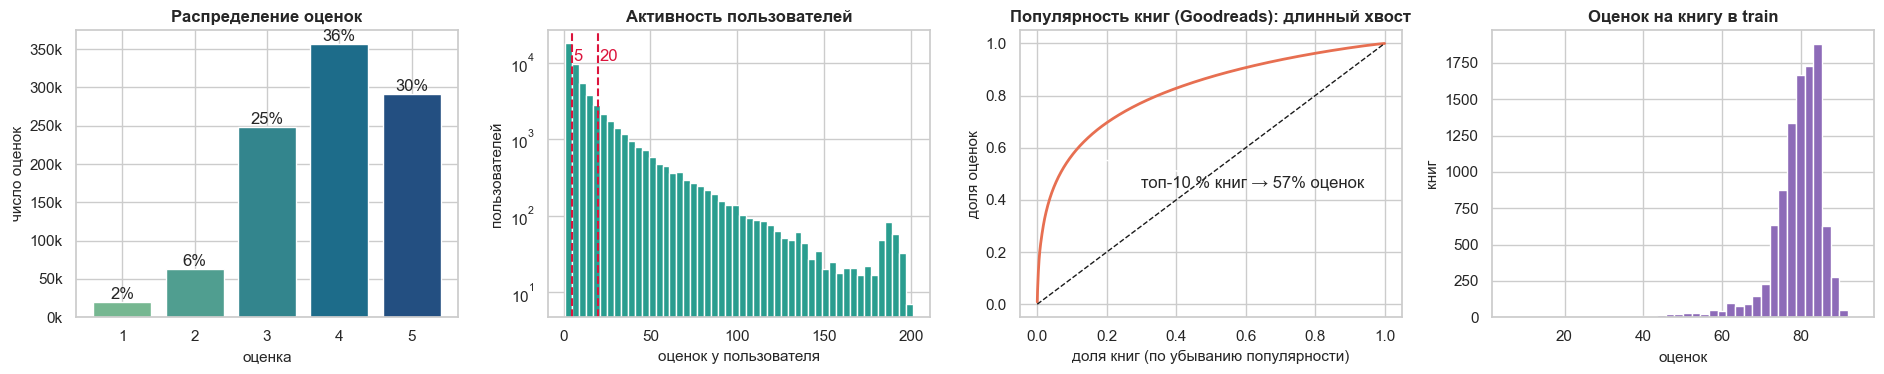

In [20]:
o, i = pipe.outer, pipe.inner
display(pd.DataFrame({
    "оценок": [len(o.train_df), len(o.test_df), len(i.train_df), len(i.test_df)],
    "пользователей": [o.train_df.u.nunique(), o.test_df.u.nunique(), i.train_df.u.nunique(), i.test_df.u.nunique()],
    "релевантных (≥4)": [int((o.train_df.rating >= 4).sum()), int((o.test_df.rating >= 4).sum()), int((i.train_df.rating >= 4).sum()), int((i.test_df.rating >= 4).sum())],
}, index=["train", "test (финальная оценка)", "train_inner", "val (подбор параметров и весов)"]))
fig = P.plot_eda(pipe.data, pipe.outer); plt.show()

**Что видно (повтор EDA из ДЗ №1, на нём держатся признаки и сегменты):** оценки смещены к 4–5 (самоотбор: люди оценивают то, что им, скорее всего, понравится); активность — «тяжёлый хвост»
(медиана ≈ 8 оценок, максимум 200, много «холодных» пользователей); реальная популярность книг (Goodreads) — длинный хвост, но в выборке `ratings.csv` на каждую книгу приходится ≈ 100 оценок,
поэтому популярность *внутри* выборки «сплющена» — это объясняет слабость Popularity.

### Типы пользователей
Гибрид должен вести себя по-разному для разной длины истории. По числу оценок в train выделяем три типа: **новые** (< 5), **обычные** (5–19), **активные** (≥ 20).
Пользователь с нулевой историей (совсем новый) получает неперсонализированный Top-N — см. раздел 7.

In [21]:
seg_eval = np.bincount(pipe.seg_outer[o.eval_users], minlength=3)
seg_all = np.bincount(pipe.seg_outer, minlength=3)
display(pd.DataFrame({"пользователей всего": seg_all, "в оценке (есть релевантная книга в test)": seg_eval,
                      "доля оценки, %": (100 * seg_eval / seg_eval.sum()).round(1),
                      "медиана оценок в train": [int(np.median(o.user_support[pipe.seg_outer == s])) for s in range(3)]}, index=cfg.segment_names))

,пользователей всего,в оценке (есть релевантная книга в test),"доля оценки, %",медиана оценок в train
новые (<5),20985,14265,33.5,2
обычные (5–19),20114,16117,37.9,9
активные (≥20),12325,12141,28.6,34


## 2. Этап 1. Расширенные признаки

Признаки строятся **только по обучающей части** (иначе в оценку просочилась бы информация из test); для inner- и outer-сплита считаются отдельно.
Код — модуль `features.py` (раздел 0).

| Группа | Признаки | Зачем |
|---|---|---|
| **Пользователь** | число оценок (`n_ratings`, `log_n_ratings`), процентиль активности, средняя оценка и её разброс, доля «понравилось» (≥ 4) и «не понравилось» (≤ 2), смещение (щедрость) пользователя, «мейнстримность» (средняя популярность прочитанного), средний год издания и «качество» прочитанного, **жанровый профиль** (22 жанра) и его энтропия (широта вкуса), разнообразие авторов | тип пользователя, калибровка оценок, «насколько вкус узкий/широкий» |
| **Книга** | популярность в train и на Goodreads, сглаженный средний рейтинг (байесовский), **разнообразие оценок**: std, энтропия распределения 1–5★, доля негатива (Goodreads), год, язык, число изданий, «книга из серии», число авторов, **тематические категории** (22 жанра из тегов Goodreads) | качество, спорность, тема |
| **Взаимодействие (пара пользователь–кандидат)** | жанровое сходство `profile·genre`, косинус до профиля вкуса и **максимальное сходство с понравившейся книгой** (схожесть с историей), автор уже читан / понравился, разрыв популярности `|мейнстрим − популярность книги|`, разрыв годов, сумма смещений `b_u + b_i` | персональная «подходящесть» кандидата |

Тематические категории — словарь «жанр → теги Goodreads» (`GENRE_TAGS`): служебные «полки» (to-read, favorites…) исключены, тег относится к первому подходящему жанру.

**Жанры:** 22 категорий, покрыто 100% каталога. **Признаков:** у книги — 42, у пользователя — 36.

,title,топ-3 жанра
book_id,,
1,"The Hunger Games (The Hunger Games, #1)","young_adult (40%), dystopian (25%), science_fiction (18%)"
2,"Harry Potter and the Sorcerer's Stone (Harry Potter, #1)","fantasy (56%), young_adult (20%), children (15%)"
3,"Twilight (Twilight, #1)","young_adult (40%), paranormal (30%), fantasy (24%)"
6,The Fault in Our Stars,"young_adult (58%), contemporary_literary (21%), romance (18%)"
17,"Catching Fire (The Hunger Games, #2)","young_adult (44%), dystopian (20%), fantasy (14%)"


,count,mean,std,min,25%,50%,75%,max
n_ratings_train,10000.0,78.850,6.998,6.000,77.000,80.000,83.000,94.000
bayes_mean_train,10000.0,3.857,0.243,2.331,3.704,3.871,4.022,4.623
std_rating_train,10000.0,0.933,0.125,0.464,0.846,0.926,1.014,1.732
gr_avg_rating,10000.0,4.002,0.254,2.470,3.850,4.020,4.180,4.820
gr_rating_std,10000.0,0.944,0.099,0.518,0.880,0.940,1.004,1.522
gr_rating_entropy,10000.0,1.800,0.174,0.719,1.701,1.810,1.918,2.303
gr_dislike_share,10000.0,0.072,0.044,0.004,0.043,0.062,0.090,0.551
year,10000.0,1989.134,54.133,1500.000,1990.000,2004.000,2011.000,2017.000
is_series,10000.0,0.444,0.497,0.000,0.000,0.000,1.000,1.000


,count,mean,std,min,25%,50%,75%,max
n_ratings,53424.0,14.759,21.164,1.000,2.000,7.000,18.000,160.000
mean_rating,53424.0,3.878,0.682,1.000,3.500,4.000,4.333,5.000
std_rating,53424.0,0.587,0.405,0.000,0.331,0.639,0.866,2.000
share_like,53424.0,0.673,0.305,0.000,0.500,0.722,1.000,1.000
share_dislike,53424.0,0.083,0.171,0.000,0.000,0.000,0.100,1.000
mainstream,53424.0,0.323,0.187,0.000,0.180,0.304,0.443,0.969
mean_year,53424.0,1993.249,31.711,1500.000,1989.750,2002.667,2009.167,2017.000
genre_entropy,53424.0,2.252,0.763,-0.000,1.715,2.308,2.844,4.188
top_genre_share,53424.0,0.454,0.189,0.114,0.306,0.414,0.574,1.000
author_diversity,53424.0,0.848,0.204,0.031,0.750,1.000,1.000,1.000


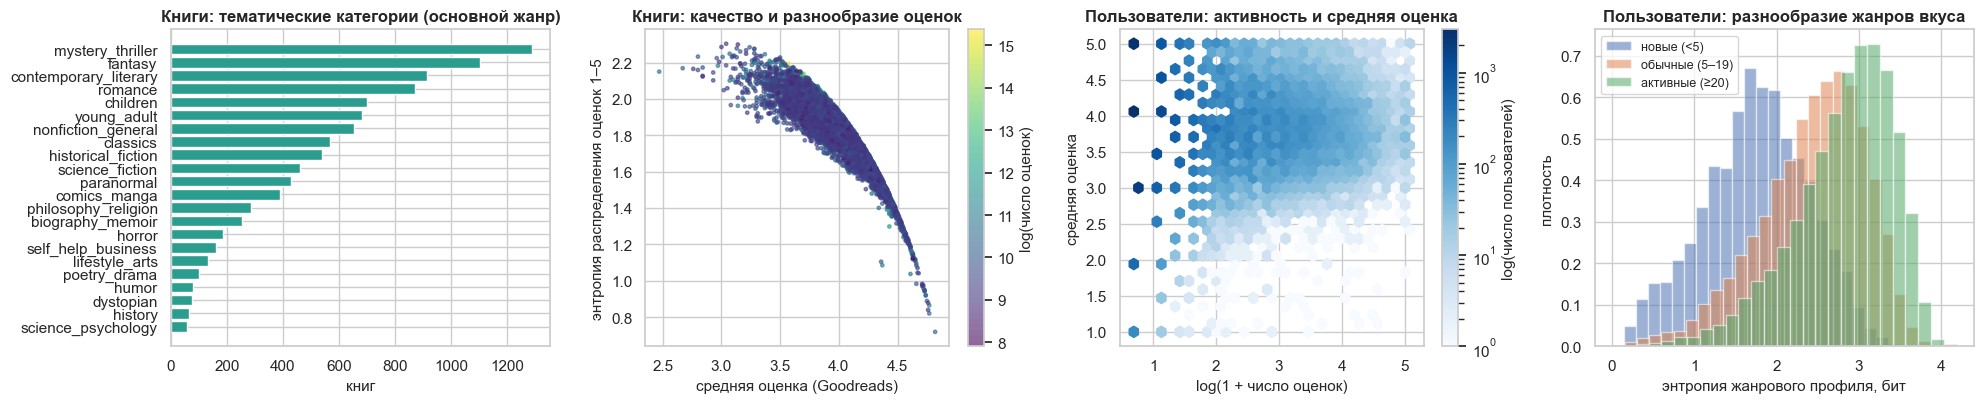

In [22]:
itf, uf = pipe.feat["outer"]["item"], pipe.feat["outer"]["user"]
md(f"**Жанры:** {len(F.GENRES)} категорий, покрыто {pipe.genre_info['coverage']:.0%} каталога. **Признаков:** у книги — {itf.shape[1]}, у пользователя — {uf.shape[1]}.")
ex = pipe.data.books.set_index("book_id").loc[[1, 2, 3, 6, 17], ["title"]].copy()
G = pipe.G
ex["топ-3 жанра"] = [", ".join(F.GENRES[j] + f" ({G[pipe.data.book_index(b), j]:.0%})" for j in np.argsort(-G[pipe.data.book_index(b)])[:3]) for b in ex.index]
display(ex.style.set_properties(**{"text-align": "left"}))
display(itf[["n_ratings_train", "bayes_mean_train", "std_rating_train", "gr_avg_rating", "gr_rating_std", "gr_rating_entropy", "gr_dislike_share", "year", "is_series"]].describe().T.round(3))
display(uf[["n_ratings", "mean_rating", "std_rating", "share_like", "share_dislike", "mainstream", "mean_year", "genre_entropy", "top_genre_share", "author_diversity"]].describe().T.round(3))
fig = P.plot_feature_overview(itf, uf, F.GENRES, pipe.seg_outer, cfg.segment_names); plt.show()

In [23]:
g = uf.groupby(pipe.seg_outer)[["mean_rating", "std_rating", "mainstream", "genre_entropy", "top_genre_share"]].mean()
r_ent = itf["gr_avg_rating"].corr(itf["gr_rating_entropy"])
md(f'''**Что показывают признаки.**
* **Книги:** жанры покрывают весь каталог и распределены неравномерно; энтропия распределения оценок сильно связана со средним качеством (r = {r_ent:.2f}: у высоко оценённых книг оценки «однороднее»),
  но внутри групп с одинаковой средней остаётся разброс — это и есть «спорность» книги, независимый от среднего сигнал.
* **Пользователи:** средняя оценка почти не зависит от активности ({g.loc[0, 'mean_rating']:.2f} → {g.loc[2, 'mean_rating']:.2f}), зато с ростом истории растут разброс оценок ({g.loc[0, 'std_rating']:.2f} → {g.loc[2, 'std_rating']:.2f}),
  «мейнстримность» ({g.loc[0, 'mainstream']:.2f} → {g.loc[2, 'mainstream']:.2f}: активные читают более известные книги) и **широта жанрового вкуса** (энтропия {g.loc[0, 'genre_entropy']:.2f} → {g.loc[2, 'genre_entropy']:.2f} бит,
  доля главного жанра {g.loc[0, 'top_genre_share']:.0%} → {g.loc[2, 'top_genre_share']:.0%}). «Новый» пользователь по 1–4 книгам выглядит узким любителем одного жанра, активный — читателем с широким вкусом.

Отсюда два следствия, которые используются ниже: (1) разным типам пользователей нужны разные веса моделей; (2) для широкого вкуса нужна защита от однообразия выдачи (баланс/MMR).
Пригодность признаков для ранжирования проверяется количественно в разделе 4.5 (доля релевантных кандидатов по децилям признака и ablation ранжировщика).''')

**Что показывают признаки.**
* **Книги:** жанры покрывают весь каталог и распределены неравномерно; энтропия распределения оценок сильно связана со средним качеством (r = -0.90: у высоко оценённых книг оценки «однороднее»),
  но внутри групп с одинаковой средней остаётся разброс — это и есть «спорность» книги, независимый от среднего сигнал.
* **Пользователи:** средняя оценка почти не зависит от активности (3.90 → 3.85), зато с ростом истории растут разброс оценок (0.31 → 0.80),
  «мейнстримность» (0.21 → 0.53: активные читают более известные книги) и **широта жанрового вкуса** (энтропия 1.75 → 2.81 бит,
  доля главного жанра 54% → 36%). «Новый» пользователь по 1–4 книгам выглядит узким любителем одного жанра, активный — читателем с широким вкусом.

Отсюда два следствия, которые используются ниже: (1) разным типам пользователей нужны разные веса моделей; (2) для широкого вкуса нужна защита от однообразия выдачи (баланс/MMR).
Пригодность признаков для ранжирования проверяется количественно в разделе 4.5 (доля релевантных кандидатов по децилям признака и ablation ранжировщика).

## 3. Модели из ДЗ №1 и нейросеть Two-Tower: обучение

### 3.1 Модели из ДЗ №1 (перенесены без изменения логики)
* **Popularity** — сглаженное (байесовское) среднее; для гибрида — источник «популярного». Дополнительно **Genre-Popularity** — популярное *в любимых жанрах* пользователя (персонализированная популярность по жанровому профилю).
* **Content-based** — TF-IDF по названию и топ-20 тегам, профиль пользователя = сумма векторов понравившихся книг, косинус.
* **Item-based CF** — косинус по столбцам разреженной матрицы взаимодействий, top-K соседей, score = сумма сходств с историей.
* **SVD (surprise)** — Funk SVD на явных оценках; **PureSVD** — усечённое SVD бинарной матрицы взаимодействий.

### 3.2 Нейросеть Two-Tower (продвинутая часть)
Выбрана архитектура **Two-Tower** — совместные эмбеддинги пользователей и книг в одном пространстве (модуль `models/two_tower.py`, раздел 0):

```
 история «понравилось» ──► mean-pool эмбеддингов ─┐                   ID книги ──► эмбеддинг ──┐
 история «не понравилось» ► mean-pool эмбеддингов ─┼► MLP ► нормировка ► u     признаки книги ──────┼► MLP ► нормировка ► v
 признаки пользователя + жанровый профиль ────────┘     (башня польз.)   жанры, год, качество, TF-IDF→SVD ┘   (башня книги)
                                                    score(u, v) = cos(u, v) / τ
```
* **Индуктивная башня пользователя:** нет ID пользователя — вектор собирается из истории и признаков, поэтому работает для любого пользователя, в т.ч. нового (после 1–2 оценок).
* **Башня книги использует признаки** (этап 1) и «выключаемый» ID-эмбеддинг (ID-dropout) → вектор получается и для книги без единой оценки (холодный старт книг, раздел 6.2).
* **Функция потерь — sampled softmax** с внутрибатчевыми + равномерными негативами и поправкой logQ на популярность.
* **Без утечки:** на каждой эпохе у пользователя случайно скрывается 35 % понравившихся книг («цели»), а история **и все признаки пользователя** считаются только по остальным — ровно как при реальной рекомендации.
* Размерность 96, ≈ 2.2 млн параметров; обучение на CPU несколько минут.

In [24]:
pipe.stage_train()

=== Этап 3. Обучение моделей ===


   подбор гиперпараметров на validation (модели обучены на train_inner)


   Item-CF: {'feedback': 'seen', 'k': 10} | SVD: {'n_factors': 100, 'n_epochs': 30, 'lr_all': 0.01, 'reg_all': 0.1} | PureSVD факторов: 800


   [inner] обучение компонентов на train_inner (нужны для подбора весов гибрида и ранжировщика)


  [two-tower] эпоха  1/30  loss=6.9502  (9 c)


  [two-tower] эпоха  2/30  loss=6.1536  val nDCG@10=0.0502  (19 c)


... (29 outputs left out)

  [two-tower] эпоха 28/30  loss=4.8700  (277 c)


  [two-tower] эпоха 30/30  loss=4.8753  (296 c)


   SVD: RMSE на test = 0.8297, MAE = 0.6462


   ⏱ train: 767.8 c


In [25]:
md("**Подбор гиперпараметров** (на validation; модели обучены на `train_inner`, test не используется):")
a, b, c = pipe.tables["tune_knn"], pipe.tables["tune_svd"], pipe.tables["tune_psvd"]
md("*Item-CF: сигнал × число соседей (nDCG@10)*"); display(a.pivot_table(index="сигнал", columns="K соседей", values="nDCG@10").round(4))
md("*SVD (surprise): RMSE на validation*"); display(b.round(4))
md("*PureSVD: число факторов*"); display(c.round(4))
md(f"Выбрано: **Item-CF** — {pipe.params['knn']}, **SVD** — {pipe.params['svd']}, **PureSVD** — {pipe.params['psvd_factors']} факторов. "
   f"RMSE SVD на test = {pipe.svd_rmse[0]:.3f} (в ДЗ №1: 0.830).")

**Подбор гиперпараметров** (на validation; модели обучены на `train_inner`, test не используется):

*Item-CF: сигнал × число соседей (nDCG@10)*

K соседей,10,20,50
сигнал,,,
like,0.1626,0.1611,0.1582
seen,0.1679,0.1656,0.1631


*SVD (surprise): RMSE на validation*

,n_factors,lr_all,reg_all,RMSE (val)
0,50,0.01,0.05,0.8450
1,50,0.01,0.10,0.8343
2,50,0.01,0.15,0.8357
3,100,0.01,0.05,0.8453
4,100,0.01,0.10,0.8342
5,100,0.01,0.15,0.8350


*PureSVD: число факторов*

,n_factors,nDCG@10,Recall@10
0,200,0.0877,0.1222
1,400,0.1173,0.1656
2,600,0.1340,0.1888
3,800,0.1445,0.2042


Выбрано: **Item-CF** — {'feedback': 'seen', 'k': 10}, **SVD** — {'n_factors': 100, 'n_epochs': 30, 'lr_all': 0.01, 'reg_all': 0.1}, **PureSVD** — 800 факторов. RMSE SVD на test = 0.830 (в ДЗ №1: 0.830).

### Кривая обучения Two-Tower и подбор гиперпараметров нейросети
Слева — функция потерь (она включает «шум» внутрибатчевых негативов, поэтому не падает до нуля), справа — **nDCG@10 на validation** по ходу обучения (модель на `train_inner`): качество растёт и выходит на плато — переобучения нет.
Пунктир — ориентиры: Item-CF и PureSVD на тех же validation-пользователях.

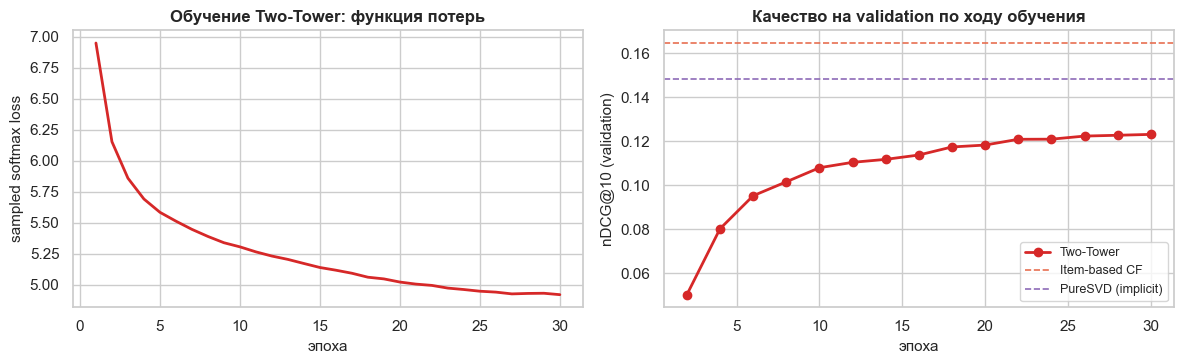

**Журнал подбора гиперпараметров Two-Tower** (15 запусков на validation-пользователях; 'val nDCG@10' — после последней эпохи). Главный вывод: модель *недообучена, а не переобучена* — лучше работают слабый dropout, больше обучающих шагов (batch 1024) и больше скрываемых целей; рост ёмкости (dim 160) и числа негативов почти ничего не дают — потолок архитектуры ≈ 0.13.

,что менялось относительно базового,эпох,val nDCG@10
вариант,,,
A,базовый (batch 2048; dropout 0.15/0.15/0.2; доля целей 0.2; dim 96),24,0.1034
B,температура softmax 0.05,24,0.1036
C,доля скрываемых целей 0.35,24,0.1121
D,размерности 160 / hidden 512,24,0.1114
E,lr 4e-3,24,0.1066
F,слабый dropout 0.05/0.05/0.1,24,0.1142
G,F + доля целей 0.35,30,0.1259
H,G + размерности 160 / hidden 512,30,0.1302
I,без dropout,30,0.1248


In [26]:
from recsys.models.classic import ItemKNNRecommender
from recsys.models.base import evaluate
refs = {}
vu = pipe.val_users[:4000]
refs["Item-based CF"] = evaluate(pipe.zoo_inner.models["knn"], pipe.inner, users=vu, ks=(10,)).metrics["nDCG@10"].mean()
refs["PureSVD (implicit)"] = evaluate(pipe.zoo_inner.models["psvd"], pipe.inner, users=vu, ks=(10,)).metrics["nDCG@10"].mean()
fig = P.plot_training_curve(pipe.tt_history, refs); plt.show()
md("**Журнал подбора гиперпараметров Two-Tower** (15 запусков на validation-пользователях; 'val nDCG@10' — после последней эпохи). Главный вывод: модель *недообучена, а не переобучена* — "
   "лучше работают слабый dropout, больше обучающих шагов (batch 1024) и больше скрываемых целей; рост ёмкости (dim 160) и числа негативов почти ничего не дают — потолок архитектуры ≈ 0.13.")
import io
tuning_log = pd.read_csv(io.StringIO('''вариант,что менялось относительно базового,эпох,val nDCG@10
A,базовый (batch 2048; dropout 0.15/0.15/0.2; доля целей 0.2; dim 96),24,0.1034
B,температура softmax 0.05,24,0.1036
C,доля скрываемых целей 0.35,24,0.1121
D,размерности 160 / hidden 512,24,0.1114
E,lr 4e-3,24,0.1066
F,слабый dropout 0.05/0.05/0.1,24,0.1142
G,F + доля целей 0.35,30,0.1259
H,G + размерности 160 / hidden 512,30,0.1302
I,без dropout,30,0.1248
J (выбран),G + batch 1024 (больше шагов),30,0.1306
K,J но 50 эпох,50,0.1286
L,batch 512 + lr 1.5e-3,30,0.1259
M,доля целей 0.5,30,0.1235
N,J + размерности 160 / hidden 512,40,0.1307
O,J + 4096 равномерных негативов,30,0.1268'''))
display(tuning_log.set_index("вариант").style.format({"val nDCG@10": "{:.4f}"}).highlight_max(subset=["val nDCG@10"], props="font-weight:bold; background-color:#d8f3dc"))

## 4. Этап 2. Гибридная система

### 4.1 Стратегия
1. **Генерация кандидатов** — каждая из 7 моделей предлагает свои top-40 непрочитанных книг; предложения объединяются в **общий пул** (дубликаты схлопываются, прочитанное отфильтровано). Пул находит больше релевантных книг, чем любая модель в отдельности.
2. **Слияние** — оценки моделей приводятся к общей шкале (z-score внутри пула кандидатов пользователя) и усредняются **с весами**. Веса подбираются на validation **отдельно для каждого типа пользователей** (новые / обычные / активные).
   Доля «популярного» — это вес компонент Popularity и Genre-Popularity: он выше там, где персональных сигналов мало.
3. **Баланс релевантность ↔ разнообразие** — итоговый список собирается алгоритмом **MMR** (Maximal Marginal Relevance): каждая следующая книга должна быть и релевантной, и непохожей на уже выбранные (косинус эмбеддингов по названию/тегам). Параметр λ выбирается на validation по правилу «максимум разнообразия при потере nDCG ≤ 2 %».
4. **Новые книги** — книги без оценок (CF их не видит) получают зарезервированные слоты (контент + нейросеть). В стандартном датасете у всех книг есть оценки, поэтому механизм проверяется отдельным экспериментом (раздел 6.2).
5. **Обучаемый ранжировщик (LightGBM LambdaRank)** — вариант слияния, который по расширенным признакам сам учится, когда каким источникам верить (раздел 4.4).

In [27]:
pipe.stage_recommend()

=== Этап 4. Гибридная система: пул кандидатов, веса, баланс, ранжировщик ===


   пул (validation): 20,000 пользователей × до 280 кандидатов; в среднем 203 уникальных; recall пула = 0.533


   веса (общие): knn=0.16, content=0.15, svd=0.06, psvd=0.02, tt=0.61, pop=0.00, gpop=0.00


   веса [новые (<5)]: knn=0.11, content=0.13, svd=0.00, psvd=0.00, tt=0.73, pop=0.00, gpop=0.03  (nDCG@10 val=0.1673)


   веса [обычные (5–19)]: knn=0.20, content=0.15, svd=0.06, psvd=0.00, tt=0.59, pop=0.00, gpop=0.00  (nDCG@10 val=0.1905)


   веса [активные (≥20)]: knn=0.10, content=0.11, svd=0.13, psvd=0.20, tt=0.46, pop=0.00, gpop=0.00  (nDCG@10 val=0.1994)


   MMR: выбрано λ = 0.6 (потеря nDCG ≤ 2% от λ=1)


   ablation признаков (nDCG@10 внутри пула, validation):


                                         nDCG  признаков
   набор                                                
   взвешенное усреднение (baseline)    0.1839          1
   scores                              0.1826         17
   scores + user                       0.1838         25
   scores + item                       0.1861         28
   scores + interaction                0.1902         25
   scores + user + item                0.1869         36
   scores + user + item + interaction  0.1935         44


   пул (test): recall пула = 0.567


   ⏱ recommend: 261.4 c


### 4.2 Общий пул кандидатов: сколько релевантных книг находит каждая модель
`recall@40` — какую долю будущих «понравившихся» книг пользователя содержит список из 40 кандидатов. Пул (объединение) — это **верхняя граница** для любого ранжирования внутри него.

,recall
Item-based CF (top-40),0.4138
Content-based (TF-IDF) (top-40),0.2308
SVD (surprise) (top-40),0.0063
PureSVD (implicit) (top-40),0.4228
Two-Tower (нейросеть) (top-40),0.3490
Popularity (top-40),0.0053
Genre-Popularity (top-40),0.0517
"Общий пул (объединение, ≈203 книг)",0.5674


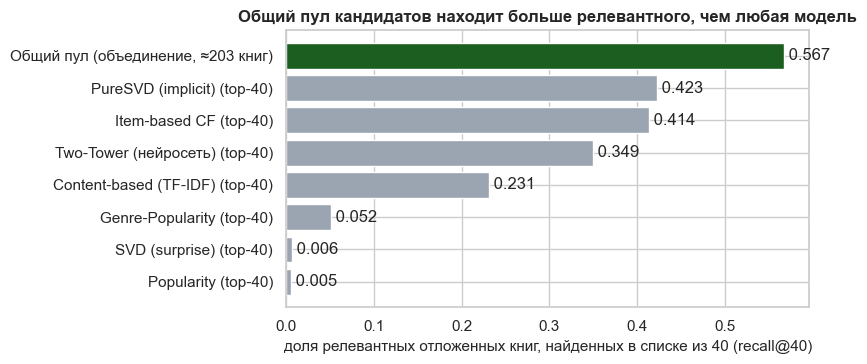

In [28]:
pr = pipe.tables["pool_recall"]
display(pr.round(4).style.format("{:.4f}"))
fig = P.plot_pool_recall(pr); plt.show()

### 4.3 Веса смеси: общие и по типам пользователей
Подбор: случайный поиск по симплексу весов + координатный спуск; критерий — nDCG@10 на validation-пользователях (≈ 20 тыс.), каждый тип пользователей оптимизируется независимо.
Так как оценки каждой модели стандартизованы внутри пула, **вес = относительная важность источника**. Сравните строки: у новых пользователей (мало истории) смесь опирается на другие источники, чем у активных.

,Item-based CF,Content-based (TF-IDF),SVD (surprise),PureSVD (implicit),Two-Tower (нейросеть),Popularity,Genre-Popularity
новые (<5),0.11,0.13,0.00,0.00,0.73,0.00,0.03
обычные (5–19),0.20,0.15,0.06,0.00,0.59,0.00,0.00
активные (≥20),0.10,0.11,0.13,0.20,0.46,0.00,0.00
общие веса (все вместе),0.16,0.15,0.06,0.02,0.61,0.00,0.00


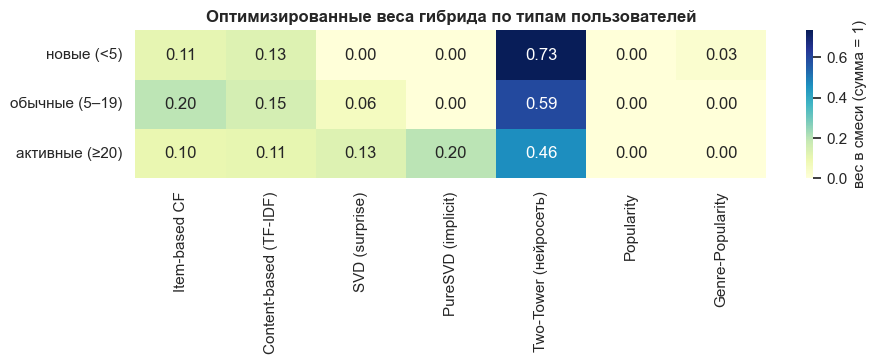

,nDCG@10 (validation),равные веса,лучшая одиночная модель,пользователей
новые (<5),0.1673,0.1490,0.1503,5651
обычные (5–19),0.1905,0.1767,0.1775,8815
активные (≥20),0.1994,0.1902,0.1811,5534


In [29]:
labels = H.COMPONENT_LABELS
wt = pd.DataFrame(pipe.w_seg, index=cfg.segment_names, columns=[labels[n] for n in pipe.zoo_inner.names])
wt.loc["общие веса (все вместе)"] = pipe.w_global
display(wt.round(3).style.background_gradient(cmap="YlGnBu", axis=None).format("{:.2f}"))
fig = P.plot_weights(pipe.w_seg, pipe.zoo_inner.names, cfg.segment_names, labels); plt.show()
rep = pd.DataFrame({"nDCG@10 (validation)": [r["best"] for r in pipe.weight_reports["segments"]] , "равные веса": [r["uniform"] for r in pipe.weight_reports["segments"]],
                    "лучшая одиночная модель": [max(r["single"].values()) for r in pipe.weight_reports["segments"]], "пользователей": [r["n_users"] for r in pipe.weight_reports["segments"]]}, index=cfg.segment_names)
display(rep.round(4))

In [30]:
W_ = pd.DataFrame(pipe.w_seg, index=cfg.segment_names, columns=pipe.zoo_inner.names)
md(f'''**Что видно.** (1) Чем больше история, тем «тяжелее» смесь: у активных пользователей появляются факторизации (PureSVD {W_.loc[cfg.segment_names[2], 'psvd']:.2f}, SVD {W_.loc[cfg.segment_names[2], 'svd']:.2f}),
у новых они получают {W_.loc[cfg.segment_names[0], 'psvd']:.2f} / {W_.loc[cfg.segment_names[0], 'svd']:.2f} — при 1–4 оценках факторы пользователя не обучены, и смесь опирается на Two-Tower ({W_.loc[cfg.segment_names[0], 'tt']:.2f}), контент и CF.
(2) Популярное (Popularity, Genre-Popularity) почти не получает веса ни в одном сегменте: в этой выборке популярность «сплющена» (≈ 100 оценок на книгу), поэтому «доля популярного» оптимизатор сводит к нулю — персональных сигналов достаточно уже при 1–4 оценках.
(3) Вес — это не «качество модели», а относительная важность её оценок после стандартизации внутри пула: Two-Tower получает самый большой вес при меньшем nDCG, чем у Item-CF, потому что его оценки гладкие и **дополняют** разреженные оценки CF
(это подтверждает ablation в разделе 5.7: без Two-Tower качество смеси падает сильнее, чем без любой другой модели, кроме Item-CF).''')

**Что видно.** (1) Чем больше история, тем «тяжелее» смесь: у активных пользователей появляются факторизации (PureSVD 0.20, SVD 0.13),
у новых они получают 0.00 / 0.00 — при 1–4 оценках факторы пользователя не обучены, и смесь опирается на Two-Tower (0.73), контент и CF.
(2) Популярное (Popularity, Genre-Popularity) почти не получает веса ни в одном сегменте: в этой выборке популярность «сплющена» (≈ 100 оценок на книгу), поэтому «доля популярного» оптимизатор сводит к нулю — персональных сигналов достаточно уже при 1–4 оценках.
(3) Вес — это не «качество модели», а относительная важность её оценок после стандартизации внутри пула: Two-Tower получает самый большой вес при меньшем nDCG, чем у Item-CF, потому что его оценки гладкие и **дополняют** разреженные оценки CF
(это подтверждает ablation в разделе 5.7: без Two-Tower качество смеси падает сильнее, чем без любой другой модели, кроме Item-CF).

### 4.4 Баланс релевантности и разнообразия (MMR)
Таблица и графики — на validation: как меняются точность и разнообразие по мере уменьшения λ. **ILD** — среднее попарное расстояние между книгами списка, **Coverage** — доля каталога, попавшая в выдачу,
**GenreEntropy** — жанровое разнообразие списка, **Novelty** — «неожиданность» (−log₂ доли оценок книги).

,nDCG@10,Recall@10,Coverage@10,ILD@10,Novelty@10,GenreEntropy@10,PopPercentile@10
λ,,,,,,,
1.00,0.1864,0.2560,0.9668,0.3554,13.3016,1.9945,0.4134
0.95,0.1868,0.2566,0.9679,0.3662,13.3016,2.0203,0.4133
0.90,0.1870,0.2569,0.9684,0.3798,13.3017,2.0527,0.4129
0.85,0.1873,0.2575,0.9697,0.3961,13.3018,2.0902,0.4124
0.80,0.1873,0.2569,0.9702,0.4143,13.3020,2.1325,0.4119
0.70,0.1865,0.2555,0.9698,0.4529,13.3020,2.2220,0.4110
0.60,0.1841,0.2520,0.9713,0.4923,13.3018,2.3121,0.4096
0.50,0.1790,0.2473,0.9735,0.5275,13.3018,2.3937,0.4080


**Выбрано λ = 0.6**: самое разнообразное значение, при котором nDCG@10 не падает более чем на 2% относительно λ = 1.

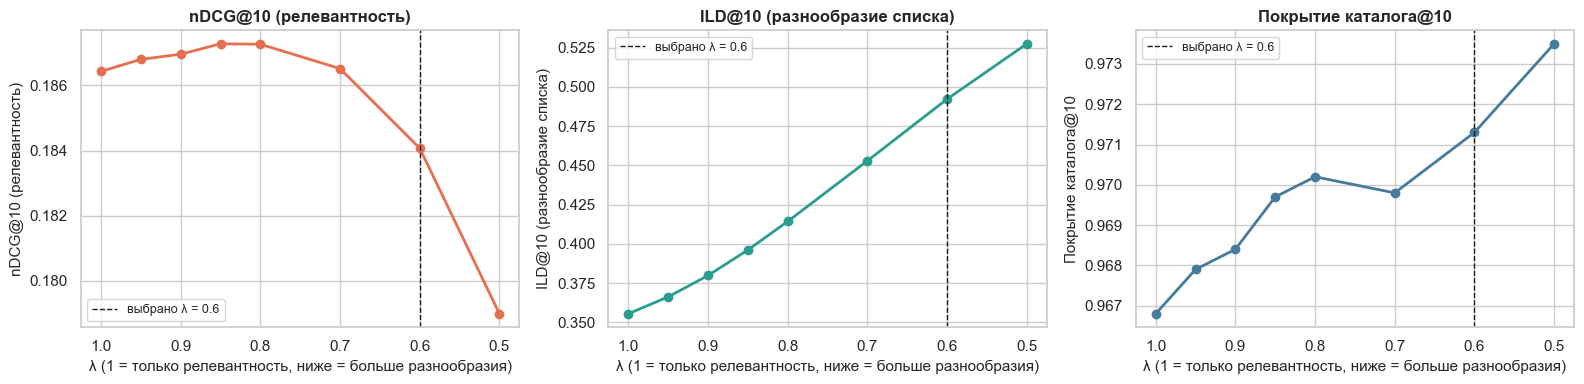

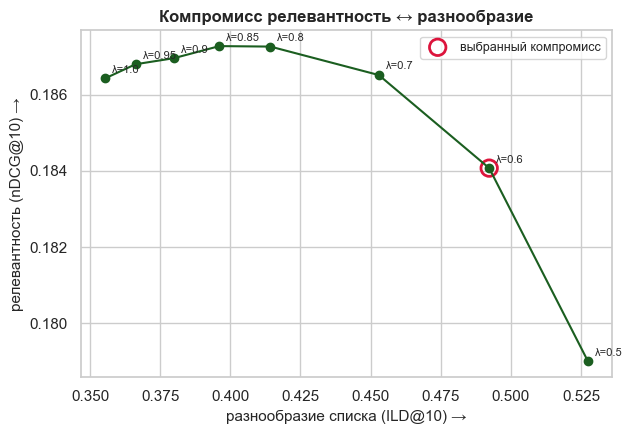

In [31]:
display(pipe.mmr_table.round(4))
md(f"**Выбрано λ = {pipe.lam}**: самое разнообразное значение, при котором nDCG@10 не падает более чем на {cfg.mmr_max_rel_loss:.0%} относительно λ = 1.")
fig = P.plot_mmr_tradeoff(pipe.mmr_table, pipe.lam, cfg.main_k); plt.show()
fig = P.plot_pareto(pipe.mmr_table, pipe.lam, cfg.main_k); plt.show()

### 4.5 Расширенные признаки в деле: ранжировщик LightGBM LambdaRank
Для каждой пары «пользователь – кандидат из пула» строятся признаки (оценки моделей, признаки пользователя, книги и взаимодействия). Ранжировщик обучается на validation-пользователях
(модели пула обучены на `train_inner`, метки — отложенные оценки val), а применяется к пулу из моделей, обученных на полном train; test в обучении не участвует.

**1) Несут ли признаки сигнал?** Доля релевантных кандидатов по децилям признака (красная линия — среднее по всем кандидатам):

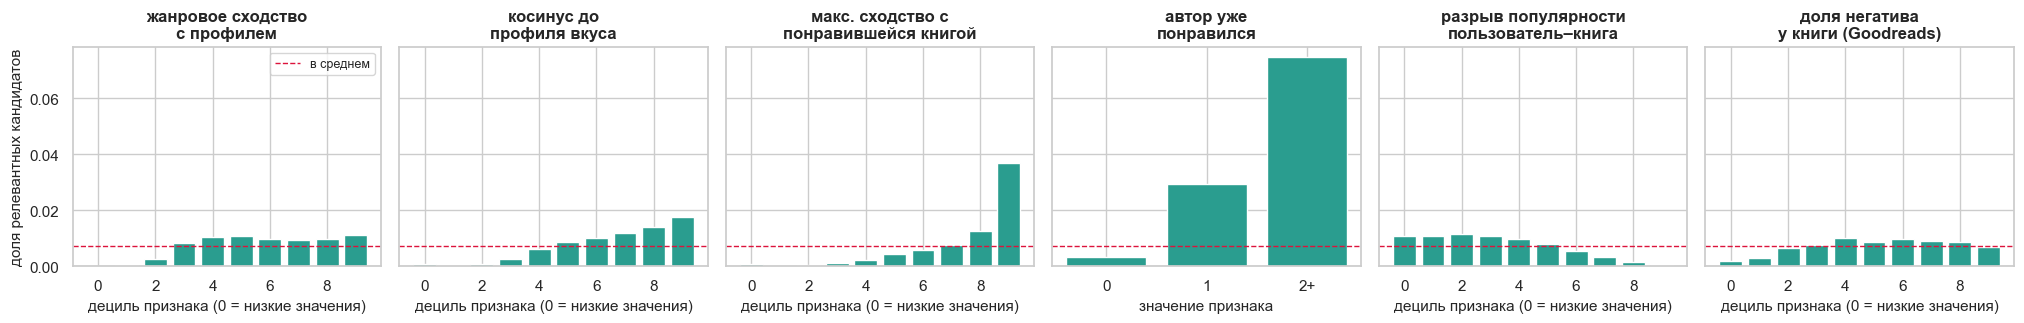

In [32]:
sig = ["x_genre_affinity", "x_cos_profile", "x_max_sim_liked", "x_author_liked", "x_pop_gap", "i_gr_dislike_share"]
lab = {"x_genre_affinity": "жанровое сходство\nс профилем", "x_cos_profile": "косинус до\nпрофиля вкуса", "x_max_sim_liked": "макс. сходство с\nпонравившейся книгой",
       "x_author_liked": "автор уже\nпонравился", "x_pop_gap": "разрыв популярности\nпользователь–книга", "i_gr_dislike_share": "доля негатива\nу книги (Goodreads)"}
fig = P.plot_feature_signal(pipe.feats_val, pipe.pool_val.rel, pipe.pool_val.valid, sig, lab); plt.show()

**2) Ablation: какие группы признаков улучшают качество?** Ранжировщик обучается на 70 % validation-пользователей и проверяется на остальных 30 %; сравнение с взвешенным усреднением на тех же пользователях.

,nDCG,признаков
набор,,
взвешенное усреднение (baseline),0.1839,1
scores,0.1826,17
scores + user,0.1838,25
scores + item,0.1861,28
scores + interaction,0.1902,25
scores + user + item,0.1869,36
scores + user + item + interaction,0.1935,44


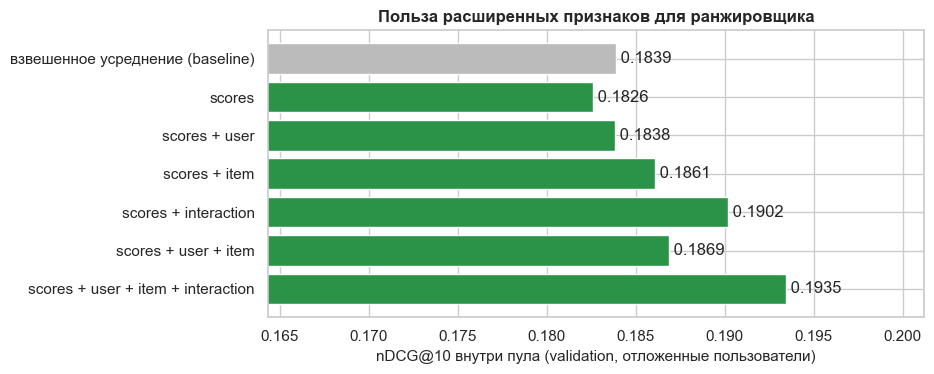

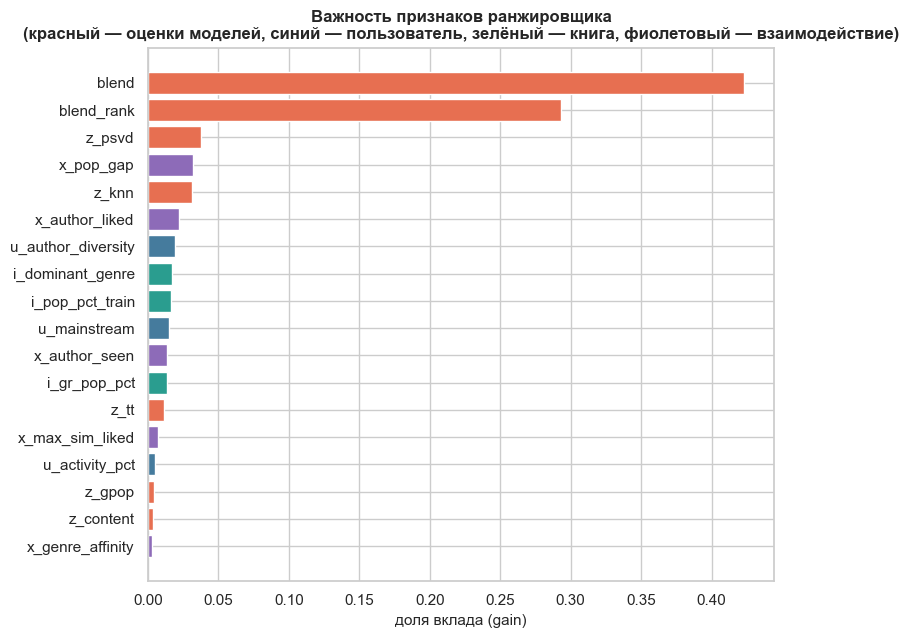

**Выводы по ablation (validation, 30 % пользователей для проверки):**
* Ранжировщик только на оценках моделей (0.1826) **не лучше** взвешенного усреднения (0.1839) — сам по себе он ничего не добавляет: сигнал лежит в расширенных признаках.
* **Признаки взаимодействия** (жанровое сходство, схожесть с историей, автор, разрыв популярности) дают основной выигрыш: 0.1902 (+3.4 % к взвешенному усреднению).
  Признаки книги дают небольшой прирост (0.1861), признаки пользователя сами по себе — в пределах шума (0.1838): они полезны только в паре с признаками книги/взаимодействия (персонализация «кому» + «что»).
* **Все группы вместе — 0.1935 (+5.2 %)**; на test тот же эффект: Hybrid-LTR против взвешенной суммы по типам пользователей — см. 5.1.
* В важности признаков по gain лидируют сводная оценка смеси (`blend`, `blend_rank` — ранжировщик «доучивает» смесь), затем оценки PureSVD/Item-CF, разрыв популярности, «автор уже нравился», разнообразие авторов и жанр книги.


In [33]:
fa = pipe.tables["feature_ablation"]
display(fa.round(4).style.format({"nDCG": "{:.4f}"}))
fig = P.plot_feature_ablation(fa); plt.show()
fig = P.plot_importance(pipe.tables["feature_importance"]); plt.show()
b0 = fa.loc["взвешенное усреднение (baseline)", "nDCG"]
g = lambda k: fa.loc[k, "nDCG"]
md(f'''**Выводы по ablation (validation, 30 % пользователей для проверки):**
* Ранжировщик только на оценках моделей ({g("scores"):.4f}) **не лучше** взвешенного усреднения ({b0:.4f}) — сам по себе он ничего не добавляет: сигнал лежит в расширенных признаках.
* **Признаки взаимодействия** (жанровое сходство, схожесть с историей, автор, разрыв популярности) дают основной выигрыш: {g("scores + interaction"):.4f} ({(g("scores + interaction")/b0-1)*100:+.1f} % к взвешенному усреднению).
  Признаки книги дают небольшой прирост ({g("scores + item"):.4f}), признаки пользователя сами по себе — в пределах шума ({g("scores + user"):.4f}): они полезны только в паре с признаками книги/взаимодействия (персонализация «кому» + «что»).
* **Все группы вместе — {g("scores + user + item + interaction"):.4f} ({(g("scores + user + item + interaction")/b0-1)*100:+.1f} %)**; на test тот же эффект: Hybrid-LTR против взвешенной суммы по типам пользователей — см. 5.1.
* В важности признаков по gain лидируют сводная оценка смеси (`blend`, `blend_rank` — ранжировщик «доучивает» смесь), затем оценки PureSVD/Item-CF, разрыв популярности, «автор уже нравился», разнообразие авторов и жанр книги.
''')

## 5. Этап 3. Оценка и сравнение

Все модели и гибриды оцениваются на **одних и тех же 42 523 пользователях test**, метрики Precision@K, Recall@K, nDCG@K (K = 5, 10, 20) считаются векторной реализацией из ДЗ №1 (юнит-тест на ручном примере — ячейка ниже).
Гибриды выбирают Top-N только из пула кандидатов; одиночные модели ранжируют весь каталог. В таблице шесть гибридных стратегий — от простейшей до итоговой:

| Стратегия | Что это |
|---|---|
| Hybrid (равные веса) | наивное усреднение всех моделей |
| Hybrid (общие веса) | веса, оптимизированные на validation, одни для всех |
| Hybrid (веса по типам польз.) | свои оптимизированные веса для новых / обычных / активных |
| Hybrid + MMR | предыдущий + баланс релевантность ↔ разнообразие |
| Hybrid-LTR | вместо взвешенной суммы — обучаемый ранжировщик на расширенных признаках |
| **Hybrid-LTR + MMR** | **итоговая система** |

**Проверка метрик на ручном примере.** Рекомендации [a, b, c, d, e], релевантные {a, c, x}: Precision@5 = 2/5, Recall@5 = 2/3, nDCG@5 = DCG/IDCG; идеальный порядок даёт nDCG = 1, а смещение релевантных вниз — меньше.

In [34]:
from recsys.metrics import ranking_metrics
top = np.array([[0, 1, 2, 3, 4]]); rel = np.zeros((1, 10), dtype=bool); rel[0, [0, 2, 7]] = True
m = ranking_metrics(top, rel, ks=(5,))
dcg, idcg = 1 / np.log2(2) + 1 / np.log2(4), 1 / np.log2(2) + 1 / np.log2(3) + 1 / np.log2(4)
assert np.isclose(m["P@5"][0], 2 / 5) and np.isclose(m["R@5"][0], 2 / 3) and np.isclose(m["nDCG@5"][0], dcg / idcg)
assert np.isclose(ranking_metrics(np.array([[0, 2, 7, 1, 3]]), rel, ks=(5,))["nDCG@5"][0], 1.0)           # идеальный порядок → 1
assert ranking_metrics(np.array([[1, 3, 4, 0, 2]]), rel, ks=(5,))["nDCG@5"][0] < m["nDCG@5"][0]            # релевантные ниже → nDCG меньше
print(f"✓ метрики прошли проверку: P@5={m['P@5'][0]:.3f}, R@5={m['R@5'][0]:.3f}, nDCG@5={m['nDCG@5'][0]:.4f} (ожидалось {dcg / idcg:.4f})")

✓ метрики прошли проверку: P@5=0.400, R@5=0.667, nDCG@5=0.7039 (ожидалось 0.7039)


In [35]:
pipe.stage_evaluate()

=== Этап 5. Оценка качества на test ===


   Random                       nDCG@10 = 0.0006


   Popularity                   nDCG@10 = 0.0007


   Content-based (TF-IDF)       nDCG@10 = 0.1167


   Item-based CF                nDCG@10 = 0.2174


   SVD (surprise)               nDCG@10 = 0.0011


... (7 outputs left out)

   Hybrid-LTR                   nDCG@10 = 0.2512


   Hybrid-LTR + MMR             nDCG@10 = 0.2484


   вклад компонентов (общие веса):
                                                    nDCG@10  компонент  Δ к полному
   вариант                                                                         
   все компоненты                                    0.2343          7       0.0000
   без knn                                           0.2148          6      -0.0194
   без content                                       0.2327          6      -0.0015
   без svd                                           0.2342          6      -0.0001
   без psvd                                          0.2348          6       0.0005
   без tt                                            0.2235          6      -0.0108
   без pop                                           0.2333          6      -0.0010
   без gpop                                          0.2348          6       0.0005
   только модели из ДЗ №1 (knn, content, svd, pop)   0.2233          4      -0.0109
   ДЗ №1 + нейросеть (tt)                

   ⏱ evaluate: 11450.0 c


In [36]:
S = pipe.tables["summary"]
order = [N_RANDOM, N_POP, N_GPOP, N_CONTENT, N_KNN, N_SVD, N_PSVD, N_TT, N_H_UNI, N_H_GLOB, N_H_SEG, N_H_MMR, N_H_LTR, N_H_LTR_MMR]
md("### 5.1 Сводная таблица метрик (test, лучшее в столбце выделено)")
show(S.loc[order])
md(f"Пользователей в оценке: **{len(pipe.outer.eval_users):,}**. Для ориентира — результаты ДЗ №1 на том же сплите (nDCG@10): Item-CF 0.2174, гибрид из ДЗ 0.2224; здесь Item-CF = {S.loc[N_KNN, ('nDCG','@10')]:.4f}.")

### 5.1 Сводная таблица метрик (test, лучшее в столбце выделено)

Пользователей в оценке: **42,523**. Для ориентира — результаты ДЗ №1 на том же сплите (nDCG@10): Item-CF 0.2174, гибрид из ДЗ 0.2224; здесь Item-CF = 0.2174.

### 5.2 Доверительные интервалы (K = 10, среднее ± 95 % ДИ по пользователям)

,Precision@10,Recall@10,nDCG@10
Random,0.0003 ± 0.0001,0.0011 ± 0.0003,0.0006 ± 0.0001
Popularity,0.0003 ± 0.0001,0.0011 ± 0.0002,0.0007 ± 0.0001
Genre-Popularity,0.0044 ± 0.0002,0.0198 ± 0.0012,0.0114 ± 0.0007
Content-based (TF-IDF),0.0367 ± 0.0007,0.1586 ± 0.0031,0.1167 ± 0.0023
Item-based CF,0.0724 ± 0.0011,0.2720 ± 0.0036,0.2174 ± 0.0030
SVD (surprise),0.0006 ± 0.0001,0.0018 ± 0.0003,0.0011 ± 0.0002
PureSVD (implicit),0.0704 ± 0.0012,0.2348 ± 0.0034,0.1825 ± 0.0027
Two-Tower (нейросеть),0.0548 ± 0.0009,0.2244 ± 0.0035,0.1678 ± 0.0026
Hybrid (равные веса),0.0740 ± 0.0011,0.2748 ± 0.0036,0.2196 ± 0.0029
Hybrid (общие веса),0.0773 ± 0.0011,0.2943 ± 0.0037,0.2349 ± 0.0030


### 5.3 Визуализация

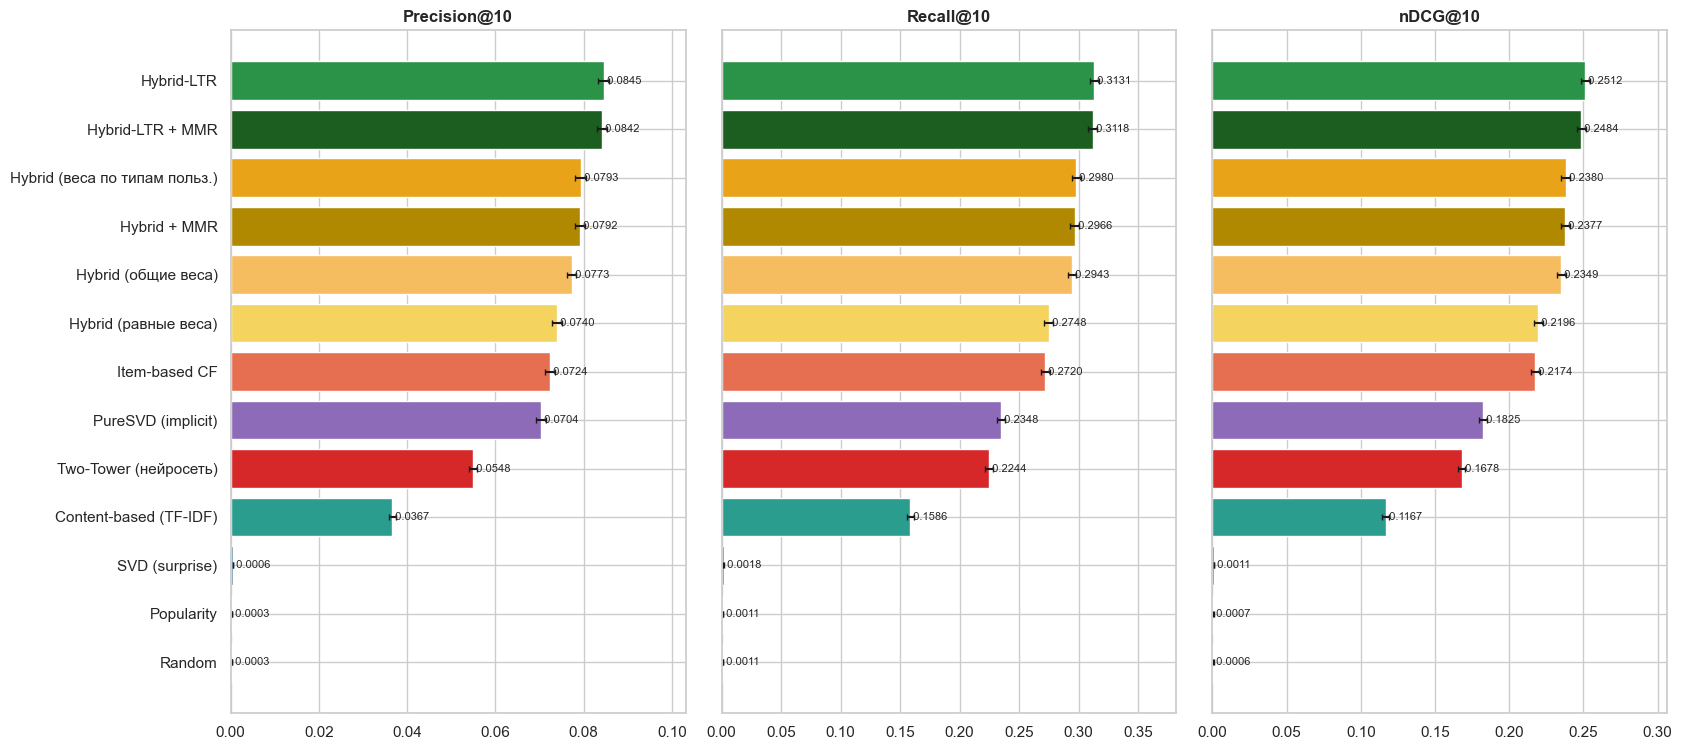

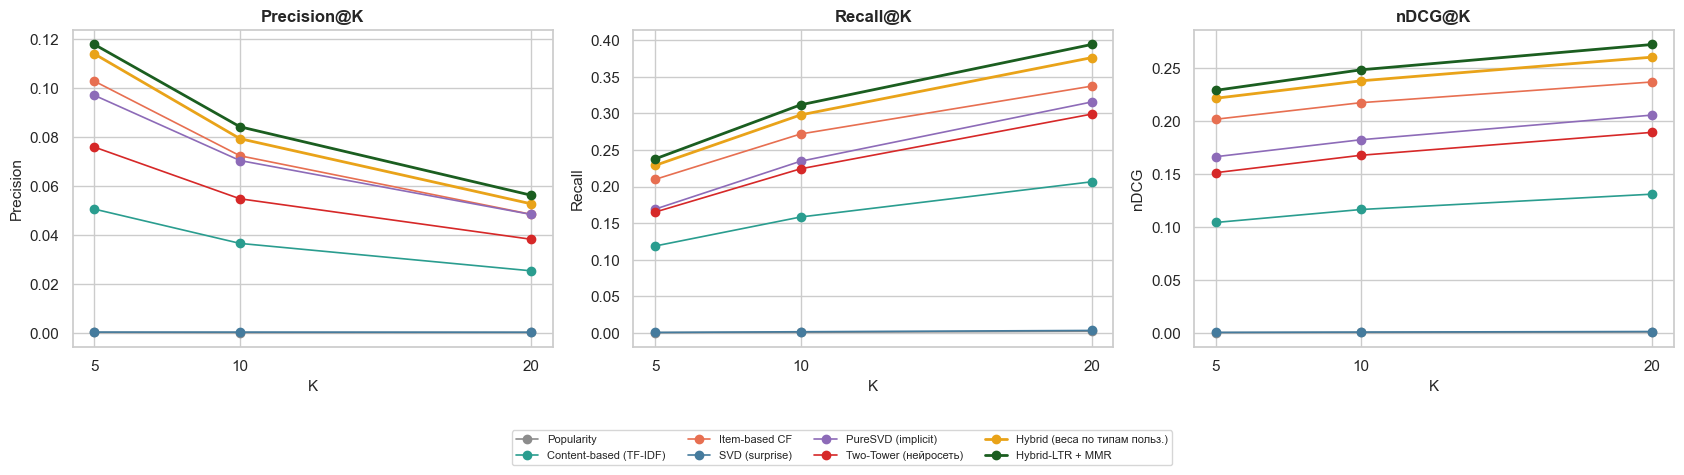

In [37]:
md("### 5.2 Доверительные интервалы (K = 10, среднее ± 95 % ДИ по пользователям)")
ci = pd.DataFrame({n: {f"{lab}@10": f"{pipe.results[n].metrics[f'{m}@10'].mean():.4f} ± {ci95(pipe.results[n].metrics[f'{m}@10']):.4f}" for lab, m in (("Precision", "P"), ("Recall", "R"), ("nDCG", "nDCG"))} for n in order}).T
display(ci)
md("### 5.3 Визуализация")
names_main = [n for n in order if n != N_GPOP]
fig = P.plot_model_comparison(pipe.results, 10, names_main); plt.show()
fig = P.plot_metrics_vs_k(pipe.results, cfg.ks, [N_POP, N_CONTENT, N_KNN, N_SVD, N_PSVD, N_TT, N_H_SEG, N_H_LTR_MMR]); plt.show()

In [38]:
md("### 5.4 Значимость улучшений: парная разность nDCG@10 относительно лучшей одиночной модели")
pd_ = pipe.tables["paired"]
display(pd_.style.format({c: "{:+.4f}" for c in pd_.columns if c.startswith("Δ")} | {"95% ДИ ±": "{:.4f}"}))
md(f"Лучшая одиночная модель — **{pipe.best_single}**. Разность значима, если |Δ| больше полуширины 95 % ДИ (парное сравнение по одним и тем же пользователям).")

### 5.4 Значимость улучшений: парная разность nDCG@10 относительно лучшей одиночной модели

,Δ nDCG@10 vs Item-based CF,95% ДИ ±,значимо
Hybrid (равные веса),+0.0022,0.0012,True
Hybrid (общие веса),+0.0175,0.0011,True
Hybrid (веса по типам польз.),+0.0206,0.0012,True
Hybrid + MMR,+0.0203,0.0012,True
Hybrid-LTR,+0.0338,0.0014,True
Hybrid-LTR + MMR,+0.0310,0.0014,True


Лучшая одиночная модель — **Item-based CF**. Разность значима, если |Δ| больше полуширины 95 % ДИ (парное сравнение по одним и тем же пользователям).

### 5.5 Анализ по типам пользователей
Главный вопрос гибрида — **кому** он помогает. Метрика — nDCG@10 внутри каждого типа пользователей (по длине истории в train).

,новые (<5),обычные (5–19),активные (≥20)
пользователей,14265,16117,12141


,новые (<5),обычные (5–19),активные (≥20)
Popularity,0.0001,0.0008,0.0013
Content-based (TF-IDF),0.1205,0.1177,0.1107
Item-based CF,0.1953,0.2158,0.2455
SVD (surprise),0.0008,0.0008,0.0018
PureSVD (implicit),0.1142,0.1877,0.2557
Two-Tower (нейросеть),0.1725,0.1592,0.1737
Hybrid (веса по типам польз.),0.2136,0.2313,0.2755
Hybrid-LTR + MMR,0.2182,0.2434,0.2905


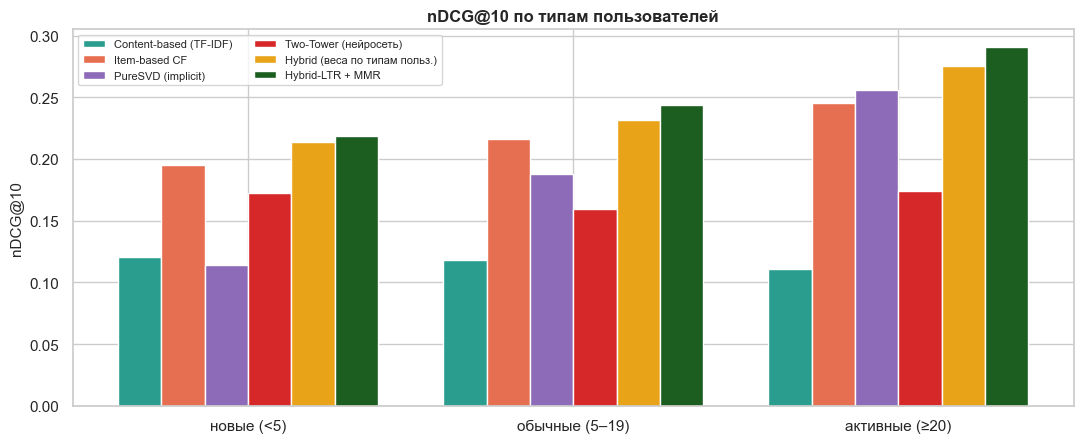

**Лучшая одиночная модель по типам пользователей:** новые (<5) — Item-based CF (0.195), обычные (5–19) — Item-based CF (0.216), активные (≥20) — PureSVD (implicit) (0.256)

**Прирост итоговой системы к Item-CF по типам пользователей:** новые (<5) — +11.7 %, обычные (5–19) — +12.8 %, активные (≥20) — +18.3 %

In [39]:
seg = pipe.tables["segments"]
cols = [N_POP, N_CONTENT, N_KNN, N_SVD, N_PSVD, N_TT, N_H_SEG, N_H_LTR_MMR]
display(pipe.seg_sizes.to_frame().T)
show(seg[cols].T)
fig = P.plot_segments(seg[[N_CONTENT, N_KNN, N_PSVD, N_TT, N_H_SEG, N_H_LTR_MMR]]); plt.show()
singles_ = [N_CONTENT, N_KNN, N_SVD, N_PSVD, N_TT]
best_by_seg = seg[singles_].idxmax(axis=1)
md("**Лучшая одиночная модель по типам пользователей:** " + ", ".join(f"{k} — {v} ({seg.loc[k, v]:.3f})" for k, v in best_by_seg.items()))
rel_gain = (seg[N_H_LTR_MMR] / seg[N_KNN] - 1) * 100
md("**Прирост итоговой системы к Item-CF по типам пользователей:** " + ", ".join(f"{k} — {v:+.1f} %" for k, v in rel_gain.items()))

### 5.6 За пределами точности: покрытие, разнообразие, новизна
Точность — не единственный критерий. Таблица показывает, какой ценой по разнообразию и новизне достигнута точность (K = 10).

,Coverage@10,ILD@10,Novelty@10,GenreEntropy@10,PopPercentile@10
Random,1.000,0.896,13.295,3.501,0.500
Popularity,0.002,0.351,13.201,2.348,0.342
Genre-Popularity,0.098,0.269,13.345,0.837,0.432
Content-based (TF-IDF),0.932,0.211,13.296,1.870,0.563
Item-based CF,0.964,0.465,13.302,2.237,0.425
SVD (surprise),0.045,0.590,13.318,2.750,0.437
PureSVD (implicit),0.918,0.374,13.271,2.041,0.448
Two-Tower (нейросеть),0.995,0.407,13.327,2.133,0.373
Hybrid (веса по типам польз.),0.984,0.354,13.324,2.002,0.390
Hybrid + MMR,0.987,0.498,13.327,2.336,0.384


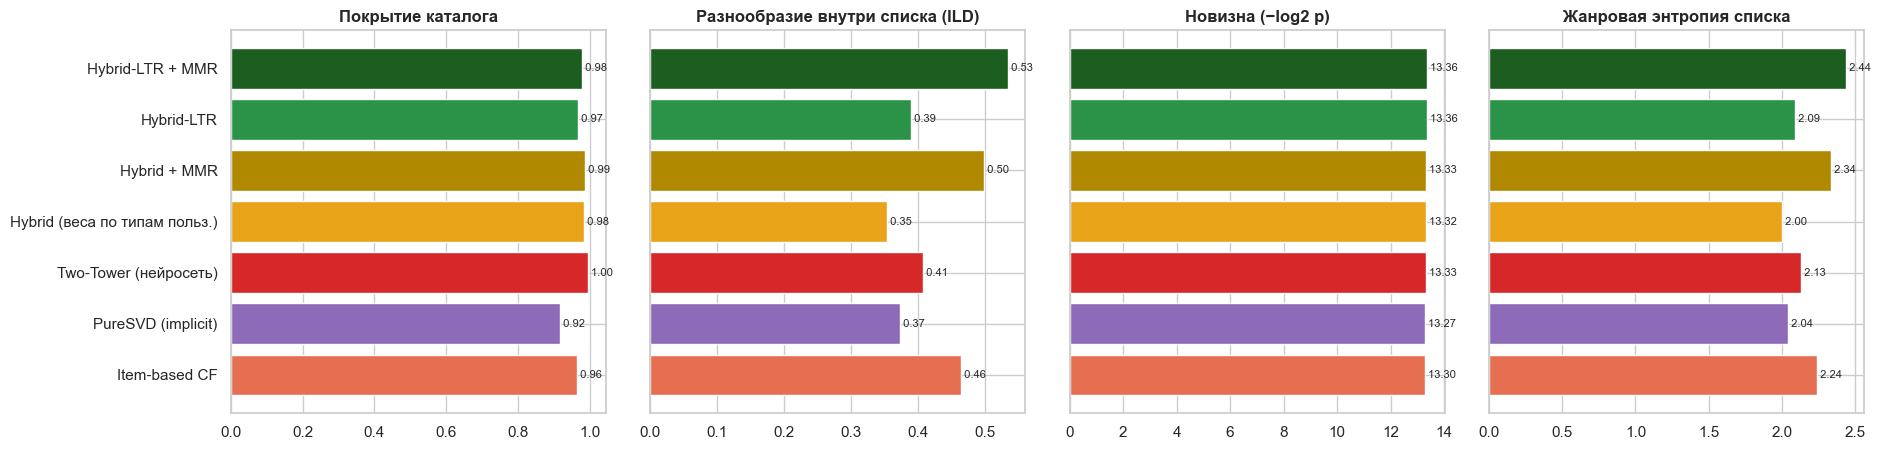

In [40]:
bey = pipe.tables["beyond"]
display(bey.loc[[N_RANDOM, N_POP, N_GPOP, N_CONTENT, N_KNN, N_SVD, N_PSVD, N_TT, N_H_SEG, N_H_MMR, N_H_LTR, N_H_LTR_MMR]].style.format("{:.3f}"))
fig = P.plot_beyond(bey, [N_KNN, N_PSVD, N_TT, N_H_SEG, N_H_MMR, N_H_LTR, N_H_LTR_MMR], 10); plt.show()

### 5.7 Вклад компонентов гибрида (ablation, общие веса)
Для каждого варианта состав компонентов меняется, веса **заново оптимизируются на validation**, качество измеряется на test.
Строки «только модели из ДЗ №1» и «ДЗ №1 + нейросеть» отвечают на главный вопрос продвинутой части: **что даёт нейросеть сверх классики**.

,nDCG@10,компонент,Δ к полному
вариант,,,
все компоненты,0.2343,7,+0.0000
без knn,0.2148,6,-0.0194
без content,0.2327,6,-0.0015
без svd,0.2342,6,-0.0001
без psvd,0.2348,6,+0.0005
без tt,0.2235,6,-0.0108
без pop,0.2333,6,-0.0010
без gpop,0.2348,6,+0.0005
"только модели из ДЗ №1 (knn, content, svd, pop)",0.2233,4,-0.0109


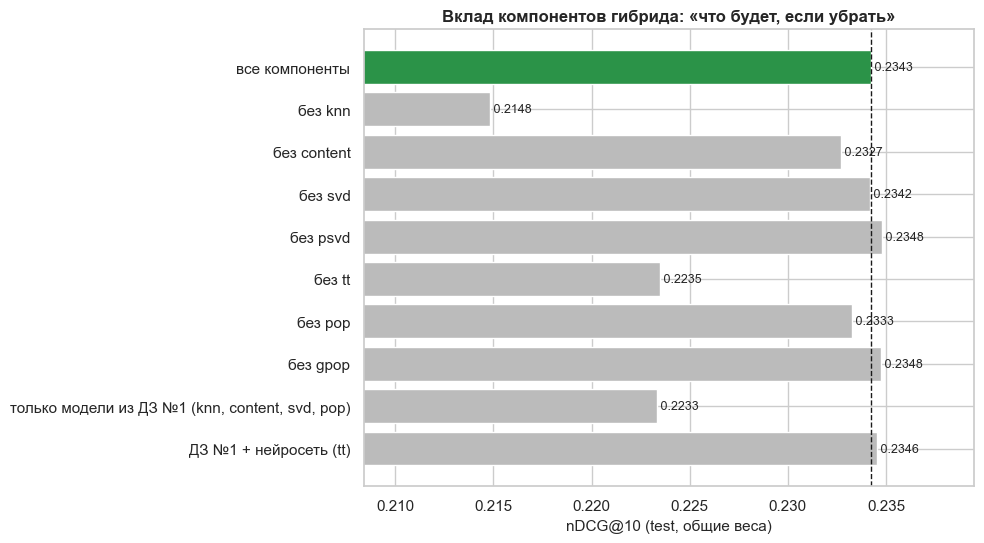

In [41]:
ca = pipe.tables["component_ablation"]
display(ca.style.format({"nDCG@10": "{:.4f}", "Δ к полному": "{:+.4f}"}))
fig = P.plot_component_ablation(ca); plt.show()

## 6. Нейросеть Two-Tower: эффективность против классики

### 6.1 Что выучила сеть
Эмбеддинги книг из башни книг: проверим, что «совместное пространство» осмысленно. Ожидание: близкими окажутся книги, которые любит **одна и та же аудитория** (жанр, тематика), а проекция на плоскость сгруппируется по жанрам. В отличие от Item-CF сеть не обязана ставить рядом тома одной серии — для этого нужны прямые совместные чтения.

**Ближайшие в пространстве Two-Tower к «Harry Potter and the Sorcerer's Stone (Harry Potter, #1)»:**

,title,authors,cos
0,The Hobbit,J.R.R. Tolkien,0.993
1,The Great Gatsby,F. Scott Fitzgerald,0.989
2,"The Girl with the Dragon Tattoo (Millennium, #1)","Stieg Larsson, Reg Keeland",0.989
3,"The Fellowship of the Ring (The Lord of the Rings, #1)",J.R.R. Tolkien,0.989
4,The Lovely Bones,Alice Sebold,0.988
5,To Kill a Mockingbird,Harper Lee,0.987


**Ближайшие в пространстве Two-Tower к «Pride and Prejudice»:**

,title,authors,cos
0,Jane Eyre,"Charlotte Brontë, Michael Mason",0.992
1,The Diary of a Young Girl,"Anne Frank, Eleanor Roosevelt, B.M. Mooyaart-Doubleday",0.992
2,Anna Karenina,"Leo Tolstoy, Louise Maude, Leo Tolstoj, Aylmer Maude",0.989
3,The Catcher in the Rye,J.D. Salinger,0.986
4,Sense and Sensibility,"Jane Austen, Tony Tanner, Ros Ballaster",0.986
5,The Joy Luck Club,Amy Tan,0.985


**Ближайшие в пространстве Two-Tower к «The Hunger Games (The Hunger Games, #1)»:**

,title,authors,cos
0,"Harry Potter and the Sorcerer's Stone (Harry Potter, #1)","J.K. Rowling, Mary GrandPré",0.983
1,"The Girl with the Dragon Tattoo (Millennium, #1)","Stieg Larsson, Reg Keeland",0.981
2,Life of Pi,Yann Martel,0.981
3,The Lovely Bones,Alice Sebold,0.981
4,The Great Gatsby,F. Scott Fitzgerald,0.978
5,The Time Traveler's Wife,Audrey Niffenegger,0.977


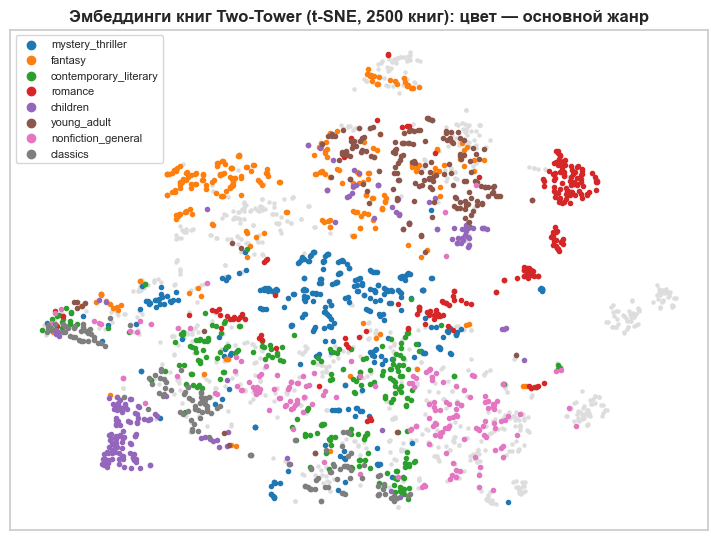

In [42]:
tt = pipe.zoo_outer.models["tt"]
V = tt.item_vectors
d = pipe.data
def nearest_tt(book_id, n=6):
    j = d.book_index(book_id)
    s = V @ V[j]; s[j] = -1
    top = np.argsort(-s)[:n]
    return d.books.iloc[top][["title", "authors"]].assign(cos=s[top].round(3)).reset_index(drop=True)
for q in ["Harry Potter and the Sorcerer", "Pride and Prejudice", "The Hunger Games"]:
    b = d.books[d.books.title.str.contains(q, regex=False)].iloc[0]
    md(f"**Ближайшие в пространстве Two-Tower к «{b.title}»:**"); display(nearest_tt(b.book_id))

from sklearn.manifold import TSNE
rng = np.random.default_rng(42); samp = rng.choice(d.n_items, 2500, replace=False)
dom = pipe.feat["outer"]["item"]["dominant_genre"].to_numpy()[samp]
top_g = pd.Series(dom).value_counts().index[:8]
xy = TSNE(n_components=2, perplexity=35, random_state=42, init="pca").fit_transform(V[samp])
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.scatter(xy[:, 0], xy[:, 1], s=5, c="#dddddd")
for g, col in zip(top_g, plt.cm.tab10.colors):
    m = dom == g
    ax.scatter(xy[m, 0], xy[m, 1], s=9, color=col, label=F.GENRES[g])
ax.set(title="Эмбеддинги книг Two-Tower (t-SNE, 2500 книг): цвет — основной жанр", xticks=[], yticks=[]); ax.legend(markerscale=2, fontsize=8)
plt.show()

**Что видно.** Соседи — книги «одной аудитории»: к *Pride and Prejudice* ближе всего Jane Eyre, Sense and Sensibility, Anna Karenina (классика); к Harry Potter — The Hobbit, The Fellowship of the Ring (фэнтези),
но попадаются и «универсальные хиты» (The Great Gatsby, The Lovely Bones). На t-SNE жанры образуют читаемые области (фэнтези, YA, романтика, детские книги, классика), но границы размыты. Это согласуется с результатами выше:
сеть хорошо улавливает **вкус аудитории**, но слабее Item-CF в **точных локальных связях** (серии, авторы).

### 6.2 Холодный старт книг: то, что классике недоступно
В основном сплите у всех книг есть оценки, поэтому преимущество «признаковой» башни книг там не видно. Смоделируем **появление новых книг** (как в ДЗ №1, раздел 6.3):
случайные 10 % каталога (1000 книг) объявляются новыми — **все их оценки вырезаются из train**, все модели переобучаются; в test остаются оценки этих книг.

* **Сценарий A:** ранжируем *только* 1000 новых книг — чистая способность работать с холодными книгами (случайный выбор: Recall@10 ≈ 0.01).
* **Сценарий B:** весь каталог; гибрид (общие веса) с `s` слотами для новинок против чистых Item-CF и Two-Tower.

In [43]:
pipe.free_memory()          # пулы кандидатов и признаки ранжировщика больше не нужны — освобождаем память
t0 = time.time()
cold = cold_item_experiment(pipe, frac=0.1, tt_epochs=20)
print(f"эксперимент занял {time.time() - t0:.0f} c")
md(f"**Сценарий A** (только новые книги, {cold['n_users_a']:,} пользователей):"); show(cold["table_a"])
md(f"**Сценарий B** (весь каталог, {cold['n_users_b']:,} пользователей):"); show(cold["table_b"])
tb, ta = cold["table_b"], cold["table_a"]
md(f'''**Что видно.**
* *Сценарий A:* Item-CF, SVD и PureSVD для новых книг работают на уровне случайного (Recall@10 ≈ {ta.loc['Random', 'Recall@10']:.3f}) — у книги нет ни одной оценки, нечего сравнивать.
  **Two-Tower решает холодный старт книг** (Recall@10 = {ta.loc['Two-Tower (нейросеть)', 'Recall@10']:.3f}, в {ta.loc['Two-Tower (нейросеть)', 'Recall@10'] / ta.loc['Random', 'Recall@10']:.0f} раз лучше случайного) за счёт признаков книги (жанры, TF-IDF, год, качество),
  но простая **контентная модель TF-IDF здесь сильнее** ({ta.loc['Content-based (TF-IDF)', 'Recall@10']:.3f}): в этом сценарии вся информация о книге — её текстовый профиль, а сеть учили на книгах с оценками.
* *Сценарий B (весь каталог):* чистые Item-CF и Two-Tower новинки в выдачу **не пускают** (доля новых книг в Top-10 — {tb.loc['Item-based CF', 'доля новых книг в выдаче']:.3f} и {tb.loc['Two-Tower (нейросеть)', 'доля новых книг в выдаче']:.3f}): оценки книг с историей выше.
  Гибрид без слотов почти их не видит (Recall по новым книгам {tb.loc['Hybrid, 0 слот(а) для новинок', 'Recall@10 по новым книгам']:.3f}); **слоты** (контент + нейросеть) поднимают его до {tb.loc['Hybrid, 1 слот(а) для новинок', 'Recall@10 по новым книгам']:.3f} / {tb.loc['Hybrid, 2 слот(а) для новинок', 'Recall@10 по новым книгам']:.3f} / {tb.loc['Hybrid, 3 слот(а) для новинок', 'Recall@10 по новым книгам']:.3f}
  при 1 / 2 / 3 слотах ценой небольшого снижения общего nDCG@10 ({tb.loc['Hybrid, 0 слот(а) для новинок', 'nDCG@10 (все книги)']:.4f} → {tb.loc['Hybrid, 1 слот(а) для новинок', 'nDCG@10 (все книги)']:.4f} → {tb.loc['Hybrid, 2 слот(а) для новинок', 'nDCG@10 (все книги)']:.4f} → {tb.loc['Hybrid, 3 слот(а) для новинок', 'nDCG@10 (все книги)']:.4f}).
  Разумный рабочий выбор — 1–2 слота; это управляемый параметр продукта (`Config.cold_slots`).
''')

   новых книг: 1000; релевантных оценок новых книг в test: 12,574 у 9,543 пользователей


  [two-tower] эпоха  1/20  loss=6.8066  (12 c)


  [two-tower] эпоха  2/20  loss=5.9754  (23 c)


  [two-tower] эпоха  4/20  loss=5.5834  (44 c)


  [two-tower] эпоха  6/20  loss=5.4197  (64 c)


  [two-tower] эпоха  8/20  loss=5.3080  (85 c)


... (8 outputs left out)

,Precision@10,Recall@10,nDCG@10
Random,0.0014,0.0102,0.0054
Item-based CF,0.0014,0.0102,0.0054
SVD (surprise),0.0014,0.0113,0.0053
PureSVD (implicit),0.0014,0.0103,0.0054
Content-based (TF-IDF),0.0390,0.3080,0.1978
Two-Tower (нейросеть),0.0214,0.1715,0.0902


**Сценарий B** (весь каталог, 6,000 пользователей):

,nDCG@10 (все книги),Recall@10 (все книги),Recall@10 по новым книгам,доля новых книг в выдаче
Item-based CF,0.1957,0.2436,0.0000,0.0000
Two-Tower (нейросеть),0.1502,0.1996,0.0000,0.0000
"Hybrid, 0 слот(а) для новинок",0.2094,0.2612,0.0000,0.0001
"Hybrid, 1 слот(а) для новинок",0.2074,0.2590,0.1011,0.1001
"Hybrid, 2 слот(а) для новинок",0.2054,0.2537,0.1606,0.2001
"Hybrid, 3 слот(а) для новинок",0.2014,0.2440,0.1944,0.3000


**Что видно.**
* *Сценарий A:* Item-CF, SVD и PureSVD для новых книг работают на уровне случайного (Recall@10 ≈ 0.010) — у книги нет ни одной оценки, нечего сравнивать.
  **Two-Tower решает холодный старт книг** (Recall@10 = 0.172, в 17 раз лучше случайного) за счёт признаков книги (жанры, TF-IDF, год, качество),
  но простая **контентная модель TF-IDF здесь сильнее** (0.308): в этом сценарии вся информация о книге — её текстовый профиль, а сеть учили на книгах с оценками.
* *Сценарий B (весь каталог):* чистые Item-CF и Two-Tower новинки в выдачу **не пускают** (доля новых книг в Top-10 — 0.000 и 0.000): оценки книг с историей выше.
  Гибрид без слотов почти их не видит (Recall по новым книгам 0.000); **слоты** (контент + нейросеть) поднимают его до 0.101 / 0.161 / 0.194
  при 1 / 2 / 3 слотах ценой небольшого снижения общего nDCG@10 (0.2094 → 0.2074 → 0.2054 → 0.2014).
  Разумный рабочий выбор — 1–2 слота; это управляемый параметр продукта (`Config.cold_slots`).


## 7. Сквозной пайплайн и повторный запуск на новых данных

Весь процесс — **один объект `Pipeline`** (модуль `pipeline.py`) с последовательными этапами; ноутбук выше вызывал их по очереди:

| Этап | Метод | Что делает |
|---|---|---|
| 1. Загрузка | `stage_load` | читает CSV (проверяет наличие файлов), `to_read.csv` необязателен |
| 2. Предобработка | `stage_preprocess` | чистка, ключи книг, сплиты, типы пользователей, TF-IDF, жанры, **расширенные признаки** |
| 3. Обучение | `stage_train` | подбор гиперпараметров (или загрузка `best_params.json`), обучение всех моделей на inner и outer |
| 4. Рекомендации | `stage_recommend` | пул кандидатов, оптимизация весов, MMR, ранжировщик; выдача `recommend_users` / `recommend_user` |
| 5. Оценка | `stage_evaluate` | метрики, сегменты, разнообразие, значимость, ablation |
| 6. Отчёт | `stage_report` | CSV/JSON/графики/рекомендации для всех пользователей в `outputs/` |

CLI: `python run_pipeline.py` (все этапы) — `--data-dir`, `--out`, `--fast`, `--sample-users`, `--no-tune`, `--stages`.

In [44]:
pipe.stage_report()
print(sorted(p.name for p in Path(cfg.out_dir).iterdir()))
print("время этапов, c:", {k: round(v) for k, v in pipe.timings.items()})

=== Этап 6. Сохранение результатов ===


   ⏱ report: 89.2 c


['best_params.json', 'beyond.csv', 'component_ablation.csv', 'config.json', 'feature_ablation.csv', 'feature_importance.csv', 'features', 'figures', 'hybrid_weights.json', 'metrics_summary.csv', 'mmr_tradeoff.csv', 'paired.csv', 'pool_recall.csv', 'recommendations_demo.csv', 'recommendations_top10.csv.gz', 'segments.csv', 'summary.md', 'timings.json', 'two_tower_training_curve.csv']
время этапов, c: {'load': 0, 'preprocess': 10, 'train': 768, 'recommend': 261, 'evaluate': 11450, 'report': 89}


### 7.1 Выдача рекомендаций (итоговая система)
`recommend_user(user_id)` принимает **исходный user_id**: для известного пользователя — рекомендации итоговой системы (пул → ранжировщик → MMR, прочитанное исключено),
для неизвестного (холодный старт) — неперсонализированное «популярное». Ниже: любимые книги пользователя в train → рекомендации по отдельным моделям → итог.

In [45]:
o = pipe.outer
cand = o.eval_users[(o.user_support[o.eval_users] >= 15) & (o.user_support[o.eval_users] <= 30)]
u0 = int(cand[3]); uid = int(pipe.data.user_ids[u0])
fav = o.train_df[(o.train_df.u == u0) & (o.train_df.rating == 5)].merge(pipe.data.books[["book_id", "title", "authors"]], on="book_id")
md(f"**Пользователь {uid}** ({o.user_support[u0]} оценок в train). Любимые книги (оценка 5):"); display(fav[["title", "authors"]].head(6).reset_index(drop=True))
liked_test = set(np.flatnonzero(o.rel[u0].toarray().ravel()))
for key, label in (("knn", "Item-based CF"), ("content", "Content-based"), ("tt", "Two-Tower (нейросеть)")):
    top = pipe.zoo_outer.models[key].recommend(np.array([u0]), 5, o.R_seen[[u0]])[0]
    t = pipe.data.books.iloc[top][["title", "authors"]].reset_index(drop=True); t["понравилась в test"] = ["✓" if j in liked_test else "" for j in top]
    md(f"**{label}** — top-5:"); display(t)
final = pipe.recommend_user(uid, 10)
final["понравилась в test"] = ["✓" if pipe.data.book_index(b) in liked_test else "" for b in final.book_id]
md("**Итоговая система (Hybrid-LTR + MMR)** — top-10 (✓ — книга действительно понравилась пользователю в отложенной части):"); display(final)
md("**Новый пользователь без истории** (`user_id` отсутствует в данных) → популярное:"); display(pipe.recommend_user(10**9, 5))

**Пользователь 36** (16 оценок в train). Любимые книги (оценка 5):

,title,authors
0,The Essential Rumi,"Jalaluddin Rumi, Coleman Barks"
1,"Y: The Last Man, Vol. 2: Cycles (Y: The Last Man, #2)","Brian K. Vaughan, Pia Guerra, José Marzán Jr."
2,"Y: The Last Man, Vol. 8: Kimono Dragons (Y: The Last Man, #8)","Brian K. Vaughan, Pia Guerra, Goran Sudžuka, José Marzán Jr."
3,"Y: The Last Man, Vol. 5: Ring of Truth (Y: The Last Man, #5)","Brian K. Vaughan, Pia Guerra, José Marzán Jr."
4,"Y: The Last Man, Vol. 3: One Small Step (Y: The Last Man, #3)","Brian K. Vaughan, Pia Guerra, José Marzán Jr., Paul Chadwick"
5,"Y: The Last Man, Vol. 7: Paper Dolls (Y: The Last Man, #7)","Brian K. Vaughan, Pia Guerra, Goran Sudžuka, José Marzán Jr."


**Item-based CF** — top-5:

,title,authors,понравилась в test
0,"Y: The Last Man, Vol. 4: Safeword (Y: The Last Man, #4)","Brian K. Vaughan, Pia Guerra, Goran Parlov, José Marzán Jr.",✓
1,"Y: The Last Man, Vol. 1: Unmanned","Brian K. Vaughan, Pia Guerra, José Marzán Jr.",
2,"Fables, Vol. 8: Wolves","Bill Willingham, Mark Buckingham, Steve Leialoha, Shawn McManus, A...",
3,Pride of Baghdad,"Brian K. Vaughan, Niko Henrichon",
4,"Fables, Vol. 3: Storybook Love","Bill Willingham, Mark Buckingham, Steve Leialoha, James Jean",


**Content-based** — top-5:

,title,authors,понравилась в test
0,"Y: The Last Man, Vol. 4: Safeword (Y: The Last Man, #4)","Brian K. Vaughan, Pia Guerra, Goran Parlov, José Marzán Jr.",✓
1,"Y: The Last Man, Vol. 1: Unmanned","Brian K. Vaughan, Pia Guerra, José Marzán Jr.",
2,Y: The Last Man - The Deluxe Edition Book One,"Brian K. Vaughan, Pia Guerra, José Marzán Jr., Pamela Rambo, Clem ...",
3,"Transmetropolitan, Vol. 1: Back on the Street (Transmetropolitan, #1)","Warren Ellis, Darick Robertston, Garth Ennis",
4,"Paper Girls, Vol. 1 (Paper Girls, #1)","Brian K. Vaughan, Cliff Chiang, Matthew Wilson",


... (2 outputs left out)

**Итоговая система (Hybrid-LTR + MMR)** — top-10 (✓ — книга действительно понравилась пользователю в отложенной части):

,rank,book_id,title,authors,genre,понравилась в test
0,1,1199,"Y: The Last Man, Vol. 1: Unmanned","Brian K. Vaughan, Pia Guerra, José Marzán Jr.",comics_manga,
1,2,5398,"Fables, Vol. 2: Animal Farm","Bill Willingham, Mark Buckingham, Steve Leialoha, James Jean",comics_manga,
2,3,3544,"The Walking Dead, Book One (The Walking Dead #1-12)","Robert Kirkman, Tony Moore, Charlie Adlard, Cliff Rathburn",comics_manga,
3,4,4228,"Preacher, Volume 2: Until the End of the World","Garth Ennis, Steve Dillon",comics_manga,
4,5,6249,Pride of Baghdad,"Brian K. Vaughan, Niko Henrichon",comics_manga,
5,6,7865,"The Walking Dead, Compendium 2","Robert Kirkman, Charlie Adlard",comics_manga,
6,7,4881,"Preacher, Volume 3: Proud Americans","Garth Ennis, Steve Dillon, Penn Jillette",comics_manga,
7,8,4874,"Fables, Vol. 4: March of the Wooden Soldiers","Bill Willingham, Mark Buckingham, Craig Hamilton, Steve Leialoha, ...",comics_manga,
8,9,6775,"Runaways, Vol. 1: Pride and Joy (Runaways, #1)","Brian K. Vaughan, Adrian Alphona",comics_manga,
9,10,9037,Y: The Last Man - The Deluxe Edition Book One,"Brian K. Vaughan, Pia Guerra, José Marzán Jr., Pamela Rambo, Clem ...",comics_manga,


**Новый пользователь без истории** (`user_id` отсутствует в данных) → популярное:

,rank,book_id,title,authors,genre,note
0,1,6361,There's Treasure Everywhere: A Calvin and Hobbes Collection,Bill Watterson,comics_manga,новый пользователь → популярное
1,2,6920,The Indispensable Calvin and Hobbes,Bill Watterson,comics_manga,новый пользователь → популярное
2,3,8978,The Revenge of the Baby-Sat,Bill Watterson,humor,новый пользователь → популярное
3,4,3275,"Harry Potter Boxed Set, Books 1-5 (Harry Potter, #1-5)","J.K. Rowling, Mary GrandPré",fantasy,новый пользователь → популярное
4,5,5207,The Days Are Just Packed: A Calvin and Hobbes Collection,Bill Watterson,comics_manga,новый пользователь → популярное


### 7.2 Повторный запуск всего процесса на новых данных
Пайплайн не привязан к конкретному датасету: размеры, индексы, сегменты и словари вычисляются из данных. Продемонстрируем на **«новых» данных** — отдельной папке с другим набором пользователей
(случайные 9000 пользователей, другие `user_id` со сдвигом +10⁶), запуск идёт через CLI в быстром режиме (`--fast`: меньше эпох и сеток), в отдельную папку результатов.

In [46]:
new_dir = Path("data_new_demo")
if not (new_dir / "ratings.csv").exists():
    new_dir.mkdir(exist_ok=True)
    r = pd.read_csv("data/ratings.csv")
    users = np.random.default_rng(7).choice(np.sort(r.user_id.unique()), 9000, replace=False)
    r = r[r.user_id.isin(users)].assign(user_id=lambda x: x.user_id + 1_000_000)
    r.to_csv(new_dir / "ratings.csv", index=False)
    for f in ("books.csv", "tags.csv", "book_tags.csv"):
        shutil.copy(f"data/{f}", new_dir / f)
t0 = time.time()
res = subprocess.run([sys.executable, "run_pipeline.py", "--data-dir", str(new_dir), "--out", "outputs_new_data", "--fast"], capture_output=True, text=True, encoding="utf-8")
print("\n".join(res.stdout.splitlines()[-12:])); print("код возврата:", res.returncode, f"| {time.time() - t0:.0f} c")
nd = pd.read_csv("outputs_new_data/metrics_summary.csv", index_col=0)
display(nd[["Precision@10", "Recall@10", "nDCG@10"]].round(4))
nd_ablation = pd.read_csv("outputs_new_data/component_ablation.csv", index_col=0)
md(f'''**Результат.** Пайплайн без единой правки кода прошёл все этапы на другом наборе пользователей (код возврата 0, {nd.shape[0]} моделей оценено, рекомендации и графики сохранены в `outputs_new_data/`).
Итоговая система даёт nDCG@10 = {nd.loc[N_H_LTR_MMR, 'nDCG@10']:.4f} против {nd.loc[N_KNN, 'nDCG@10']:.4f} у Item-CF ({(nd.loc[N_H_LTR_MMR, 'nDCG@10'] / nd.loc[N_KNN, 'nDCG@10'] - 1) * 100:+.0f} %). Оговорка: это быстрый режим на 9000 пользователях — в нём
нейросеть и PureSVD недообучены/недоинформированы (меньше эпох, в 6 раз меньше данных), поэтому их вклад меньше, чем в полном прогоне; для сопоставимых с разделом 5 цифр запускайте без `--fast`.''')

   без svd                                           0.1891          6      -0.0008
   без psvd                                          0.1907          6       0.0008
   без tt                                            0.1856          6      -0.0043
   без pop                                           0.1906          6       0.0008
   без gpop                                          0.1901          6       0.0003
   только модели из ДЗ №1 (knn, content, svd, pop)   0.1866          4      -0.0033
   ДЗ №1 + нейросеть (tt)                            0.1891          5      -0.0008
   ⏱ evaluate: 117.9 c
=== Этап 6. Сохранение результатов ===
   ⏱ report: 21.5 c

✓ Пайплайн завершён за 4.7 мин. Результаты: D:\Temp\claude\7a93b62e62a509a5\cea7de63-6a52-4c30-b0ca-e043dc44eb2c\scratchpad\clean_run4\outputs_new_data
код возврата: 0 | 287 c


,Precision@10,Recall@10,nDCG@10
model,,,
Random,0.0003,0.0009,0.0005
Popularity,0.0004,0.0011,0.0006
Content-based (TF-IDF),0.0364,0.1562,0.1146
Item-based CF,0.0617,0.2153,0.1754
SVD (surprise),0.0003,0.0014,0.0007
PureSVD (implicit),0.0366,0.0850,0.0702
Two-Tower (нейросеть),0.0247,0.0922,0.0625
Genre-Popularity,0.0040,0.0170,0.0101
Hybrid (равные веса),0.0543,0.1964,0.1622


**Результат.** Пайплайн без единой правки кода прошёл все этапы на другом наборе пользователей (код возврата 0, 14 моделей оценено, рекомендации и графики сохранены в `outputs_new_data/`).
Итоговая система даёт nDCG@10 = 0.2036 против 0.1754 у Item-CF (+16 %). Оговорка: это быстрый режим на 9000 пользователях — в нём
нейросеть и PureSVD недообучены/недоинформированы (меньше эпох, в 6 раз меньше данных), поэтому их вклад меньше, чем в полном прогоне; для сопоставимых с разделом 5 цифр запускайте без `--fast`.

**Замечание о новых книгах.** В «новых» данных у 46 книг меньше 5 оценок в train (в стандартном датасете таких книг нет), поэтому для них автоматически включается механизм слотов (`Config.cold_slots = 1`: одна из позиций Top-10 резервируется под новую книгу, найденную контентом и нейросетью; см. раздел 6.2). Это осознанный компромисс — небольшая цена в nDCG@10 ради показа новых книг; отключается значением `cold_slots = 0`.

## 8. Выводы

In [47]:
S = pipe.tables["summary"]
n = lambda name, m="@10", k="nDCG": S.loc[name, (k, m)]
best_single = pipe.best_single
gain = lambda a, b: (n(a) / n(b) - 1) * 100
seg = pipe.tables["segments"]
ca = pipe.tables["component_ablation"]
fa = pipe.tables["feature_ablation"]
md(f'''
### 8.1 Главные результаты (test, {len(pipe.outer.eval_users):,} пользователей, K = 10)

| Модель | Precision@10 | Recall@10 | nDCG@10 |
|---|---|---|---|
''' + "\n".join(f"| {'**'+nm+'**' if nm in (N_H_SEG, N_H_LTR_MMR, N_TT) else nm} | {n(nm,'@10','Precision'):.4f} | {n(nm,'@10','Recall'):.4f} | {n(nm):.4f} |"
              for nm in (N_RANDOM, N_POP, N_CONTENT, N_KNN, N_SVD, N_PSVD, N_TT, N_H_SEG, N_H_LTR, N_H_LTR_MMR)))


### 8.1 Главные результаты (test, 42,523 пользователей, K = 10)

| Модель | Precision@10 | Recall@10 | nDCG@10 |
|---|---|---|---|
| Random | 0.0003 | 0.0011 | 0.0006 |
| Popularity | 0.0003 | 0.0011 | 0.0007 |
| Content-based (TF-IDF) | 0.0367 | 0.1586 | 0.1167 |
| Item-based CF | 0.0724 | 0.2720 | 0.2174 |
| SVD (surprise) | 0.0006 | 0.0018 | 0.0011 |
| PureSVD (implicit) | 0.0704 | 0.2348 | 0.1825 |
| **Two-Tower (нейросеть)** | 0.0548 | 0.2244 | 0.1678 |
| **Hybrid (веса по типам польз.)** | 0.0793 | 0.2980 | 0.2380 |
| Hybrid-LTR | 0.0845 | 0.3131 | 0.2512 |
| **Hybrid-LTR + MMR** | 0.0842 | 0.3118 | 0.2484 |

In [48]:
md(f'''
* **Лучшая одиночная модель — {best_single}** (nDCG@10 = {n(best_single):.4f}). **Гибрид с оптимизированными весами по типам пользователей** даёт {n(N_H_SEG):.4f} ({gain(N_H_SEG, best_single):+.1f} % к лучшей одиночной),
  **с обучаемым ранжировщиком на расширенных признаках и MMR — {n(N_H_LTR_MMR):.4f} ({gain(N_H_LTR_MMR, best_single):+.1f} %)**. Для сравнения, гибрид из ДЗ №1 (Item-CF + Content + SVD с блендом z-оценок) давал +2.3 % к Item-CF.
* **Равные веса не работают** ({n(N_H_UNI):.4f}): слабые модели (Popularity, SVD по оценкам) портят смесь — веса нужно оптимизировать, а не усреднять «в лоб».
* **Типы пользователей важны:** разные веса для новых/обычных/активных улучшают результат относительно общих весов ({n(N_H_GLOB):.4f} → {n(N_H_SEG):.4f}).
* **Расширенные признаки окупаются:** ранжировщик на признаках — {n(N_H_LTR):.4f} против {n(N_H_SEG):.4f} у взвешенной суммы ({gain(N_H_LTR, N_H_SEG):+.1f} %); ablation показывает, какие группы работают (раздел 4.5).
* **Баланс (MMR):** λ = {pipe.lam} стоит {(1 - n(N_H_LTR_MMR)/n(N_H_LTR))*100:.1f} % nDCG@10 ({n(N_H_LTR):.4f} → {n(N_H_LTR_MMR):.4f}; для взвешенной смеси — {n(N_H_SEG):.4f} → {n(N_H_MMR):.4f}), но
  повышает разнообразие списков (ILD@10 {pipe.tables['beyond'].loc[N_H_LTR, 'ILD@10']:.3f} → {pipe.tables['beyond'].loc[N_H_LTR_MMR, 'ILD@10']:.3f}).
''')


* **Лучшая одиночная модель — Item-based CF** (nDCG@10 = 0.2174). **Гибрид с оптимизированными весами по типам пользователей** даёт 0.2380 (+9.5 % к лучшей одиночной),
  **с обучаемым ранжировщиком на расширенных признаках и MMR — 0.2484 (+14.2 %)**. Для сравнения, гибрид из ДЗ №1 (Item-CF + Content + SVD с блендом z-оценок) давал +2.3 % к Item-CF.
* **Равные веса не работают** (0.2196): слабые модели (Popularity, SVD по оценкам) портят смесь — веса нужно оптимизировать, а не усреднять «в лоб».
* **Типы пользователей важны:** разные веса для новых/обычных/активных улучшают результат относительно общих весов (0.2349 → 0.2380).
* **Расширенные признаки окупаются:** ранжировщик на признаках — 0.2512 против 0.2380 у взвешенной суммы (+5.5 %); ablation показывает, какие группы работают (раздел 4.5).
* **Баланс (MMR):** λ = 0.6 стоит 1.1 % nDCG@10 (0.2512 → 0.2484; для взвешенной смеси — 0.2380 → 0.2377), но
  повышает разнообразие списков (ILD@10 0.390 → 0.534).


### 8.2 Нейросеть Two-Tower: что она даёт

In [49]:
tt_gain = ca.loc["все компоненты", "nDCG@10"] - ca.loc["без tt", "nDCG@10"]
hw1 = ca.loc["только модели из ДЗ №1 (knn, content, svd, pop)", "nDCG@10"]
hw1tt = ca.loc["ДЗ №1 + нейросеть (tt)", "nDCG@10"]
sa, sb = cold["table_a"], cold["table_b"]
md(f'''
* **Как отдельная модель** Two-Tower (nDCG@10 = {n(N_TT):.4f}) заметно сильнее Content-based ({n(N_CONTENT):.4f}) и несопоставимо сильнее SVD по оценкам ({n(N_SVD):.4f}), но уступает PureSVD ({n(N_PSVD):.4f}) и **Item-based CF** ({n(N_KNN):.4f}):
  усреднённый вектор истории хуже ловит «локальные» связи (серии, авторы), чем прямые совместные чтения. Для новых пользователей нейросеть сильнее факторизаций (nDCG@10 {seg.loc[cfg.segment_names[0], N_TT]:.3f} против {seg.loc[cfg.segment_names[0], N_PSVD]:.3f} у PureSVD).
  Оговорка про цифры: в журнале подбора (раздел 3) nDCG ≈ 0.13 — это validation, где модели видят только 64 % оценок (`train_inner`); на test модель обучена на 80 % оценок и показывает {n(N_TT):.3f}. Сравнивать нужно внутри одного протокола.
* **В составе гибрида** нейросеть добавляет: «ДЗ №1 → ДЗ №1 + нейросеть» — nDCG@10 {hw1:.4f} → {hw1tt:.4f} ({(hw1tt/hw1-1)*100:+.1f} %); удаление нейросети из полного гибрида **снижает** nDCG@10 на {tt_gain:.4f} ({tt_gain/ca.loc['все компоненты', 'nDCG@10']*100:.1f} %).
  Это *дополняющий* сигнал: сеть ошибается иначе, чем Item-CF.
* **Холодный старт книг (раздел 6.2).** Two-Tower — единственная из «обучаемых» моделей, которая вообще работает для новых книг: Recall@10 = {sa.loc['Two-Tower (нейросеть)', 'Recall@10']:.3f} (случайный выбор — {sa.loc['Random', 'Recall@10']:.3f}; Item-CF, SVD, PureSVD — на уровне случайного).
  Но контентная модель TF-IDF в этом сценарии сильнее ({sa.loc['Content-based (TF-IDF)', 'Recall@10']:.3f}), поэтому слоты для новинок в гибриде заполняются **контентом + нейросетью**: 1 / 2 / 3 слота дают Recall по новым книгам
  {sb.loc['Hybrid, 1 слот(а) для новинок', 'Recall@10 по новым книгам']:.2f} / {sb.loc['Hybrid, 2 слот(а) для новинок', 'Recall@10 по новым книгам']:.2f} / {sb.loc['Hybrid, 3 слот(а) для новинок', 'Recall@10 по новым книгам']:.2f} против {sb.loc['Item-based CF', 'Recall@10 по новым книгам']:.2f} у чистого Item-CF.
''')


* **Как отдельная модель** Two-Tower (nDCG@10 = 0.1678) заметно сильнее Content-based (0.1167) и несопоставимо сильнее SVD по оценкам (0.0011), но уступает PureSVD (0.1825) и **Item-based CF** (0.2174):
  усреднённый вектор истории хуже ловит «локальные» связи (серии, авторы), чем прямые совместные чтения. Для новых пользователей нейросеть сильнее факторизаций (nDCG@10 0.173 против 0.114 у PureSVD).
  Оговорка про цифры: в журнале подбора (раздел 3) nDCG ≈ 0.13 — это validation, где модели видят только 64 % оценок (`train_inner`); на test модель обучена на 80 % оценок и показывает 0.168. Сравнивать нужно внутри одного протокола.
* **В составе гибрида** нейросеть добавляет: «ДЗ №1 → ДЗ №1 + нейросеть» — nDCG@10 0.2233 → 0.2346 (+5.0 %); удаление нейросети из полного гибрида **снижает** nDCG@10 на 0.0108 (4.6 %).
  Это *дополняющий* сигнал: сеть ошибается иначе, чем Item-CF.
* **Холодный старт книг (раздел 6.2).** Two-Tower — единственная из «обучаемых» моделей, которая вообще работает для новых книг: Recall@10 = 0.172 (случайный выбор — 0.010; Item-CF, SVD, PureSVD — на уровне случайного).
  Но контентная модель TF-IDF в этом сценарии сильнее (0.308), поэтому слоты для новинок в гибриде заполняются **контентом + нейросетью**: 1 / 2 / 3 слота дают Recall по новым книгам
  0.10 / 0.16 / 0.19 против 0.00 у чистого Item-CF.


### 8.3 Сильные и слабые стороны подходов

| Модель | Сильные стороны | Слабые стороны |
|---|---|---|
| **Popularity / Genre-Popularity** | мгновенна, единственный вариант для пользователя без истории; Genre-Popularity даёт грубую персонализацию по 1–2 оценкам | в этой выборке ≈ случайна (популярность «сплющена» ограничением в ≈ 100 оценок на книгу), покрытие каталога ничтожно |
| **Content-based (TF-IDF)** | не нужны чужие оценки → работает для новых книг; объяснима; находит серии и авторов | только название и теги; профиль вкуса размывается у читателей с разными интересами; ниже CF по точности |
| **Item-based CF** | лучшая точность среди одиночных моделей; использует реальные совместные чтения; объяснима («читатели X читали Y»); хватает 1–2 оценок | не работает для новых книг; память $O(\lvert I\rvert^2)$ без top-K; склонность к популярному |
| **SVD по оценкам** | точный прогноз значения оценки (RMSE), компактен | как ранжировщик Top-N бесполезен (учится только на прочитанном — MNAR); нулевые факторы у новых |
| **PureSVD** | хорошо масштабируется; на активных пользователях (≥ 20 оценок) сравним с Item-CF и даже лучше него | нужно сотни факторов (лучший результат на границе сетки — 800); слабее CF на новых и обычных пользователях; нет новых книг |
| **Two-Tower** | индуктивна (новый пользователь после 1–2 оценок), использует признаки → **холодный старт книг**, эмбеддинги → быстрый ANN-поиск, самый «дополняющий» источник в гибриде | дороже в обучении и настройке (≈ 7 мин на CPU против секунд у Item-CF); по точности уступает Item-CF и PureSVD на «локальных» связях |
| **Гибрид (веса)** | прозрачен, веса интерпретируемы, работает на всех типах пользователей, вклад каждого источника измерим | выигрыш зависит от разнообразия источников; нужно держать веса актуальными |
| **Гибрид-LTR + MMR** | использует расширенные признаки и сам решает, чему верить; лучшая точность; управляемый баланс разнообразия | сложнее в поддержке, нужен слой validation-данных для обучения, зависит от согласованности признаков train/inference |

### 8.4 Рекомендации по выбору модели
* **Новый пользователь, 0 оценок** — Popularity (+ онбординг: «выберите 2–3 любимые книги»); уже после 1–2 оценок включаются Item-CF/Two-Tower/гибрид (сегмент «новые» в таблице 5.5).
* **Пользователь с историей, ограниченные ресурсы** — Item-based CF (top-K соседи, офлайн-пересчёт): лучшее соотношение «качество/сложность» для новых и обычных пользователей; для активных (≥ 20 оценок) сопоставим по качеству PureSVD с большим числом факторов (см. 5.5).
* **Каталог часто пополняется** — Two-Tower (признаки книг) + слоты для новинок; Content-based как резерв.
* **Максимальное качество** — Hybrid-LTR + MMR: общий пул кандидатов, обучаемый ранжировщик на расширенных признаках, баланс разнообразия.
* **Не использовать** SVD по оценкам для Top-N ранжирования и Popularity как основную модель на данных с «сплющенной» популярностью.

### 8.5 Ограничения и честные оговорки
* **Нет временной метки** → случайный per-user hold-out; в реальности «будущее» труднее предсказать, абсолютные значения метрик оптимистичнее, чем при временной валидации. Доверительные интервалы — по пользователям при одном сплите.
* **Offline-метрики** считают непрочитанное нерелевантным (unobserved ≠ irrelevant): абсолютные числа занижены, сравнение моделей корректно; окончательный вердикт даёт только A/B-тест.
* **Подбор на validation, оценка на test:** веса, λ, ранжировщик и гиперпараметры подобраны без test; ранжировщик обучен на пуле моделей `train_inner`, применён к пулу моделей полного train (небольшой сдвиг распределения).
* **Выборка `ratings.csv` ограничена ≈ 100 оценками на книгу** → популярность внутри неё сглажена, выводы про Popularity нельзя переносить на полные данные.
* **Причины результатов — интерпретации** (локальная структура интересов, MNAR): согласуются с данными и ablation, но отдельных причинно-следственных экспериментов не ставилось.
* **Холодный старт книг смоделирован** случайным удалением 10 % книг, а не реальным временем появления; при выдаче модели обучены на train (для продакшена — переобучение на всех данных).

### 8.6 Соответствие критериям задания
| Критерий | Где |
|---|---|
| Гибридная система на основе моделей из ДЗ | разделы 3–4, модули `hybrid.py`, `pipeline.py` |
| Расширенные признаки пользователей и книг, взаимодействий | раздел 2, 4.5 (ablation), `features.py` |
| Стратегия балансировки | 4.1–4.4 (веса по типам пользователей, популярное + персональное, MMR, слоты для новинок) |
| Анализ эффективности гибрида, сравнение с отдельными моделями | 5.1–5.4, 5.7 |
| Сильные/слабые стороны, выводы и рекомендации | 5.5–5.6, 8.2–8.4 |
| Метрики Precision/Recall/nDCG@K, сравнительный анализ | 5.1–5.3 (+ юнит-тест метрик в разделе 5) |
| Нейросеть, интеграция, анализ | 3.2, 4 (компонент пула), 5.7, 6 |
| Сквозной пайплайн, повторный запуск на новых данных | 7, `run_pipeline.py` |